# 01 — Preprocessing CT Scan (Sample Mode + Audit Margin)

**Skripsi:** Klasifikasi Tumor Paru pada Citra CT Scan Menggunakan
DenseNet121 dan Explainable Artificial Intelligence berbasis Grad-CAM

## Ruang lingkup

Tahap ini **hanya** memvalidasi pipeline preprocessing dan **mengaudit**
kandidat margin konteks. **Tidak** ada batch crop final.

**Sengaja TIDAK dilakukan:**
- tidak mengubah label rule maupun file annotation Excel
- tidak mengubah penggunaan pylidc
- tidak menghapus data
- tidak menyentuh arsitektur DenseNet121
- tidak melakukan training, split dataset, augmentation, 5-fold cross validation
- tidak membuat Grad-CAM
- tidak mengunduh seluruh dataset

## Keputusan yang sudah dikunci

| Parameter | Nilai |
|---|---|
| Window | lung window global, `HU_MIN = -1350`, `HU_MAX = 150` |
| Adaptive / per-cluster windowing | tidak dipakai |
| Representasi 2D | satu axial slice dari crop 3D |
| Aturan slice | geometris **lower-middle**, `middle_index = (n-1)//2` |
| Konvensi bbox | `BBox_X` = baris (row), `BBox_Y` = kolom (column) |
| Framework model | TensorFlow / Keras |
| Preprocessing model | `tf.keras.applications.densenet.preprocess_input` |

## Yang sedang diaudit (belum dikunci)

`CONTEXT_MARGIN` — dievaluasi dalam **milimeter fisik** (`0/3/5/8 mm`),
dengan margin fixed-piksel (`0/16/32 px`) sebagai pembanding saja.

## ⚠️ Temuan penting tentang preprocessing DenseNet121 di Keras

`tf.keras.applications.densenet.preprocess_input` **secara internal memanggil
`imagenet_utils.preprocess_input(x, mode="torch")`**. Jadi pada DenseNet
Keras, preprocessing resmi yang benar adalah:

```
[0,1]  ->  (x - mean) / std
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]
```

**Bukan** jalur caffe/BGR (RGB→BGR lalu kurangi `[103.939, 116.779, 123.68]`).
Jalur caffe adalah `mode="caffe"` pada `imagenet_utils` umum, dan **bukan**
yang dipakai DenseNet Keras.

Konsekuensi penting: pada DenseNet Keras, angka normalisasi ImageNet
mean/std tersebut memang dipakai, jadi **tidak boleh** Reasoning seperti
"Keras memakai caffe, PyTorch memakai mean/std". Yang benar:
DenseNet Keras = mean/std ImageNet.

Verifikasi di **Cell 15** membandingkan implementasi NumPy di notebook ini
terhadap fungsi Keras yang terpasang, dan **berhenti dengan error** kalau
mengambil jalur yang salah. Status default DenseNet121 juga ditampilkan
(banyaknya parameter, bentuk input) sebagai bukti model yang dimaksud.

## 0. Cek dependency

In [1]:
# ============================================================
# CELL 0 - IMPORTS DAN PEMERIKSAAN DEPENDENCY
# ============================================================

from __future__ import annotations

import importlib
import json
import platform
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*absl.*")
os_env_tf = __import__("os").environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

try:                                    # hanya tersedia di dalam Jupyter
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)

print(f"Python    : {sys.version.split()[0]}")
print(f"Platform  : {platform.system()} {platform.release()} ({platform.machine()})")
print(f"Executable: {sys.executable}")

REQUIRED = {
    "pandas": "2.2.3",
    "numpy": "2.2.6",
    "pydicom": "3.0.1",
    "openpyxl": "3.1.5",
    "scipy": "1.14.1",
    "skimage": "0.24.0",
    "matplotlib": "3.9.4",
}
REQUIRED_MODEL = {
    "tensorflow": "2.21.0",
    "keras": "3.15.1",
}
OPTIONAL = {"idc_index": "0.12.5"}      # hanya untuk unduh sample DICOM

rows, missing, mismatched = [], [], []
for group, table in (("wajib", REQUIRED), ("model", REQUIRED_MODEL),
                     ("opsional", OPTIONAL)):
    for name, expected in table.items():
        try:
            mod = importlib.import_module(name)
            found = getattr(mod, "__version__", "tidak dilaporkan")
            status = "OK" if found == expected else "VERSI BEDA"
            if found != expected:
                mismatched.append((name, expected, found, group))
        except ImportError:
            found, status = "-", "HILANG"
            if group != "opsional":
                missing.append(name)
        rows.append((name, expected, found, status, group))

width = max(len(r[0]) for r in rows)
print(f"\n{'Paket'.ljust(width)}  {'Diharapkan':<12} {'Terpasang':<12} Status")
print("-" * (width + 44))
for name, exp, found, status, group in rows:
    print(f"{name.ljust(width)}  {exp:<12} {found:<12} {status} ({group})")

if missing or mismatched:
    print("\n" + "=" * 72 + "\nLINGKUNGAN BELUM SESUAI\n" + "=" * 72)
    if missing:
        print(f"\nPaket hilang : {', '.join(missing)}")
    for name, exp, found, group in mismatched:
        print(f"  - {name}: diharapkan {exp}, terpasang {found}  ({group})")
    print(
        "\nPerbaiki dengan environment virtual terisolasi:\n"
        "    python -m venv .venv\n"
        "    .venv/bin/python -m pip install -r requirements.txt"
    )
    raise ImportError(
        "Environment belum sesuai requirements.txt. JANGAN lanjut. "
        "Versi pin penting karena preprocessing DenseNet121 di Keras "
        "berubah beberapa kali antar versi."
    )
print("\nSemua dependensi tersedia dan versinya sama.")

Python    : 3.11.9
Platform  : Darwin 25.5.0 (arm64)
Executable: /Users/rivan/Kuliah/Skripsi/lung-nodule-classification/.venv/bin/python



Paket       Diharapkan   Terpasang    Status
------------------------------------------------------
pandas      2.2.3        2.2.3        OK (wajib)
numpy       2.2.6        2.2.6        OK (wajib)
pydicom     3.0.1        3.0.1        OK (wajib)
openpyxl    3.1.5        3.1.5        OK (wajib)
scipy       1.14.1       1.14.1       OK (wajib)
skimage     0.24.0       0.24.0       OK (wajib)
matplotlib  3.9.4        3.9.4        OK (wajib)
tensorflow  2.21.0       2.21.0       OK (model)
keras       3.15.1       3.15.1       OK (model)
idc_index   0.12.5       0.12.5       OK (opsional)

Semua dependensi tersedia dan versinya sama.


### CATATAN LINGKUNGAN — kenapa `pylidc` tidak dipakai

`pylidc` **tidak** dipasang di environment repo ini:

1. **Tidak dibutuhkan.** Preprocessing memakai master annotation yang sudah
   diekstrak ke `dataset/02_annotations/pylidc_nodules_extracted.xlsx`.
2. **Tidak bisa jalan di laptop.** `pylidc` membaca annotation dari file XML
   LIDC di `dataset/02_annotations/LIDC-XML-only/`, folder yang di-ignore Git.
3. **Incompatibility NumPy.** `pylidc 0.2.3` memakai `np.int` yang dihapus
   sejak NumPy 1.24. `scripts/03_extract_pylidc_nodules.py` memaksa
   `np.int = int` lewat monkey-patch.
4. **pydicom 3.x.** `pylidc 0.2.3` belum mendukung pydicom 3.

Konsekuensi: koordinat pada `BBox_X_*` / `BBox_Y_*` / `BBox_Z_*` berasal
dari urutan volume `pylidc` yang tidak didokumentasikan di file xlsx. Karena
itu notebook **tidak memercayai** angka tersebut, tetapi **memvalidasinya
ulang secara empiris** pada slice DICOM asli (Cell 7).

## 1. KONFIGURASI

Semua path diturunkan dari `PROJECT_ROOT`, bukan hard-code, agar notebook
portabel dari laptop ke PC Lab dengan perubahan konfigurasi seminimal mungkin.

In [2]:
# ============================================================
# CELL 1 - KONFIGURASI
# ============================================================

SAMPLE_MODE = True

# Seri utama yang dipakai untuk visualisasi representative.
SAMPLE_SERIES_UID = (
    "1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016904899083676284739"
)   # LIDC-IDRI-0188, 113 slice, 10 cluster

# ------------------------------------------------------------
# Audit margin: daftar SeriesInstanceUID yang boleh diproses
# Kosongkan [] = pakai semua seri yang DICOM-nya ada di disk.
# Di laptop: 2 seri. Di PC Lab: bisa 269 seri / 837 cluster.
# ------------------------------------------------------------
AUDIT_SERIES_UIDS = []      # [] = semua seri yang tersedia
AUDIT_MAX_SERIES = 0                   # 0 = tanpa batas
AUDIT_SAVE_TABLE = True                # simpan tabel audit ke CSV

ALLOW_SAMPLE_DOWNLOAD = False
DOWNLOAD_DRY_RUN = True

# ------------------------------------------------------------
# Path
# ------------------------------------------------------------
ANNOTATION_RELPATH = Path("dataset/02_annotations/pylidc_nodules_extracted.xlsx")
RAW_RELPATH = Path("dataset/01_raw")
FIGURE_RELPATH = Path("results/preprocessing_sample")
AUDIT_RELPATH = Path("results/preprocessing_audit")
SAMPLE_INDEX_RELPATH = Path("dataset/04_preprocessed/sample")

# ------------------------------------------------------------
# TAHAP 2 - WINDOW (DIKUNCI)
# ------------------------------------------------------------
WINDOW_HU_MIN = -1350.0
WINDOW_HU_MAX = 150.0
PRIMARY_WINDOW = "lung"
WINDOW_LEVEL = (WINDOW_HU_MIN + WINDOW_HU_MAX) / 2.0
WINDOW_WIDTH = WINDOW_HU_MAX - WINDOW_HU_MIN

# ------------------------------------------------------------
# TAHAP 3, 4, 5
# ------------------------------------------------------------
TARGET_SIZE = (224, 224)
NUM_CHANNELS = 3

FRAMEWORK = "tensorflow_keras"          # DIKUNCI
# tf.keras.applications.densenet.preprocess_input
# -> secara internal mode="torch" (mean/std ImageNet)
IMAGENET_PREPROCESSING = "keras_densenet"

# ------------------------------------------------------------
# ATURAN SLICE - DIKUNCI (geometris)
# ------------------------------------------------------------
#   middle_index = (n_slices - 1) // 2
#     n=1 -> 0   n=2 -> 0   n=3 -> 1   n=4 -> 1   n=5 -> 2   n=6 -> 2
# Ganjil -> slice tengah.  Genap -> lower-middle.
# Dipilih supaya tidak memakai heuristik berbasis intensitas CT, yang
# bukan bagian dari annotation LIDC.
SLICE_SELECTION = "geometric_lower_middle"

# ------------------------------------------------------------
# AUDIT MARGIN KONTEKS - BELUM DIKUNCI
# ------------------------------------------------------------
# Kandidat utama: milimeter fisik (dikonversi ke pixel per seri).
MARGIN_MM_CANDIDATES = (0.0, 3.0, 5.0, 8.0)
# Pembanding: margin fixed-piksel (tidak menjadi pilihan utama).
MARGIN_PX_CANDIDATES = (0, 16, 32)
# Margin dihitung pada arah in-plane saja (baris/kolom).
# Arah slice (z) memakai BBox_Z dari annotation, tidak diperluas.
MARGIN_PLANE_ONLY = True

# Ambang untuk menandai citra yang tidak informatif (diaudit, belum final).
FLAT_STD_THRESHOLD = 0.05      # std < nilai ini -> dianggap near-uniform
TOO_SMALL_PX = (32, 48, 64)    # ukuran crop < nilai ini -> dianggap terlalu kecil

# ------------------------------------------------------------
# Konvensi koordinat bbox - DIKUNCI (telah divalidasi)
# ------------------------------------------------------------
BBOX_XY_CONVENTION = "transposed"

# ------------------------------------------------------------
DISPLAY_FIGURES_INLINE = True

print("KONFIGURASI")
print("-" * 70)
print(f"SAMPLE_SERIES_UID      : {SAMPLE_SERIES_UID}")
print(f"AUDIT_SERIES_UIDS      : {AUDIT_SERIES_UIDS or 'semua yang tersedia'} "
      f"(maks {AUDIT_MAX_SERIES or 'tanpa batas'})")
print(f"WINDOW (lung, global)  : HU_MIN={WINDOW_HU_MIN}  HU_MAX={WINDOW_HU_MAX}")
print(f"  setara level/width   : level={WINDOW_LEVEL}  width={WINDOW_WIDTH}")
print(f"TARGET_SIZE            : {TARGET_SIZE}")
print(f"FRAMEWORK              : {FRAMEWORK}")
print(f"IMAGENET_PREPROCESSING : {IMAGENET_PREPROCESSING}")
print(f"SLICE_SELECTION        : {SLICE_SELECTION}  -> (n-1)//2")
print(f"MARGIN_MM_CANDIDATES   : {MARGIN_MM_CANDIDATES}")
print(f"MARGIN_PX_CANDIDATES   : {MARGIN_PX_CANDIDATES}  (pembanding)")
print(f"FLAT_STD_THRESHOLD     : {FLAT_STD_THRESHOLD}")
print(f"TOO_SMALL_PX           : {TOO_SMALL_PX}")
print(f"BBOX_XY_CONVENTION     : {BBOX_XY_CONVENTION}")
print(f"ALLOW_SAMPLE_DOWNLOAD  : {ALLOW_SAMPLE_DOWNLOAD}")

KONFIGURASI
----------------------------------------------------------------------
SAMPLE_SERIES_UID      : 1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016904899083676284739
AUDIT_SERIES_UIDS      : semua yang tersedia (maks tanpa batas)
WINDOW (lung, global)  : HU_MIN=-1350.0  HU_MAX=150.0
  setara level/width   : level=-600.0  width=1500.0
TARGET_SIZE            : (224, 224)
FRAMEWORK              : tensorflow_keras
IMAGENET_PREPROCESSING : keras_densenet
SLICE_SELECTION        : geometric_lower_middle  -> (n-1)//2
MARGIN_MM_CANDIDATES   : (0.0, 3.0, 5.0, 8.0)
MARGIN_PX_CANDIDATES   : (0, 16, 32)  (pembanding)
FLAT_STD_THRESHOLD     : 0.05
TOO_SMALL_PX           : (32, 48, 64)
BBOX_XY_CONVENTION     : transposed
ALLOW_SAMPLE_DOWNLOAD  : False


In [3]:
# ============================================================
# CELL 1.1 - PROJECT ROOT DAN PATH
# ============================================================

def find_project_root(marker: Path, start: Path | None = None) -> Path:
    base = Path(start).resolve() if start else Path.cwd().resolve()
    for candidate in [base, *base.parents]:
        if (candidate / marker).is_file():
            return candidate
    searched = "\n".join(f"  - {p}" for p in [base, *base.parents])
    raise FileNotFoundError(
        f"PROJECT_ROOT tidak ditemukan.\n"
        f"Notebook mencari folder yang memuat:\n  {marker}\n\n"
        f"Direktori yang sudah diperiksa:\n{searched}\n\n"
        f"Pastikan notebook dijalankan dari dalam repository."
    )


PROJECT_ROOT = find_project_root(ANNOTATION_RELPATH)

ANNOTATION_FILE = PROJECT_ROOT / ANNOTATION_RELPATH
RAW_DIR = PROJECT_ROOT / RAW_RELPATH
FIGURE_DIR = PROJECT_ROOT / FIGURE_RELPATH
AUDIT_DIR = PROJECT_ROOT / AUDIT_RELPATH
SAMPLE_INDEX_DIR = PROJECT_ROOT / SAMPLE_INDEX_RELPATH

print(f"PROJECT_ROOT    : {PROJECT_ROOT}")
print(f"Annotation file : {ANNOTATION_FILE.relative_to(PROJECT_ROOT)}")
print(f"Raw dir         : {RAW_DIR.relative_to(PROJECT_ROOT)}")
print(f"Audit output    : {AUDIT_DIR.relative_to(PROJECT_ROOT)}")

if not ANNOTATION_FILE.is_file():
    raise FileNotFoundError(
        f"File annotation tidak ditemukan:\n  {ANNOTATION_FILE}\n"
        f"File ini WAJIB ada di repository dan TIDAK boleh diubah."
    )
print("\nFile annotation ditemukan.")

PROJECT_ROOT    : /Users/rivan/Kuliah/Skripsi/lung-nodule-classification
Annotation file : dataset/02_annotations/pylidc_nodules_extracted.xlsx
Raw dir         : dataset/01_raw
Audit output    : results/preprocessing_audit

File annotation ditemukan.


## 2. Baca master annotation

**File ini tidak diubah, tidak ditulis ulang, dan tidak diimpor ulang dari
pylidc.** Notebook hanya membacanya sebagai sumber kebenaran koordinat.

**Label rule** (dijaga):

```
MeanMalignancy <= 2.5      -> Benign    (0)
2.5 < MeanMalignancy < 3.5 -> Exclude   (tidak dipakai untuk training)
MeanMalignancy >= 3.5      -> Malignant (1)
```

`NReaders` hanya metadata/audit, **bukan** filter.

In [4]:
# ============================================================
# CELL 2 - BACA MASTER ANNOTATION
# ============================================================

import numpy as np
import pandas as pd

pd.set_option("display.width", 210)
pd.set_option("display.max_columns", 60)

ann = pd.read_excel(ANNOTATION_FILE)

print(f"File  : {ANNOTATION_FILE.relative_to(PROJECT_ROOT)}")
print(f"Baris : {len(ann)}")
print(f"Kolom : {len(ann.columns)}\n")
for i, col in enumerate(ann.columns):
    print(f"  [{i:2}] {col}")

EXPECTED_TOTAL = 837
EXPECTED_LABELS = {"Benign": 381, "Exclude": 313, "Malignant": 143}

print("\n" + "=" * 64 + "\nPEMERIKSAAN INTEGRITAS\n" + "=" * 64)
label_counts = ann["Label"].value_counts()
for label, count in label_counts.items():
    print(f"  {label:<10} {count:>5}")

problems = []
if len(ann) != EXPECTED_TOTAL:
    problems.append(f"total baris {len(ann)} != {EXPECTED_TOTAL}")
for label, expected in EXPECTED_LABELS.items():
    actual = int(label_counts.get(label, 0))
    if actual != expected:
        problems.append(f"{label}: {actual} != {expected}")
if problems:
    print("\nPERINGATAN:")
    for p in problems:
        print(f"  - {p}")
else:
    print("\nSelaras dengan audit sebelumnya (837 / 381 / 313 / 143).")


def expected_label(mean_malignancy: float) -> str:
    if pd.isna(mean_malignancy):
        return "NO_SCORE"
    if mean_malignancy <= 2.5:
        return "Benign"
    if mean_malignancy >= 3.5:
        return "Malignant"
    return "Exclude"


mismatch = int((ann["MeanMalignancy"].map(expected_label) != ann["Label"]).sum())
print(f"\nBaris tidak cocok dengan label rule : {mismatch}")
if mismatch:
    print(ann.loc[ann["MeanMalignancy"].map(expected_label) != ann["Label"],
                  ["NoduleID", "MeanMalignancy", "Label"]])

print("\nNReaders (metadata/audit, BUKAN filter):")
print(ann["NReaders"].value_counts().sort_index().to_string())

print("\nDistribusi BBox_Z_Slices (jumlah slice crop 3D):")
print(ann["BBox_Z_Slices"].describe().round(2).to_string())
print("\nNilai yang akan dipakai untuk audit aturan slice 2/4/6 slice:")
for n in (2, 4, 6):
    print(f"  n={n}: {int((ann['BBox_Z_Slices'] == n).sum()):3d} cluster "
          f"di {ann[ann['BBox_Z_Slices'] == n]['SeriesInstanceUID'].nunique():3d} seri")

File  : dataset/02_annotations/pylidc_nodules_extracted.xlsx
Baris : 837
Kolom : 18

  [ 0] PatientID
  [ 1] StudyInstanceUID
  [ 2] SeriesInstanceUID
  [ 3] NoduleID
  [ 4] ClusterIndex
  [ 5] NReaders
  [ 6] MalignancyScores
  [ 7] MeanMalignancy
  [ 8] Label
  [ 9] LabelCode
  [10] AnnotationIDs
  [11] BBox_X_Min
  [12] BBox_X_Max
  [13] BBox_Y_Min
  [14] BBox_Y_Max
  [15] BBox_Z_Min
  [16] BBox_Z_Max
  [17] BBox_Z_Slices

PEMERIKSAAN INTEGRITAS
  Benign       381
  Exclude      313
  Malignant    143

Selaras dengan audit sebelumnya (837 / 381 / 313 / 143).

Baris tidak cocok dengan label rule : 0

NReaders (metadata/audit, BUKAN filter):
NReaders
1    262
2    159
3    152
4    260
5      2
7      1
8      1

Distribusi BBox_Z_Slices (jumlah slice crop 3D):
count    837.00
mean       5.99
std        5.91
min        1.00
25%        3.00
50%        4.00
75%        7.00
max       57.00

Nilai yang akan dipakai untuk audit aturan slice 2/4/6 slice:
  n=2: 131 cluster di  85 seri
  n=4

## 3. DICOM yang tersedia di disk

Audit margin hanya bisa berjalan pada cluster yang DICOM-nya benar-benar ada.
Sel ini membuat **daftar inventory** seluruh seri yang ditemukan, lalu
memotongnya dengan file annotation.

In [5]:
# ============================================================
# CELL 3 - INVENTORY DICOM LOKAL
# ============================================================

import os

DICOM_SUFFIXES = {".dcm", ".dicom", ""}


def discover_series(raw_dir: Path) -> dict[str, list[Path]]:
    """Petakan SeriesInstanceUID -> daftar file DICOM di bawah raw_dir."""
    found: dict[str, list[Path]] = {}
    if not raw_dir.is_dir():
        return found
    for dirpath, dirnames, filenames in os.walk(raw_dir):
        dirnames[:] = [d for d in dirnames if not d.startswith(".")]
        files = [Path(dirpath) / f for f in filenames
                 if Path(f).suffix.lower() in DICOM_SUFFIXES]
        if not files:
            continue
        uid = Path(dirpath).name
        found[uid] = sorted(files)
    return found


local_series = discover_series(RAW_DIR)
ann_uids = set(ann["SeriesInstanceUID"].astype(str).str.strip())

matched_uids = [uid for uid in local_series if uid in ann_uids]
unmatched = [uid for uid in local_series if uid not in ann_uids]

print(f"Folder DICOM       : {RAW_DIR.relative_to(PROJECT_ROOT)}")
print(f"Seri ditemukan     : {len(local_series)}")
print(f"  di luar annotation: {len(unmatched)}  "
      f"(diabaikan, bukan target audit)")
print(f"Seri bertannotation : {len(matched_uids)}")

audit_pool = list(AUDIT_SERIES_UIDS) if AUDIT_SERIES_UIDS else matched_uids
audit_pool = [uid for uid in audit_pool if uid in local_series]
if AUDIT_MAX_SERIES:
    audit_pool = audit_pool[:AUDIT_MAX_SERIES]

audit_ann = ann[ann["SeriesInstanceUID"].astype(str).str.strip().isin(audit_pool)]

print(f"\nSeri masuk audit    : {len(audit_pool)}")
print(f"Cluster masuk audit : {len(audit_ann)} "
      f"dari total {len(ann)} ({len(audit_ann) / len(ann) * 100:.1f}%)")

for uid in audit_pool:
    n_files = len(local_series[uid])
    n_clu = int((ann["SeriesInstanceUID"].astype(str).str.strip() == uid).sum())
    pid = ann.loc[ann["SeriesInstanceUID"].astype(str).str.strip() == uid,
                  "PatientID"].iloc[0]
    print(f"  {pid}  file={n_files:4d}  cluster={n_clu:3d}  {uid}")

print()
if len(audit_ann) < len(ann):
    print("=" * 70)
    print("CATATAN COVERAGE AUDIT")
    print("=" * 70)
    print(f"Audit margin hanya mencakup {len(audit_ann)} dari {len(ann)} cluster,\n"
          f"karena hanya {len(audit_pool)} dari "
          f"{ann['SeriesInstanceUID'].nunique()} seri yang DICOM-nya ada di disk.\n\n"
          f"Pada PC Lab, jalankan notebook ini setelah seluruh dataset CT\n"
          f"tersedia agar audit mencakup seluruh 837 cluster.\n"
          f"Statistik di bawah WAJIB dibaca bersama catatan coverage ini.")
    print("=" * 70)

Folder DICOM       : dataset/01_raw
Seri ditemukan     : 2
  di luar annotation: 0  (diabaikan, bukan target audit)
Seri bertannotation : 2

Seri masuk audit    : 2
Cluster masuk audit : 25 dari total 837 (3.0%)
  LIDC-IDRI-0049  file= 133  cluster= 15  1.3.6.1.4.1.14519.5.2.1.6279.6001.239358021703233250639913775427
  LIDC-IDRI-0188  file= 113  cluster= 10  1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016904899083676284739

CATATAN COVERAGE AUDIT
Audit margin hanya mencakup 25 dari 837 cluster,
karena hanya 2 dari 269 seri yang DICOM-nya ada di disk.

Pada PC Lab, jalankan notebook ini setelah seluruh dataset CT
tersedia agar audit mencakup seluruh 837 cluster.
Statistik di bawah WAJIB dibaca bersama catatan coverage ini.


## 4. Seri utama untuk visualisasi

`SAMPLE_SERIES_UID` dipakai untuk semua figure representative. Audit margin
pada Cell 12 memakai seluruh pool di atas, bukan hanya seri ini.

In [6]:
# ============================================================
# CELL 4 - PILIH SERI UTAMA
# ============================================================

sample_uid = str(SAMPLE_SERIES_UID).strip()
sample_ann = (
    ann[ann["SeriesInstanceUID"].astype(str).str.strip() == sample_uid]
    .sort_values("ClusterIndex").reset_index(drop=True)
)

if sample_uid not in local_series:
    raise FileNotFoundError(
        f"\nDICOM untuk seri utama tidak ada di disk:\n  {sample_uid}\n"
        f"Folder yang dicari: {RAW_DIR / sample_uid}\n\n"
        f"Ubah SAMPLE_SERIES_UID di Cell 1, atau unduh dengan sel Cell 4.1."
    )
if sample_ann.empty:
    raise ValueError(f"SeriesInstanceUID tidak ada di annotation: {sample_uid}")

dicom_files = local_series[sample_uid]
print(f"SeriesInstanceUID : {sample_uid}")
print(f"PatientID         : {sample_ann['PatientID'].iloc[0]}")
print(f"Jumlah cluster    : {len(sample_ann)}")
print(f"File DICOM        : {len(dicom_files)} "
      f"({sum(p.stat().st_size for p in dicom_files) / 1024**2:.1f} MB)")

print("\n" + "=" * 104)
print("NODULE CLUSTER PADA SERI UTAMA")
print("=" * 104)
display(sample_ann[[
    "PatientID", "NoduleID", "ClusterIndex", "NReaders", "MeanMalignancy", "Label",
    "BBox_X_Min", "BBox_X_Max", "BBox_Y_Min", "BBox_Y_Max",
    "BBox_Z_Min", "BBox_Z_Max", "BBox_Z_Slices",
]])

SeriesInstanceUID : 1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016904899083676284739
PatientID         : LIDC-IDRI-0188
Jumlah cluster    : 10
File DICOM        : 113 (56.7 MB)

NODULE CLUSTER PADA SERI UTAMA


,PatientID,NoduleID,ClusterIndex,NReaders,MeanMalignancy,Label,BBox_X_Min,BBox_X_Max,BBox_Y_Min,BBox_Y_Max,BBox_Z_Min,BBox_Z_Max,BBox_Z_Slices
0,LIDC-IDRI-0188,1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016...,1,1,2.00,Benign,437,444,178,185,51,52,2
1,LIDC-IDRI-0188,1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016...,2,1,2.00,Benign,433,439,184,191,52,53,2
2,LIDC-IDRI-0188,1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016...,3,1,2.00,Benign,407,414,311,318,57,57,1
3,LIDC-IDRI-0188,1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016...,4,4,3.75,Malignant,417,448,172,205,54,64,11
4,LIDC-IDRI-0188,1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016...,5,4,2.50,Benign,197,208,155,165,59,61,3
5,LIDC-IDRI-0188,1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016...,6,4,3.00,Exclude,347,362,351,365,66,68,3
6,LIDC-IDRI-0188,1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016...,7,4,2.50,Benign,383,395,222,234,69,71,3
7,LIDC-IDRI-0188,1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016...,8,2,3.50,Malignant,344,358,362,374,74,76,3
8,LIDC-IDRI-0188,1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016...,9,2,2.50,Benign,315,322,143,150,90,91,2
9,LIDC-IDRI-0188,1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016...,10,1,2.00,Benign,388,396,311,320,91,92,2


In [7]:
# ============================================================
# CELL 4.1 - UNDUH DICOM (OPSIONAL, nonaktif default)
# ============================================================

uid_list = [sample_uid]
assert len(uid_list) <= 3, "Sample mode dibatasi maksimal 3 series."

if not ALLOW_SAMPLE_DOWNLOAD:
    print("ALLOW_SAMPLE_DOWNLOAD = False -> tidak ada yang diunduh.")
else:
    from idc_index import IDCClient
    client = IDCClient.client()
    print(f"Series : {len(uid_list)}  |  ukuran : "
          f"{client.get_series_size(uid_list)} MB")
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    client.download_dicom_series(
        seriesInstanceUID=uid_list, downloadDir=str(RAW_DIR),
        dry_run=DOWNLOAD_DRY_RUN, quiet=False, show_progress_bar=True,
        source_bucket_location="gcs", dirTemplate="%SeriesInstanceUID",
    )
    print("DRY RUN selesai." if DOWNLOAD_DRY_RUN else "Download selesai.")

ALLOW_SAMPLE_DOWNLOAD = False -> tidak ada yang diunduh.


## 5. Pembaca seri DICOM

Kelas `CtSeries` menangani:
- validasi modality CT;
- pengurutan slice **menaik** berdasarkan proyeksi `ImagePositionPatient`
  onto normal slice (k = 0 paling inferior);
- pembacaan pixel on-demand per slice, sehingga audit tidak perlu memuat
  seluruh volume ke memori.

In [8]:
# ============================================================
# CELL 5 - KELAS PEMBACA CT SERIES
# ============================================================

import pydicom
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

%matplotlib inline


class CtSeries:
    """Pembaca minimal satu CT series: header sekali, pixel on-demand."""

    def __init__(self, uid: str, files: list[Path]):
        self.uid = str(uid)
        self.files = sorted(files)
        self.headers = [pydicom.dcmread(f, stop_before_pixels=True)
                        for f in self.files]

        h0 = self.headers[0]
        if str(h0.Modality).strip().upper() != "CT":
            raise ValueError(f"Modality {h0.Modality!r} bukan CT (series {uid}).")

        self.n_rows, self.n_cols = int(h0.Rows), int(h0.Columns)
        self.row_spacing, self.col_spacing = (float(v) for v in h0.PixelSpacing)
        self.slice_thickness = float(getattr(h0, "SliceThickness", 0.0) or 0.0)
        self.rescale_slope = float(getattr(h0, "RescaleSlope", 1.0))
        self.rescale_intercept = float(getattr(h0, "RescaleIntercept", 0.0))
        self.series_description = str(getattr(h0, "SeriesDescription", "") or "")
        self.patient_id = str(getattr(h0, "PatientID", "") or "")

        for key in ("ImageOrientationPatient", "PixelSpacing", "SliceThickness"):
            values = {
                (tuple(np.asarray(getattr(h, key), float).ravel())
                 if key != "SliceThickness" else (float(getattr(h, key)),))
                for h in self.headers
            }
            if len(values) != 1:
                raise ValueError(f"{key} tidak seragam pada series {uid}.")

        iop = np.asarray(h0.ImageOrientationPatient, dtype=float)
        normal = np.cross(iop[0:3], iop[3:6])
        normal = normal / np.linalg.norm(normal)
        positions = np.asarray([h.ImagePositionPatient for h in self.headers],
                               dtype=float)
        self.slice_normal = normal
        self.projections = positions @ normal
        self.order = np.argsort(self.projections, kind="stable")

        sorted_proj = self.projections[self.order]
        diffs = np.diff(sorted_proj)
        if len(diffs) and diffs.min() < -1e-6:
            raise ValueError(f"Urutan slice tidak monoton pada series {uid}.")
        self.slice_spacing_mm = float(diffs.mean()) if len(diffs) else self.slice_thickness

    # -- properti ------------------------------------------------
    @property
    def n_slices(self) -> int:
        return len(self.order)

    @property
    def pixel_size_mm(self) -> float:
        """Spacing piksel in-plane. LIDC-CT umumnya isotropic, rata-rata."""
        return float((self.row_spacing + self.col_spacing) / 2.0)

    def file_for_k(self, k: int) -> Path:
        return self.files[int(self.order[k])]

    # -- pembacaan -----------------------------------------------
    def read_hu(self, k: int) -> np.ndarray:
        """Baca satu slice ke-k (urutan terurut) sebagai Hounsfield Unit."""
        if not 0 <= k < self.n_slices:
            raise IndexError(f"slice k={k} di luar 0..{self.n_slices - 1}")
        ds = pydicom.dcmread(self.file_for_k(k))
        arr = ds.pixel_array
        if arr.dtype.itemsize > 2:
            arr = arr.astype(np.int16)
        return (arr.astype(np.float32) * self.rescale_slope
                + self.rescale_intercept)

    def describe(self) -> dict:
        return {
            "SeriesInstanceUID": self.uid,
            "PatientID": self.patient_id,
            "SeriesDescription": self.series_description,
            "n_slices": self.n_slices,
            "rows": self.n_rows, "cols": self.n_cols,
            "row_spacing_mm": self.row_spacing,
            "col_spacing_mm": self.col_spacing,
            "slice_spacing_mm": round(self.slice_spacing_mm, 4),
            "rescale_slope": self.rescale_slope,
            "rescale_intercept": self.rescale_intercept,
        }


print(f"Kelas CtSeries siap.")
print(f"\nMetadata seri utama:")
for key, value in CtSeries(sample_uid, dicom_files).describe().items():
    print(f"  {key:<24} {value}")

Kelas CtSeries siap.

Metadata seri utama:


  SeriesInstanceUID        1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016904899083676284739
  PatientID                LIDC-IDRI-0188
  SeriesDescription        Recon 2: C-A-P
  n_slices                 113
  rows                     512
  cols                     512
  row_spacing_mm           0.703125
  col_spacing_mm           0.703125
  slice_spacing_mm         2.5
  rescale_slope            1.0
  rescale_intercept        -1024.0


## 6. Konversi ke Hounsfield Unit (TAHAP 1)

```
HU = pixel_array * RescaleSlope + RescaleIntercept
```

In [9]:
# ============================================================
# CELL 6 - TAHAP 1: VOLUME HU UNTUK SERI UTAMA
# ============================================================

main_series = CtSeries(sample_uid, dicom_files)

hu_volume = np.stack([main_series.read_hu(k) for k in range(main_series.n_slices)])

n_rows, n_cols = main_series.n_rows, main_series.n_cols
row_spacing, col_spacing = main_series.row_spacing, main_series.col_spacing
slice_spacing_mm = main_series.slice_spacing_mm
iop = np.asarray(main_series.headers[0].ImageOrientationPatient, dtype=float)

print("=" * 66)
print("TAHAP 1 - VOLUME HU")
print("=" * 66)
print(f"Shape              : {hu_volume.shape}  (k, baris, kolom)")
print(f"Image size         : {n_rows} x {n_cols}")
print(f"Pixel spacing      : {row_spacing} x {col_spacing} mm")
print(f"Slice spacing      : {slice_spacing_mm:.4f} mm")
print(f"Slice thickness    : {main_series.slice_thickness:.4f} mm")
print(f"Voxel volume       : "
      f"{row_spacing * col_spacing * slice_spacing_mm:.3f} mm^3")
print(f"Rescale            : slope={main_series.rescale_slope} "
      f"intercept={main_series.rescale_intercept}")
print(f"Rentang k          : 0 (inferior) .. {main_series.n_slices - 1} (superior)")
print(f"Posisi k=0         : {main_series.projections[main_series.order][0]:.2f} mm")
print(f"Posisi k=N-1       : "
      f"{main_series.projections[main_series.order][-1]:.2f} mm")

valid = hu_volume[hu_volume > -2000]
print(f"\nHU min/max (FOV)   : {valid.min():.1f} / {valid.max():.1f}")
for p in (1, 5, 25, 50, 75, 95, 99):
    print(f"  persentil {p:>2}      : {np.percentile(valid, p):>9.1f}")
print(f"Porsi FOV valid    : {float((hu_volume > -2000).mean()) * 100:.1f}%")

if np.percentile(valid, 50) < -800:
    print("\nPERINGATAN: median HU sangat rendah. Periksa RescaleSlope/Intercept.")

TAHAP 1 - VOLUME HU
Shape              : (113, 512, 512)  (k, baris, kolom)
Image size         : 512 x 512
Pixel spacing      : 0.703125 x 0.703125 mm
Slice spacing      : 2.5000 mm
Slice thickness    : 2.5000 mm
Voxel volume       : 1.236 mm^3
Rescale            : slope=1.0 intercept=-1024.0
Rentang k          : 0 (inferior) .. 112 (superior)
Posisi k=0         : -321.92 mm
Posisi k=N-1       : -41.92 mm

HU min/max (FOV)   : -1024.0 / 3071.0


  persentil  1      :   -1005.0


  persentil  5      :    -994.0
  persentil 25      :    -738.0


  persentil 50      :     -92.0


  persentil 75      :      26.0
  persentil 95      :     165.0


  persentil 99      :     332.0
Porsi FOV valid    : 78.7%


## 7. KONVENSI KOORDINAT BBOX — dokumentasi dan validasi

### Aturan yang dipakai

```
BBox_X_Min / BBox_X_Max  ->  indeks BARIS  (row)    pada pixel_array
BBox_Y_Min / BBox_Y_Max  ->  indeks KOLOM  (column) pada pixel_array
BBox_Z_Min / BBox_Z_Max  ->  indeks SLICE  (k)      pada volume terurut
```

### Kenapa bukan `BBox_X -> kolom, `BBox_Y -> baris`

File `pylidc_nodules_extracted.xlsx` menyimpan koordinat dalam urutan
`(x, y)` keluaran `pylidc`. Angka `x` pertama pada file tersebut **bukan**
indeks kolom citra DICOM, melainkan indeks baris.

Ini diuji, bukan diasumsikan. Komentar pada
`scripts/03_extract_pylidc_nodules.py` ("X -> kolom, Y -> baris") tidak
sesuai dengan perilaku data. **File xlsx tidak diubah**; yang diperbaiki
adalah cara membacanya.

### Cara validasi

Untuk tiap cluster, bbox diproyeksikan dengan dua konvensi, lalu dihitung:

| Angka | Arti | Harapan untuk konvensi benar |
|---|---|---|
| `ring_lung` | porsi cincin sekitar bbox berisi udara paru (`-2000 < HU < -400`) | tinggi |
| `box_solid` | porsi isi bbox berupa jaringan padat (`-700 < HU < 200`) | > 0 |

Slice **di luar** rentang `BBox_Z_Min..BBox_Z_Max` dipakai sebagai kontrol.
Skor komposit = `0.5*median + 0.3*min + 0.2*proporsi(cluster > 0.3)`.
Komponen `min` penting: konvensi salah hampir selalu punya minimal satu
cluster yang jatuh sepenuhnya di luar paru.

Validasi ulang dilakukan **otomatis setiap run**, untuk seri apa pun.

In [10]:
# ============================================================
# CELL 7 - VALIDASI KONVENSI KOORDINAT BBOX
# ============================================================

from scipy import ndimage

LUNG_AIR = (-2000.0, -400.0)
NODULE_TISSUE = (-700.0, 200.0)


def map_bbox(x0, x1, y0, y1, convention: str, n_rows: int, n_cols: int):
    """BBox annotation -> (baris_min, baris_max, kolom_min, kolom_max)."""
    if convention == "standard":
        r0, r1, c0, c1 = y0, y1, x0, x1
    elif convention == "transposed":
        r0, r1, c0, c1 = x0, x1, y0, y1
    else:
        raise ValueError(
            f"konvensi tidak dikenal: {convention!r}. "
            f"Pilih 'standard' atau 'transposed'.")
    return max(0, r0), min(n_rows - 1, r1), max(0, c0), min(n_cols - 1, c1)


def build_ring_mask(shape, r0, r1, c0, c1, ring_px: int = 12):
    mask = np.zeros(shape, dtype=bool)
    mask[r0:r1 + 1, c0:c1 + 1] = True
    return ndimage.binary_dilation(mask, iterations=ring_px) & ~mask


def nodule_context_score(hu_slice, r0, r1, c0, c1, ring_mask):
    if r1 < r0 or c1 < c0:
        return 0.0, 0.0
    box = hu_slice[r0:r1 + 1, c0:c1 + 1]
    if box.size == 0:
        return 0.0, 0.0
    ring_values = (hu_slice[ring_mask] if ring_mask is not None
                   else np.array([], dtype=np.float32))
    ring_lung = (float(((ring_values > LUNG_AIR[0]) &
                        (ring_values < LUNG_AIR[1])).mean())
                 if ring_values.size else 0.0)
    box_solid = float(((box > NODULE_TISSUE[0]) &
                       (box < NODULE_TISSUE[1])).mean())
    return ring_lung, box_solid


def evaluate_convention(volume_hu, clusters, convention, n_rows, n_cols):
    """Nilai satu konvensi untuk seluruh cluster pada seri ini."""
    pad, control_stride = 3, 8
    n_slices = volume_hu.shape[0]
    ks = set()
    for _, row in clusters.iterrows():
        for k in range(max(0, int(row.BBox_Z_Min) - pad),
                       min(n_slices - 1, int(row.BBox_Z_Max) + pad) + 1):
            ks.add(k)
    ks.update(range(0, n_slices, control_stride))
    ks = sorted(ks)

    records = []
    for _, row in clusters.iterrows():
        r0, r1, c0, c1 = map_bbox(
            int(row.BBox_X_Min), int(row.BBox_X_Max),
            int(row.BBox_Y_Min), int(row.BBox_Y_Max),
            convention, n_rows, n_cols)
        z0 = max(0, min(int(row.BBox_Z_Min), n_slices - 1))
        z1 = max(z0, min(int(row.BBox_Z_Max), n_slices - 1))
        ring_mask = build_ring_mask(volume_hu.shape[1:], r0, r1, c0, c1)
        in_ann, out_ann = [], []
        for k in ks:
            res = nodule_context_score(volume_hu[k], r0, r1, c0, c1, ring_mask)
            (in_ann if z0 <= k <= z1 else out_ann).append(res)
        records.append({
            "NoduleClusterID": int(row.ClusterIndex),
            "annZ": f"{z0}-{z1}",
            "ring_in_annZ": float(np.mean([q[0] for q in in_ann])) if in_ann else 0.0,
            "box_in_annZ": float(np.mean([q[1] for q in in_ann])) if in_ann else 0.0,
            "ring_out_annZ": float(np.mean([q[0] for q in out_ann])) if out_ann else 0.0,
        })
    result = pd.DataFrame(records)
    result["skor_komposit"] = (
        0.5 * result["ring_in_annZ"].median()
        + 0.3 * result["ring_in_annZ"].min()
        + 0.2 * (result["ring_in_annZ"] > 0.3).mean())
    return result


print("=" * 100)
print("PERBANDINGAN KONVENSI KOORDINAT BBOX")
print("=" * 100)

summary = pd.DataFrame({
    conv: {
        "median ring_lung (dalam annZ)": df["ring_in_annZ"].median(),
        "min ring_lung (dalam annZ)": df["ring_in_annZ"].min(),
        "median box_solid (dalam annZ)": df["box_in_annZ"].median(),
        "median ring_lung (luar annZ)": df["ring_out_annZ"].mean(),
        "cluster ring_lung > 0.3": f"{(df['ring_in_annZ'] > 0.3).sum()}/{len(df)}",
        "SKOR KOMPOSIT": df["skor_komposit"].iloc[0],
    }
    for conv, df in {
        conv: evaluate_convention(hu_volume, sample_ann, conv, n_rows, n_cols)
        for conv in ("standard", "transposed")
    }.items()
}).T
display(summary.round(3))

DETECTED = summary["SKOR KOMPOSIT"].idxmax()
print(f"\nTerdeteksi     : {DETECTED!r}")
print(f"Terkonfigurasi : {BBOX_XY_CONVENTION!r}")
if DETECTED != BBOX_XY_CONVENTION:
    raise ValueError(
        f"KONVENSI KOORDINAT TIDAK COCOK. Data mendukung {DETECTED!r}, "
        f"konfigurasi {BBOX_XY_CONVENTION!r}. Periksa Cell 7.")
print("Konvensi cocok dengan data. Lanjut.")

detail = evaluate_convention(hu_volume, sample_ann, BBOX_XY_CONVENTION,
                             n_rows, n_cols)
display(detail.round(3))

PERBANDINGAN KONVENSI KOORDINAT BBOX


,median ring_lung (dalam annZ),min ring_lung (dalam annZ),median box_solid (dalam annZ),median ring_lung (luar annZ),cluster ring_lung > 0.3,SKOR KOMPOSIT
standard,0.381522,0.0,0.910815,0.335728,6/10,0.310761
transposed,0.839358,0.56713,0.839201,0.552909,10/10,0.789818



Terdeteksi     : 'transposed'
Terkonfigurasi : 'transposed'
Konvensi cocok dengan data. Lanjut.


,NoduleClusterID,annZ,ring_in_annZ,box_in_annZ,ring_out_annZ,skor_komposit
0,1,51-52,0.567,1.000,0.308,0.79
1,2,52-53,0.763,1.000,0.414,0.79
2,3,57-57,0.929,0.969,0.727,0.79
3,4,54-64,0.575,0.868,0.383,0.79
4,5,59-61,0.980,0.485,0.461,0.79
5,6,66-68,0.714,0.800,0.675,0.79
6,7,69-71,0.690,0.828,0.530,0.79
7,8,74-76,0.993,0.726,0.680,0.79
8,9,90-91,0.916,0.711,0.603,0.79
9,10,91-92,0.977,0.850,0.748,0.79


## 8. TAHAP 2 dan 3 — Lung windowing dan scaling ke [0, 1]

Window **DIKUNCI**, global, tanpa adaptif:

```
HU_MIN = -1350
HU_MAX = 150
```

```
TAHAP 2 (window)  : D   = clip(HU, HU_MIN, HU_MAX)
TAHAP 3 (scaling) : X01 = (D - HU_MIN) / (HU_MAX - HU_MIN)   -> [0, 1]
```

In [11]:
# ============================================================
# CELL 8 - TAHAP 2 + 3
# ============================================================

def apply_window(hu: np.ndarray, hu_min: float, hu_max: float) -> np.ndarray:
    """TAHAP 2 + TAHAP 3: windowing CT lalu scaling ke [0, 1]."""
    if hu_max <= hu_min:
        raise ValueError(f"hu_max harus > hu_min, diterima {hu_min}..{hu_max}")
    return np.clip((hu - hu_min) / (hu_max - hu_min), 0.0, 1.0).astype(np.float32)


print("=" * 70)
print("TAHAP 2 + 3 - WINDOW")
print("=" * 70)
print(f"PRIMARY_WINDOW  : {PRIMARY_WINDOW!r}  (global, tanpa adaptif)")
print(f"HU_MIN / HU_MAX : {WINDOW_HU_MIN} / {WINDOW_HU_MAX}")
print(f"level / width   : {WINDOW_LEVEL} / {WINDOW_WIDTH}  (untuk metodologi)")

windowed_volume = apply_window(hu_volume, WINDOW_HU_MIN, WINDOW_HU_MAX)
print(f"\nVolume windowed : {windowed_volume.shape} {windowed_volume.dtype}")
print(f"Rentang         : {windowed_volume.min():.3f} .. {windowed_volume.max():.3f}")

TAHAP 2 + 3 - WINDOW
PRIMARY_WINDOW  : 'lung'  (global, tanpa adaptif)
HU_MIN / HU_MAX : -1350.0 / 150.0
level / width   : -600.0 / 1500.0  (untuk metodologi)



Volume windowed : (113, 512, 512) float32
Rentang         : 0.000 .. 1.000


### 8.1 Bukti window (arsip, tidak dipakai di pipeline utama)

Mengukur berapa cluster menghasilkan citra 224×224 **seluruhnya 0**,
yaitu nodule tidak terlihat sama sekali.

| Window | Rentang HU | LIDC-IDRI-0188 | LIDC-IDRI-0049 |
|---|---|---|---|
| `nodule` (mediastinal) | -160 .. 240 | 2 dari 10 hitam | 5 dari 15 hitam |
| **`lung`** | **-1350 .. 150** | **0 dari 10** | **0 dari 15** |

In [12]:
# ============================================================
# CELL 8.1 - BUKTI PEMILIHAN WINDOW
# ============================================================

WINDOW_EVIDENCE = {
    "nodule": {"hu_min": -160.0, "hu_max": 240.0},
    "lung": {"hu_min": WINDOW_HU_MIN, "hu_max": WINDOW_HU_MAX},
}

ev_rows = []
for _, row in sample_ann.iterrows():
    r0, r1, c0, c1 = map_bbox(
        int(row.BBox_X_Min), int(row.BBox_X_Max),
        int(row.BBox_Y_Min), int(row.BBox_Y_Max),
        BBOX_XY_CONVENTION, n_rows, n_cols)
    z0 = max(0, int(row.BBox_Z_Min))
    z1 = min(hu_volume.shape[0] - 1, int(row.BBox_Z_Max))
    k = z0 + (z1 - z0) // 2
    sl = hu_volume[k][r0:r1 + 1, c0:c1 + 1]
    entry = {"NoduleClusterID": int(row.ClusterIndex),
             "HU_Min": float(sl.min()), "HU_Max": float(sl.max())}
    for name, b in WINDOW_EVIDENCE.items():
        img = apply_window(sl, **b)
        entry[f"max_{name}"] = float(img.max())
        entry[f"hitam_{name}"] = bool(img.max() <= 1e-6)
    ev_rows.append(entry)

evidence = pd.DataFrame(ev_rows)
print("=" * 76)
print("BUKTI: CITRA YANG SELURUHNYA 0 (NODULE TIDAK TERLIHAT)")
print("=" * 76)
display(evidence.round(3))

print("\nJumlah cluster dengan citra seluruhnya 0:")
for name, b in WINDOW_EVIDENCE.items():
    n = int(evidence[f"hitam_{name}"].sum())
    ids = evidence.loc[evidence[f"hitam_{name}"], "NoduleClusterID"].tolist()
    print(f"  {name:<7} (HU {b['hu_min']:.0f}..{b['hu_max']:.0f}) : {n}/{len(evidence)}"
          + (f"  -> cluster {ids}" if ids else ""))

bad = evidence.loc[evidence[f"hitam_{PRIMARY_WINDOW}"], "NoduleClusterID"].tolist()
if bad:
    raise ValueError(
        f"Window aktif {PRIMARY_WINDOW!r} membuat citra seluruhnya 0 untuk "
        f"cluster {bad}. Nodule tidak terlihat.")
print(f"\nWindow aktif {PRIMARY_WINDOW!r}: tidak ada citra kosong. Lanjut.")

BUKTI: CITRA YANG SELURUHNYA 0 (NODULE TIDAK TERLIHAT)


,NoduleClusterID,HU_Min,HU_Max,max_nodule,hitam_nodule,max_lung,hitam_lung
0,1,-629.0,-26.0,0.335,False,0.883,False
1,2,-638.0,-267.0,0.000,True,0.722,False
2,3,-715.0,-46.0,0.285,False,0.869,False
3,4,-800.0,106.0,0.665,False,0.971,False
4,5,-899.0,6.0,0.415,False,0.904,False
5,6,-789.0,48.0,0.520,False,0.932,False
6,7,-780.0,-17.0,0.357,False,0.889,False
7,8,-792.0,-10.0,0.375,False,0.893,False
8,9,-805.0,-63.0,0.243,False,0.858,False
9,10,-752.0,-266.0,0.000,True,0.723,False



Jumlah cluster dengan citra seluruhnya 0:
  nodule  (HU -160..240) : 2/10  -> cluster [2, 10]
  lung    (HU -1350..150) : 0/10

Window aktif 'lung': tidak ada citra kosong. Lanjut.


## 9. Fungsi pipeline

| Tahap | Fungsi | Keluaran |
|---|---|---|
| 1 | `CtSeries.read_hu` | HU float32 |
| 2+3 | `apply_window` | windowed HU dalam `[0, 1]` |
| 4 | `to_three_channel` | `(3, H, W)` dalam `[0, 1]` |
| 5 | `keras_densenet_preprocess_input` | siap DenseNet121 ImageNet |

### Aturan pemilihan slice (DIKUNCI, geometris)

```
middle_index = (n_slices - 1) // 2
```

| n | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| index | 0 | 0 | 1 | 1 | 2 | 2 |

Ganjil → slice tengah. Genap → **lower-middle**.

**Alasan memilih lower-middle, bukan heuristik intensitas.** Repository ini
tidak memiliki contour per-slice LIDC, hanya bounding box 3D. Sebuah proxy
berbasis intensitas CT (misalnya jumlah piksel `HU > -700`) adalah turunan
dari citra, bukan dari annotation, sehingga:
1. keputusannya bisa berubah bila window atau threshold diubah;
2. tidak dapat direproduksi hanya dari `pylidc_nodules_extracted.xlsx`.

Aturan geometris `(n-1)//2` sepenuhnya ditentukan oleh `BBox_Z_Min` dan
`BBox_Z_Max`, jadi sepenuhnya dapat direproduksi dan dapat ditulis di
metodologi tanpa penyebutan parameter tambahan.

In [13]:
# ============================================================
# CELL 9 - FUNGSI PIPELINE
# ============================================================

from skimage.transform import resize as sk_resize

# Konstanta normalisasi ImageNet.
# Untuk DenseNet di Keras, tf.keras.applications.densenet.preprocess_input
# memanggil imagenet_utils.preprocess_input(x, mode="torch"), yaitu
# mean/std ImageNet di bawah. Angka ini diverifikasi di Cell 15.
IMAGENET_MEAN_01 = (0.485, 0.456, 0.406)
IMAGENET_STD_01 = (0.229, 0.224, 0.225)
# Disimpan hanya sebagai dokumentasi jalur alternatif yang TIDAK dipakai
# DenseNet Keras (mode="caffe" pada imagenet_utils umum).
IMAGENET_MEAN_255_CAFFE = (103.939, 116.779, 123.68)


def fov_values(arr: np.ndarray) -> np.ndarray:
    values = arr[arr > -2000]
    if values.size == 0:
        raise ValueError("Tidak ada piksel di dalam FOV.")
    return values


def to_three_channel(img01: np.ndarray) -> np.ndarray:
    """TAHAP 4 - grayscale (H,W) dalam [0,1] -> (3,H,W) dalam [0,1].

    Citra CT grayscale, sedangkan DenseNet121 ImageNet menerima 3 kanal.
    Digunakan **replikasi**, bukan kanal semu: kanal 1, 2, 3 identik.
    """
    if img01.ndim != 2:
        raise ValueError(f"diharapkan citra 2D, diterima {img01.shape}")
    return np.repeat(img01[None, :, :], NUM_CHANNELS, axis=0).astype(np.float32)


def keras_densenet_preprocess_input(img01_3ch: np.ndarray) -> np.ndarray:
    """TAHAP 5 - replika tf.keras.applications.densenet.preprocess_input.

    Fungsi Keras tersebut memanggil imagenet_utils.preprocess_input(mode="torch"):
        1) input [0,1] dikalikan 255  -> [0,255]
        2) dibagi 255                -> [0,1]
        3) (x[c] - mean[c]) / std[c]  per kanal
    Langkah 1-2 saling meniadakan, jadi ekuivalen dengan langkah 3 saja.
    """
    x = img01_3ch.copy().astype(np.float32)
    for c in range(NUM_CHANNELS):
        x[c] = (x[c] - IMAGENET_MEAN_01[c]) / IMAGENET_STD_01[c]
    return x


def apply_imagenet_preprocessing(img01_3ch: np.ndarray) -> np.ndarray:
    if IMAGENET_PREPROCESSING != "keras_densenet":
        raise ValueError(
            f"IMAGENET_PREPROCESSING hanya boleh 'keras_densenet' "
            f"(framework dikunci ke TensorFlow/Keras). "
            f"Diterima: {IMAGENET_PREPROCESSING!r}")
    return keras_densenet_preprocess_input(img01_3ch)


def middle_index(n_slices: int) -> int:
    """Aturan slice geometris: (n-1)//2 -> ganjil = tengah, genap = lower-middle."""
    if n_slices < 1:
        raise ValueError(f"n_slices harus >= 1, diterima {n_slices}")
    return (n_slices - 1) // 2


def clip_range(lo: int, hi: int, limit: int) -> tuple[int, int]:
    lo = int(max(0, lo))
    hi = int(min(limit - 1, hi))
    if hi < lo:
        raise ValueError(
            f"Rentang [{lo}, {hi}] tidak valid terhadap ukuran {limit}.")
    return lo, hi


def margin_px_from_mm(mm: float, pixel_spacing_mm: float) -> int:
    """Konversi margin fisik (mm) -> jumlah piksel (dibulatkan ke atas)."""
    if pixel_spacing_mm <= 0:
        raise ValueError(f"pixel spacing tidak valid: {pixel_spacing_mm}")
    return int(np.ceil(mm / pixel_spacing_mm))


def build_crop_box(row, series: CtSeries, margin_px: int) -> dict:
    """Tentukan batas crop in-plane untuk satu cluster."""
    r0, r1, c0, c1 = map_bbox(
        int(row.BBox_X_Min), int(row.BBox_X_Max),
        int(row.BBox_Y_Min), int(row.BBox_Y_Max),
        BBOX_XY_CONVENTION, series.n_rows, series.n_cols)
    core_r0, core_r1, core_c0, core_c1 = r0, r1, c0, c1

    cr0, cr1 = clip_range(r0 - margin_px, r1 + margin_px, series.n_rows)
    cc0, cc1 = clip_range(c0 - margin_px, c1 + margin_px, series.n_cols)

    z0 = int(max(0, int(row.BBox_Z_Min)))
    z1 = int(min(series.n_slices - 1, int(row.BBox_Z_Max)))
    if z1 < z0:
        raise ValueError(f"BBox_Z tidak valid: {z0}..{z1}")
    n_z = z1 - z0 + 1
    k_rel = middle_index(n_z)

    nominal_h = (core_r1 - core_r0) + 1 + 2 * margin_px
    nominal_w = (core_c1 - core_c0) + 1 + 2 * margin_px
    actual_h = cr1 - cr0 + 1
    actual_w = cc1 - cc0 + 1

    return {
        "core_r0": core_r0, "core_r1": core_r1,
        "core_c0": core_c0, "core_c1": core_c1,
        "r0": cr0, "r1": cr1, "c0": cc0, "c1": cc1,
        "z0": z0, "z1": z1, "n_slices_z": n_z,
        "k_rel": k_rel, "k_abs": z0 + k_rel,
        "crop_h": actual_h, "crop_w": actual_w,
        "crop_h_mm": actual_h * series.row_spacing,
        "crop_w_mm": actual_w * series.col_spacing,
        "core_h": core_r1 - core_r0 + 1,
        "core_w": core_c1 - core_c0 + 1,
        "nominal_h": nominal_h, "nominal_w": nominal_w,
        "clipped": bool(actual_h != nominal_h or actual_w != nominal_w),
        "rel_core_r0": core_r0 - cr0, "rel_core_r1": core_r1 - cr0,
        "rel_core_c0": core_c0 - cc0, "rel_core_c1": core_c1 - cc0,
    }


def resize_to(img: np.ndarray, size: tuple[int, int]) -> np.ndarray:
    return sk_resize(img.astype(np.float32), size, order=1, mode="reflect",
                     anti_aliasing=True, preserve_range=True).astype(np.float32)


def run_pipeline(row, series: CtSeries, margin_px: int,
                volume_hu: np.ndarray | None = None,
                size=TARGET_SIZE) -> dict:
    """Jalankan seluruh tahap untuk satu cluster pada satu margin."""
    box = build_crop_box(row, series, margin_px)
    k = box["k_abs"]
    hu_slice = (volume_hu[k] if volume_hu is not None else series.read_hu(k))
    sl = hu_slice[box["r0"]:box["r1"] + 1, box["c0"]:box["c1"] + 1]

    windowed = apply_window(sl, WINDOW_HU_MIN, WINDOW_HU_MAX)     # tahap 2+3
    resized = resize_to(windowed, size)
    input_3ch = to_three_channel(resized)                        # tahap 4
    model_input = apply_imagenet_preprocessing(input_3ch)        # tahap 5

    core = sl[box["rel_core_r0"]:box["rel_core_r1"] + 1,
              box["rel_core_c0"]:box["rel_core_c1"] + 1]
    return {
        "box": box, "hu_slice_full": hu_slice, "hu_slice": sl,
        "windowed": windowed, "resized": resized,
        "input_3ch": input_3ch, "model_input": model_input,
        "core_hu": core,
        "upsample_factor": max(TARGET_SIZE) / max(box["crop_h"], box["crop_w"]),
        "kanal_identik": bool(np.allclose(input_3ch[0], input_3ch[1])
                              and np.allclose(input_3ch[1], input_3ch[2])),
    }


print("Fungsi pipeline siap.")
print(f"  aturan slice   : middle_index(n) = (n-1)//2  ({SLICE_SELECTION})")
for n in (1, 2, 3, 4, 5, 6):
    print(f"    n={n} -> index {middle_index(n)}")
print(f"  tahap 1        : CtSeries.read_hu")
print(f"  tahap 2+3      : apply_window({WINDOW_HU_MIN}, {WINDOW_HU_MAX}) -> [0,1]")
print(f"  tahap 4        : to_three_channel -> (3,{TARGET_SIZE[0]},{TARGET_SIZE[1]})")
print(f"  tahap 5        : keras_densenet_preprocess_input (mean/std ImageNet)")
print(f"  margin mm->px  : ceil(mm / pixel_spacing)")

Fungsi pipeline siap.
  aturan slice   : middle_index(n) = (n-1)//2  (geometric_lower_middle)
    n=1 -> index 0
    n=2 -> index 0
    n=3 -> index 1
    n=4 -> index 1
    n=5 -> index 2
    n=6 -> index 2
  tahap 1        : CtSeries.read_hu
  tahap 2+3      : apply_window(-1350.0, 150.0) -> [0,1]
  tahap 4        : to_three_channel -> (3,224,224)
  tahap 5        : keras_densenet_preprocess_input (mean/std ImageNet)
  margin mm->px  : ceil(mm / pixel_spacing)


## 10. Audit aturan slice lower-middle

Menampilkan aturan geometris untuk semua cluster pada seri utama, dan
menyorot kasus jumlah slice genap. Audit visual untuk kasus
2, 4, dan 6 slice dilakukan pada Cell 11.3 memakai seluruh pool seri yang
tersedia (bukan hanya seri utama).

In [14]:
# ============================================================
# CELL 10 - AUDIT ATURAN SLICE
# ============================================================

rows = []
for _, row in sample_ann.iterrows():
    box = build_crop_box(row, main_series, margin_px=0)
    n = box["n_slices_z"]
    rows.append({
        "NoduleClusterID": int(row.ClusterIndex),
        "n_slices": n,
        "paritas": "ganjil" if n % 2 else "GENAP",
        "k_geometris": middle_index(n),
        "k_upper": n // 2,
        "k_abs": box["k_abs"],
        "BBox_Z": f"{box['z0']}-{box['z1']}",
    })

slice_audit = pd.DataFrame(rows)
print("=" * 80)
print("AUDIT ATURAN SLICE GEOMETRIS (seri utama)")
print("=" * 80)
display(slice_audit)

print("Tabel aturan (dokumentasi):")
print(f"  {'n':>2} | {'(n-1)//2':>8} | {'n//2':>5} | status")
print("  " + "-" * 34)
for n in range(1, 9):
    k = middle_index(n)
    status = ("tengah" if n % 2 else "lower-middle")
    print(f"  {n:>2} | {k:>8} | {n // 2:>5} | {status}")

n_even = int((slice_audit["n_slices"] % 2 == 0).sum())
print(f"\nCluster dengan jumlah slice genap : {n_even}/{len(slice_audit)}")
if n_even:
    display(slice_audit[slice_audit["n_slices"] % 2 == 0])

AUDIT ATURAN SLICE GEOMETRIS (seri utama)


,NoduleClusterID,n_slices,paritas,k_geometris,k_upper,k_abs,BBox_Z
0,1,2,GENAP,0,1,51,51-52
1,2,2,GENAP,0,1,52,52-53
2,3,1,ganjil,0,0,57,57-57
3,4,11,ganjil,5,5,59,54-64
4,5,3,ganjil,1,1,60,59-61
5,6,3,ganjil,1,1,67,66-68
6,7,3,ganjil,1,1,70,69-71
7,8,3,ganjil,1,1,75,74-76
8,9,2,GENAP,0,1,90,90-91
9,10,2,GENAP,0,1,91,91-92


Tabel aturan (dokumentasi):
   n | (n-1)//2 |  n//2 | status
  ----------------------------------
   1 |        0 |     0 | tengah
   2 |        0 |     1 | lower-middle
   3 |        1 |     1 | tengah
   4 |        1 |     2 | lower-middle
   5 |        2 |     2 | tengah
   6 |        2 |     3 | lower-middle
   7 |        3 |     3 | tengah
   8 |        3 |     4 | lower-middle

Cluster dengan jumlah slice genap : 4/10


,NoduleClusterID,n_slices,paritas,k_geometris,k_upper,k_abs,BBox_Z
0,1,2,GENAP,0,1,51,51-52
1,2,2,GENAP,0,1,52,52-53
8,9,2,GENAP,0,1,90,90-91
9,10,2,GENAP,0,1,91,91-92



## 11. AUDIT MARGIN KONTEKS (reusable, belum dikunci)

`CONTEXT_MARGIN` **belum dikunci**. Nilai `0` yang dipakai pada pipeline
sample hanya **placeholder**, bukan keputusan metodologi. Audit di bawah
hanya membandingkan kandidat margin, tidak memilihnya.

Fungsi `evaluate_margin_candidates()` pada sel berikutnya adalah deliverable
tahap ini. Fungsi ini dapat dipanggil ulang di PC Lab setelah seluruh
dataset CT tersedia, **tanpa perubahan kode**.

Margin dievaluasi dalam **milimeter fisik** karena pixel spacing antar CT
berbeda. Margin fixed-piksel tetap dihitung sebagai pembanding, bukan
pilihan utama.

### Metrik per kandidat (kriteria audit)

| Metrik | Kolom di tabel audit |
|---|---|
| actual margin mm | `margin_actual_mm` (min / median / maks / std) |
| crop size pixel | `crop_h_px`, `crop_w_px`, `sisi_terpanjang_px` |
| crop size mm | `crop_h_mm`, `crop_w_mm` |
| faktor upsample | `upsample_factor` |
| persentase crop < 32 px | dihitung dari `sisi_terpanjang_px` |
| persentase crop < 48 px | dihitung dari `sisi_terpanjang_px` |
| frac_airy | `frac_airy` |
| frac_context_soft | `frac_context_soft` |
| image std | `img_std` |
| distribusi per series / pixel spacing | `SeriesInstanceUID`, `pixel_spacing_mm` |

Seluruh kriteria diverifikasi ulang secara otomatis pada Cell 11.2. Tabel
hasil **tidak pernah** memuat kolom `Label` maupun `MeanMalignancy`; fungsi
audit memverifikasi ini dan melempar error bila bocor.

### Partisi HU (khusus audit, bukan pipeline)

```
HU <= -900              udara bebas / di luar tubuh   -> frac_airy
-900 < HU <= -400       parenkim paru                 -> frac_lung
-400  < HU <= 150       jaringan lembut / nodule      -> frac_soft
HU > 150                kalsifikasi / padat           -> frac_dense
```

`frac_context_soft` = porsi jaringan yang berada **di dalam crop tetapi di
luar bbox annotation**. Inilah konteks anatomis yang ditambahkan margin, dan
inilah yang membedakan "konteks berguna" dari "background berlebihan".


In [15]:

# ============================================================
# CELL 11 - FUNGSI AUDIT MARGIN (REUSABLE)
# ============================================================
#
# evaluate_margin_candidates() adalah deliverable utama tahap ini.
# Fungsi ini dapat dipanggil ulang di PC Lab setelah seluruh dataset CT
# tersedia, tanpa perubahan kode.
#
# PEMAKAIAN (contoh untuk PC Lab):
#
#     import pandas as pd
#     from pathlib import Path
#     # definisi dari Cell 5 (CtSeries, discover_series) dan Cell 9 (pipeline)
#     ann = pd.read_excel("dataset/02_annotations/pylidc_nodules_extracted.xlsx")
#     series_index = discover_series(Path("dataset/01_raw"))
#     table, errors, cache = evaluate_margin_candidates(
#         ann, series_index,
#         margin_mm_candidates=(0.0, 3.0, 5.0, 8.0),
#         margin_px_candidates=(0, 16, 32),
#     )
#     table.to_csv("results/preprocessing_audit/margin_audit_table.csv", index=False)
#     display(summarize_by_margin(table))
#     display(summarize_by_series(table))
#
# Fungsi ini tidak melakukan unduhan, tidak menyimpan batch crop, tidak
# memakai split, dan tidak pernah memasukkan Label / MeanMalignancy.
# ============================================================

# Ambang partisi HU untuk audit. BUKAN aturan pemilihan slice.
HU_AIRY_MAX = -900.0     # HU <= -900        : udara bebas / di luar tubuh
HU_LUNG_MAX = -400.0     # -900 < HU <= -400  : parenkim paru
HU_SOFT_MAX = 150.0      # -400 < HU <= 150  : jaringan lembut / nodule
                          # HU > 150          : kalsifikasi / padat

# Kolom yang TIDAK BOLEH ada di tabel audit, supaya pemilihan margin tidak
# bisa dipengaruhi label.
FORBIDDEN_AUDIT_COLUMNS = ("Label", "LabelCode", "MeanMalignancy",
                           "MalignancyScores")


def margin_px_from_mm_factory(margin_mm, pixel_spacing_mm):
    """Konversi margin fisik (mm) -> piksel, dibulatkan ke atas."""
    if pixel_spacing_mm <= 0:
        raise ValueError(f"pixel spacing tidak valid: {pixel_spacing_mm}")
    return int(np.ceil(margin_mm / pixel_spacing_mm))


def evaluate_margin_candidates(
    annotations,
    series_index,
    series_uids=None,
    margin_mm_candidates=MARGIN_MM_CANDIDATES,
    margin_px_candidates=MARGIN_PX_CANDIDATES,
    build_series=None,
    target_size=TARGET_SIZE,
    hu_airy_max=HU_AIRY_MAX,
    hu_lung_max=HU_LUNG_MAX,
    hu_soft_max=HU_SOFT_MAX,
    progress=None,
):
    """Bandingkan kandidat margin konteks untuk cluster yang DICOM-nya ada.

    Menghitung metrik per (cluster, kandidat margin). TIDAK menyimpan citra
    sebagai dataset, TIDAK memakai label, dan TIDAK melakukan splitting.

    Parameters
    ----------
    annotations : pandas.DataFrame
        Master annotation hasil ekstraksi pylidc. Wajib punya kolom
        SeriesInstanceUID, ClusterIndex, BBox_X_Min/Max, BBox_Y_Min/Max,
        BBox_Z_Min/Max.
    series_index : dict
        SeriesInstanceUID -> list[Path] file DICOM.
    series_uids : sequence of str, optional
        Seri yang diproses. None = semua kunci `series_index`.
    margin_mm_candidates, margin_px_candidates : sequence
        Kandidat margin. Nilai mm dikonversi per seri memakai PixelSpacing
        masing-masing DICOM, sehingga konteksnya konsisten secara fisik
        antar-CT yang spacing-nya berbeda.
    build_series : callable, optional
        Factory objek seri. Default memakai CtSeries.
    progress : callable, optional
        Dipanggil dengan (i, total, uid) setelah tiap seri selesai.

    Returns
    -------
    table : pandas.DataFrame
        Satu baris per (cluster, kandidat margin). Tanpa kolom label.
    errors : list of dict
        Kegagalan per baris, agar bisa diaudit.
    cache : dict
        SeriesInstanceUID -> objek seri, dipakai ulang antar pemanggilan.
    """
    build_series = build_series or CtSeries
    if series_uids is None:
        series_uids = list(series_index)

    cache = {}
    rows = []
    errors = []
    n_total = len(series_uids)

    for i, uid in enumerate(series_uids, start=1):
        if progress:
            progress(i, n_total, uid)
        try:
            series = cache.setdefault(uid, build_series(uid, series_index[uid]))
        except Exception as exc:                            # noqa: BLE001
            errors.append({"SeriesInstanceUID": uid, "Tahap": "buka seri",
                           "Error": f"{type(exc).__name__}: {exc}"})
            continue

        clusters = annotations[
            annotations["SeriesInstanceUID"].astype(str).str.strip() == str(uid)
        ]
        px_mm = series.pixel_size_mm

        candidates = (
            [(f"{m:g} mm", margin_px_from_mm_factory(m, px_mm), "mm", float(m))
             for m in margin_mm_candidates]
            + [(f"{p} px", int(p), "px", float(p) * px_mm)
               for p in margin_px_candidates]
        )

        for _, row in clusters.iterrows():
            for label, margin_px, kind, margin_value in candidates:
                try:
                    out = run_pipeline(row, series, margin_px, size=target_size)
                except Exception as exc:                    # noqa: BLE001
                    errors.append({
                        "SeriesInstanceUID": uid,
                        "NoduleClusterID": int(row.ClusterIndex),
                        "Margin": label,
                        "Error": f"{type(exc).__name__}: {exc}"})
                    continue

                b, sl, core = out["box"], out["hu_slice"], out["core_hu"]
                img = out["resized"]
                fov = sl[sl > -2000]

                # margin fisik yang benar-benar terpakai, rerata dua sumbu.
                # crop_mm = (core_px + 2*margin_px)*spacing, sehingga
                # (crop_mm - core_mm) = 2*margin_px*spacing per sumbu; dua
                # sumbu dijumlahkan lalu dibagi 4 agar comparable dengan
                # margin yang diminta dalam mm.
                margin_actual_mm = (
                    (b["crop_h_mm"] - b["core_h"] * series.row_spacing)
                    + (b["crop_w_mm"] - b["core_w"] * series.col_spacing)) / 4.0

                # jaringan di DALAM crop tapi DI LUAR bbox annotation:
                # inilah konteks anatomis yang ditambahkan margin.
                soft = (sl > hu_lung_max) & (sl <= hu_soft_max)
                soft_core = (core > hu_lung_max) & (core <= hu_soft_max)
                n_ctx = max(1, sl.size - core.size)

                rows.append({
                    # identitas, tanpa label
                    "SeriesInstanceUID": str(uid),
                    "NoduleClusterID": int(row.ClusterIndex),
                    "pixel_spacing_mm": round(px_mm, 6),
                    "rows": series.n_rows, "cols": series.n_cols,
                    # kandidat margin
                    "Margin": label, "Margin_Jenis": kind,
                    "Margin_Nilai": margin_value, "Margin_px": margin_px,
                    # ukuran crop
                    "crop_h_px": b["crop_h"], "crop_w_px": b["crop_w"],
                    "crop_h_mm": round(b["crop_h_mm"], 2),
                    "crop_w_mm": round(b["crop_w_mm"], 2),
                    "sisi_terpanjang_px": int(max(b["crop_h"], b["crop_w"])),
                    "core_h_px": b["core_h"], "core_w_px": b["core_w"],
                    "core_max_mm": round(max(b["core_h"] * series.row_spacing,
                                             b["core_w"] * series.col_spacing), 2),
                    "upsample_factor": round(out["upsample_factor"], 3),
                    "clipped": bool(b["clipped"]),
                    "margin_actual_mm": round(margin_actual_mm, 3),
                    # aturan slice geometris
                    "n_slices_z": b["n_slices_z"], "k_abs": b["k_abs"],
                    # partisi HU pada slice terpilih
                    "frac_airy": round(float((sl <= hu_airy_max).mean()), 4),
                    "frac_lung": round(
                        float(((sl > hu_airy_max) & (sl <= hu_lung_max)).mean()), 4),
                    "frac_soft": round(float(soft.mean()), 4),
                    "frac_dense": round(float((sl > hu_soft_max).mean()), 4),
                    "core_frac_soft": round(float((core > hu_lung_max).mean()), 4),
                    "frac_context_soft": round(
                        float(soft.sum() - soft_core.sum()) / n_ctx, 4),
                    # kualitas citra
                    "img_max": round(float(img.max()), 4),
                    "img_std": round(float(img.std()), 4),
                    "img_p99": round(float(np.percentile(img, 99)), 4),
                    "is_empty": bool(img.max() <= 1e-6),
                    "is_flat": bool(img.std() < FLAT_STD_THRESHOLD),
                    "hu_min": float(fov.min()) if fov.size else float("nan"),
                    "hu_max": float(fov.max()) if fov.size else float("nan"),
                })

    table = pd.DataFrame(rows)
    leaked = [c for c in FORBIDDEN_AUDIT_COLUMNS if c in table.columns]
    if leaked:
        raise AssertionError(
            f"Tabel audit tidak boleh memuat kolom {leaked}. "
            f"Pemilihan margin harus netral terhadap label.")
    return table, errors, cache


In [16]:

# ============================================================
# CELL 11.1 - JALANKAN AUDIT (panggilan fungsi)
# ============================================================

print("=" * 88)
print("MENJALANKAN AUDIT MARGIN")
print("=" * 88)
print(f"Kandidat margin (mm) : {MARGIN_MM_CANDIDATES}")
print(f"Kandidat margin (px) : {MARGIN_PX_CANDIDATES}   (pembanding)")
print(f"Seri di pool         : {len(audit_pool)}")
print(f"Cluster di pool      : {len(audit_ann)}")
print(f"Total di annotation  : {len(ann)}")
print("Fungsi yang sama dijalankan ulang di PC Lab dengan seluruh dataset,")
print("tanpa perubahan kode, untuk mencakup seluruh 837 cluster.")
print()


def _progress(i, total, uid):
    pid = ann.loc[ann["SeriesInstanceUID"].astype(str).str.strip() == uid,
                  "PatientID"]
    label = pid.iloc[0] if not pid.empty else uid[-12:]
    print(f"  [{i}/{total}] {label} ({uid[-12:]})")


margin_audit, audit_errors, audit_series_cache = evaluate_margin_candidates(
    ann, local_series, series_uids=audit_pool, progress=_progress,
)

if audit_errors:
    print(f"\n{len(audit_errors)} baris GAGAL:")
    print(pd.DataFrame(audit_errors).head(20).to_string(index=False))

if margin_audit.empty:
    raise RuntimeError(
        "Tabel audit kosong. Periksa daftar error di bawah - "
        "kemungkinan semua pemanggilan run_pipeline gagal.")

n_clusters = margin_audit.groupby(
    ["SeriesInstanceUID", "NoduleClusterID"]).ngroups
n_spacings = margin_audit["pixel_spacing_mm"].nunique()

print()
print("-" * 88)
print(f"Seri diproses            : {len(audit_series_cache)}")
print(f"Cluster diproses         : {n_clusters}")
print(f"Baris audit              : {len(margin_audit)}")
print(f"Kandidat margin          : "
      f"{sorted(margin_audit['Margin'].unique(), key=str)}")
print(f"Nilai pixel spacing uji  : "
      f"{sorted(float(v) for v in margin_audit['pixel_spacing_mm'].unique())}")

leaked = [c for c in FORBIDDEN_AUDIT_COLUMNS if c in margin_audit.columns]
print(f"\nKolom label di tabel audit : {leaked if leaked else 'tidak ada (OK)'}")
print(f"Jumlah kolom tabel audit   : {len(margin_audit.columns)}")

AUDIT_DIR.mkdir(parents=True, exist_ok=True)
if AUDIT_SAVE_TABLE and not margin_audit.empty:
    out_csv = AUDIT_DIR / "margin_audit_table.csv"
    margin_audit.to_csv(out_csv, index=False)
    print(f"\nTabel audit disimpan ke:\n  {out_csv.relative_to(PROJECT_ROOT)}")

if len(audit_ann) < len(ann):
    print("\n" + "=" * 70)
    print("CATATAN COVERAGE - WAJIB DIBACA BERSAMA STATISTIK DI BAWAH")
    print("=" * 70)
    print(f"Audit mencakup {n_clusters} dari {len(ann)} cluster "
          f"({n_clusters / len(ann) * 100:.1f}%), karena hanya "
          f"{len(audit_pool)} dari {ann['SeriesInstanceUID'].nunique()} seri "
          f"yang DICOM-nya ada di disk.")
    print(f"Jumlah nilai pixel spacing yang teruji : {n_spacings}")
    if n_spacings < 3:
        print("CATATAN: hanya 1-2 nilai pixel spacing yang teruji, sehingga")
        print("perbandingan konsistensi margin mm vs fixed-piksel belum kuat.")
        print("Audit penuh di PC Lab WAJIB dijalankan ulang sebelum margin")
        print("final dikunci.")
    print("=" * 70)


MENJALANKAN AUDIT MARGIN
Kandidat margin (mm) : (0.0, 3.0, 5.0, 8.0)
Kandidat margin (px) : (0, 16, 32)   (pembanding)
Seri di pool         : 2
Cluster di pool      : 25
Total di annotation  : 837
Fungsi yang sama dijalankan ulang di PC Lab dengan seluruh dataset,
tanpa perubahan kode, untuk mencakup seluruh 837 cluster.

  [1/2] LIDC-IDRI-0049 (639913775427)


  [2/2] LIDC-IDRI-0188 (083676284739)

----------------------------------------------------------------------------------------
Seri diproses            : 2
Cluster diproses         : 25
Baris audit              : 175
Kandidat margin          : ['0 mm', '0 px', '16 px', '3 mm', '32 px', '5 mm', '8 mm']
Nilai pixel spacing uji  : [0.644531, 0.703125]

Kolom label di tabel audit : tidak ada (OK)
Jumlah kolom tabel audit   : 35

Tabel audit disimpan ke:
  results/preprocessing_audit/margin_audit_table.csv

CATATAN COVERAGE - WAJIB DIBACA BERSAMA STATISTIK DI BAWAH
Audit mencakup 25 dari 837 cluster (3.0%), karena hanya 2 dari 269 seri yang DICOM-nya ada di disk.
Jumlah nilai pixel spacing yang teruji : 2
CATATAN: hanya 1-2 nilai pixel spacing yang teruji, sehingga
perbandingan konsistensi margin mm vs fixed-piksel belum kuat.
Audit penuh di PC Lab WAJIB dijalankan ulang sebelum margin
final dikunci.


In [17]:

# ============================================================
# CELL 11.2 - STATISTIK AUDIT MARGIN
# ============================================================

pd.set_option("display.width", 250)


def summarize_by_margin(df):
    """Agregasi per kandidat margin. TIDAK memakai kolom label."""
    out = []
    for margin, g in df.groupby("Margin", sort=False):
        side_px = g["sisi_terpanjang_px"]
        out.append({
            "Margin": margin,
            "Jenis": g["Margin_Jenis"].iloc[0],
            "Nilai": g["Margin_Nilai"].iloc[0],
            "Jumlah": len(g),
            # --- actual margin mm ---
            "margin_aktual_mm min": g["margin_actual_mm"].min(),
            "margin_aktual_mm median": g["margin_actual_mm"].median(),
            "margin_aktual_mm maks": g["margin_actual_mm"].max(),
            "margin_aktual_mm std": g["margin_actual_mm"].std(),
            # --- crop size pixel ---
            "crop_px min": side_px.min(),
            "crop_px median": side_px.median(),
            "crop_px max": side_px.max(),
            # --- crop size mm ---
            "crop_mm min": g["crop_w_mm"].min(),
            "crop_mm median": g["crop_w_mm"].median(),
            "crop_mm max": g["crop_w_mm"].max(),
            "crop_mm std": g["crop_w_mm"].std(),
            # --- faktor upsample ---
            "upsample median": g["upsample_factor"].median(),
            "upsample p90": g["upsample_factor"].quantile(0.90),
            "upsample maks": g["upsample_factor"].max(),
            # --- crop terlalu kecil ---
            "persen_crop_lt_32px": 100.0 * float((side_px < 32).mean()),
            "persen_crop_lt_48px": 100.0 * float((side_px < 48).mean()),
            "persen_crop_lt_64px": 100.0 * float((side_px < 64).mean()),
            # --- background vs konteks ---
            "frac_airy median": g["frac_airy"].median(),
            "frac_airy p90": g["frac_airy"].quantile(0.90),
            "frac_lung median": g["frac_lung"].median(),
            "frac_context_soft median": g["frac_context_soft"].median(),
            "frac_context_soft maks": g["frac_context_soft"].max(),
            # --- kualitas citra ---
            "img_std median": g["img_std"].median(),
            "img_std p10": g["img_std"].quantile(0.10),
            "img_p99 median": g["img_p99"].median(),
            "persen_kosong": 100.0 * g["is_empty"].mean(),
            f"persen_near_uniform_std_lt_{FLAT_STD_THRESHOLD}":
                100.0 * g["is_flat"].mean(),
            # --- lain-lain ---
            "persen_clipped_tepi_citra": 100.0 * g["clipped"].mean(),
            "jumlah_pixel_spacing": g["pixel_spacing_mm"].nunique(),
        })
    res = pd.DataFrame(out)
    return res.sort_values(["Jenis", "Nilai"],
                           ascending=[True, True]).reset_index(drop=True)


def summarize_by_series(df):
    """Distribusi per seri dan per nilai pixel spacing.

    Penting untuk memeriksa apakah simpulan margin tetap berlaku pada CT
    dengan pixel spacing berbeda.
    """
    rows = []
    for (uid, spacing, margin), g in df.groupby(
            ["SeriesInstanceUID", "pixel_spacing_mm", "Margin"], sort=False):
        side_px = g["sisi_terpanjang_px"]
        rows.append({
            "SeriesInstanceUID": uid,
            "pixel_spacing_mm": spacing,
            "rows_x_cols": f"{int(g['rows'].iloc[0])}x{int(g['cols'].iloc[0])}",
            "Margin": margin,
            "Jenis": g["Margin_Jenis"].iloc[0],
            "Jumlah": len(g),
            "margin_aktual_mm median": g["margin_actual_mm"].median(),
            "crop_px median": side_px.median(),
            "crop_mm median": g["crop_w_mm"].median(),
            "upsample median": g["upsample_factor"].median(),
            "persen_crop_lt_32px": 100.0 * float((side_px < 32).mean()),
            "persen_crop_lt_48px": 100.0 * float((side_px < 48).mean()),
            "frac_airy median": g["frac_airy"].median(),
            "frac_context_soft median": g["frac_context_soft"].median(),
            "img_std median": g["img_std"].median(),
        })
    res = pd.DataFrame(rows)
    return res.sort_values(["pixel_spacing_mm", "Jenis", "Margin"],
                           ascending=[True, True, True]).reset_index(drop=True)


summary_mm = summarize_by_margin(margin_audit[margin_audit.Margin_Jenis == "mm"])
summary_px = summarize_by_margin(margin_audit[margin_audit.Margin_Jenis == "px"])
summary_all = summarize_by_margin(margin_audit)

print("=" * 132)
print("AUDIT MARGIN - MILIMETER FISIK (kandidat utama)")
print("=" * 132)
display(summary_mm.set_index("Margin").T.round(3))

print()
print("=" * 132)
print("AUDIT MARGIN - FIXED PIXEL (pembanding)")
print("=" * 132)
display(summary_px.set_index("Margin").T.round(3))

# ------------------------------------------------------------------
# Verifikasi bahwa seluruh kriteria audit benar-benar dihasilkan
# ------------------------------------------------------------------
print()
print("=" * 132)
print("VERIFIKASI KRITERIA AUDIT")
print("=" * 132)

REQUIRED_CRITERIA = [
    ("actual margin mm", ["margin_aktual_mm min", "margin_aktual_mm median",
                          "margin_aktual_mm maks", "margin_aktual_mm std"]),
    ("crop size pixel", ["crop_px min", "crop_px median", "crop_px max"]),
    ("crop size mm", ["crop_mm min", "crop_mm median", "crop_mm max"]),
    ("upsample factor", ["upsample median", "upsample p90", "upsample maks"]),
    ("percentage crop <32 px", ["persen_crop_lt_32px"]),
    ("percentage crop <48 px", ["persen_crop_lt_48px"]),
    ("frac_airy", ["frac_airy median", "frac_airy p90"]),
    ("frac_context_soft", ["frac_context_soft median",
                           "frac_context_soft maks"]),
    ("image std", ["img_std median", "img_std p10"]),
]

print(f"{'kriteria':<26} {'kolom':<58} status")
print("-" * 132)
missing_criteria = []
for name, cols in REQUIRED_CRITERIA:
    absent = [c for c in cols if c not in summary_all.columns]
    if absent:
        missing_criteria.extend(absent)
    print(f"{name:<26} {', '.join(cols):<58} "
          f"{'ADA' if not absent else 'HILANG: ' + str(absent)}")

series_cols = ["SeriesInstanceUID", "pixel_spacing_mm"]
series_ok = all(c in margin_audit.columns for c in series_cols)
print(f"{'distribusi per series':<26} {str(series_cols):<58} "
      f"{'ADA' if series_ok else 'HILANG'}")
print(f"{'tanpa kolom label':<26} {str(list(FORBIDDEN_AUDIT_COLUMNS)):<58} "
      f"{'OK' if not leaked else 'GAGAL'}")

if missing_criteria or not series_ok or leaked:
    raise AssertionError(
        f"Kriteria audit belum lengkap: {missing_criteria}, "
        f"series_ok={series_ok}, leaked={leaked}")
print("\nSeluruh kriteria audit terpenuhi.")


AUDIT MARGIN - MILIMETER FISIK (kandidat utama)


Margin,0 mm,3 mm,5 mm,8 mm
Jenis,mm,mm,mm,mm
Nilai,0.0,3.0,5.0,8.0
Jumlah,25,25,25,25
margin_aktual_mm min,0.0,3.223,5.156,8.379
margin_aktual_mm median,0.0,3.223,5.156,8.379
margin_aktual_mm maks,0.0,3.516,5.625,8.438
margin_aktual_mm std,0.0,0.1465,0.2345,0.0295
crop_px min,8,18,24,32
crop_px median,13.0,23.0,29.0,39.0
crop_px max,34,44,50,58



AUDIT MARGIN - FIXED PIXEL (pembanding)


Margin,0 px,16 px,32 px
Jenis,px,px,px
Nilai,0.0,10.312496,20.624992
Jumlah,25,25,25
margin_aktual_mm min,0.0,10.312,20.625
margin_aktual_mm median,0.0,10.312,20.625
margin_aktual_mm maks,0.0,11.25,22.5
margin_aktual_mm std,0.0,0.469,0.9375
crop_px min,8,40,72
crop_px median,13.0,45.0,77.0
crop_px max,34,66,98



VERIFIKASI KRITERIA AUDIT
kriteria                   kolom                                                      status
------------------------------------------------------------------------------------------------------------------------------------
actual margin mm           margin_aktual_mm min, margin_aktual_mm median, margin_aktual_mm maks, margin_aktual_mm std ADA
crop size pixel            crop_px min, crop_px median, crop_px max                   ADA
crop size mm               crop_mm min, crop_mm median, crop_mm max                   ADA
upsample factor            upsample median, upsample p90, upsample maks               ADA
percentage crop <32 px     persen_crop_lt_32px                                        ADA
percentage crop <48 px     persen_crop_lt_48px                                        ADA
frac_airy                  frac_airy median, frac_airy p90                            ADA
frac_context_soft          frac_context_soft median, frac_context_soft maks          

DISTRIBUSI PER SERI / PIXEL SPACING


,SeriesInstanceUID,pixel_spacing_mm,rows_x_cols,Margin,Jenis,Jumlah,margin_aktual_mm median,crop_px median,crop_mm median,upsample median,persen_crop_lt_32px,persen_crop_lt_48px,frac_airy median,frac_context_soft median,img_std median
0,1.3.6.1.4.1.14519.5.2.1.6279.6001.239358021703...,0.645,512x512,0 mm,mm,15,0.000,14.0,7.730,16.000,100.0,100.0,0.117,0.000,0.150
1,1.3.6.1.4.1.14519.5.2.1.6279.6001.239358021703...,0.645,512x512,3 mm,mm,15,3.223,24.0,14.180,9.333,80.0,100.0,0.323,0.009,0.132
2,1.3.6.1.4.1.14519.5.2.1.6279.6001.239358021703...,0.645,512x512,5 mm,mm,15,5.156,30.0,18.050,7.467,60.0,100.0,0.401,0.014,0.122
3,1.3.6.1.4.1.14519.5.2.1.6279.6001.239358021703...,0.645,512x512,8 mm,mm,15,8.379,40.0,24.490,5.600,0.0,80.0,0.453,0.026,0.109
4,1.3.6.1.4.1.14519.5.2.1.6279.6001.239358021703...,0.645,512x512,0 px,px,15,0.000,14.0,7.730,16.000,100.0,100.0,0.117,0.000,0.150
5,1.3.6.1.4.1.14519.5.2.1.6279.6001.239358021703...,0.645,512x512,16 px,px,15,10.312,46.0,28.360,4.870,0.0,60.0,0.422,0.031,0.111
6,1.3.6.1.4.1.14519.5.2.1.6279.6001.239358021703...,0.645,512x512,32 px,px,15,20.625,78.0,48.980,2.872,0.0,0.0,0.415,0.142,0.249
7,1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016...,0.703,512x512,0 mm,mm,10,0.000,11.0,7.380,20.534,90.0,100.0,0.000,0.000,0.146
8,1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016...,0.703,512x512,3 mm,mm,10,3.516,21.0,14.415,10.691,90.0,100.0,0.000,0.073,0.131
9,1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016...,0.703,512x512,5 mm,mm,10,5.625,27.0,18.630,8.308,80.0,90.0,0.000,0.115,0.127



Ringkasan per nilai pixel spacing (semua seri digabung):


,pixel_spacing_mm,Margin_Jenis,Margin_Nilai,n_cluster,margin_aktual_mm_median,margin_aktual_mm_std,upsample_median,crop_px_median,frac_airy_median,frac_context_soft_median,img_std_median
0,0.645,mm,0.000,15,0.000,0.0,16.000,14.0,0.117,0.000,0.150
7,0.703,mm,0.000,10,0.000,0.0,20.534,11.0,0.000,0.000,0.146
1,0.645,mm,3.000,15,3.223,0.0,9.333,24.0,0.323,0.009,0.132
8,0.703,mm,3.000,10,3.516,0.0,10.691,21.0,0.000,0.073,0.131
2,0.645,mm,5.000,15,5.156,0.0,7.467,30.0,0.401,0.014,0.122
9,0.703,mm,5.000,10,5.625,0.0,8.308,27.0,0.000,0.115,0.127
3,0.645,mm,8.000,15,8.379,0.0,5.600,40.0,0.453,0.026,0.109
10,0.703,mm,8.000,10,8.438,0.0,6.405,35.0,0.000,0.155,0.169
4,0.645,px,0.000,15,0.000,0.0,16.000,14.0,0.117,0.000,0.150
11,0.703,px,0.000,10,0.000,0.0,20.534,11.0,0.000,0.000,0.146



Nilai pixel spacing yang teruji: [0.644531, 0.703125] (2 nilai)
PERINGATAN: kurang dari 3 nilai pixel spacing. Perbandingan
konsistensi margin mm vs fixed-piksel belum kuat dan TIDAK cukup
untuk mengunci margin final. Audit penuh di PC Lab wajib dijalankan.


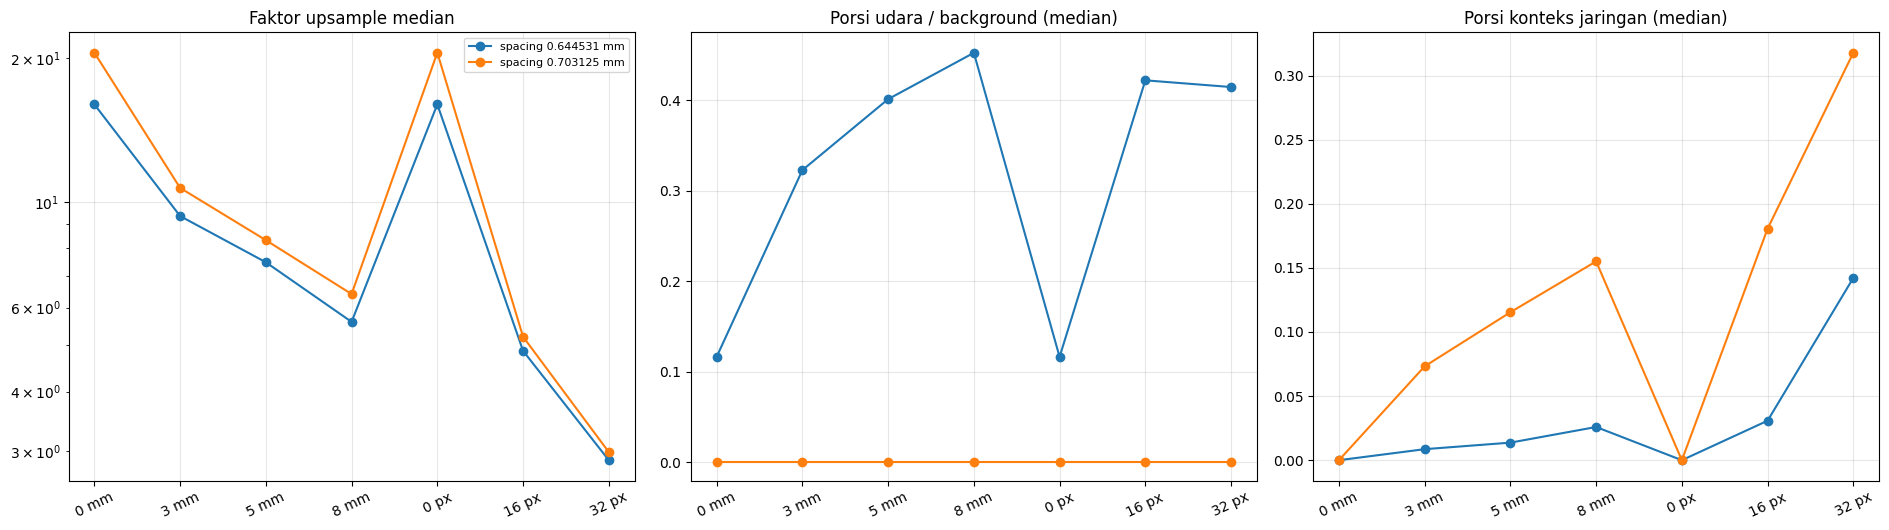


Figure: results/preprocessing_audit/margin_by_pixel_spacing.png


In [18]:

# ============================================================
# CELL 11.2.1 - DISTRIBUSI PER SERI DAN PER PIXEL SPACING
# ============================================================

by_series = summarize_by_series(margin_audit)
print("=" * 140)
print("DISTRIBUSI PER SERI / PIXEL SPACING")
print("=" * 140)
display(by_series.round(3))

print("\nRingkasan per nilai pixel spacing (semua seri digabung):")
spacing_summary = (
    margin_audit.groupby(["pixel_spacing_mm", "Margin_Jenis", "Margin_Nilai"])
    .agg(
        n_cluster=("NoduleClusterID", "size"),
        margin_aktual_mm_median=("margin_actual_mm", "median"),
        margin_aktual_mm_std=("margin_actual_mm", "std"),
        upsample_median=("upsample_factor", "median"),
        crop_px_median=("sisi_terpanjang_px", "median"),
        frac_airy_median=("frac_airy", "median"),
        frac_context_soft_median=("frac_context_soft", "median"),
        img_std_median=("img_std", "median"),
    )
    .reset_index()
    .sort_values(["Margin_Jenis", "Margin_Nilai"])
)
display(spacing_summary.round(3))

n_spacing = margin_audit["pixel_spacing_mm"].nunique()
print(f"\nNilai pixel spacing yang teruji: "
      f"{sorted(float(v) for v in margin_audit['pixel_spacing_mm'].unique())} "
      f"({n_spacing} nilai)")
if n_spacing < 3:
    print("PERINGATAN: kurang dari 3 nilai pixel spacing. Perbandingan")
    print("konsistensi margin mm vs fixed-piksel belum kuat dan TIDAK cukup")
    print("untuk mengunci margin final. Audit penuh di PC Lab wajib dijalankan.")

fig, axes = plt.subplots(1, 3, figsize=(19, 5.4))
spacings = sorted(margin_audit["pixel_spacing_mm"].unique())
all_m = [f"{m:g} mm" for m in MARGIN_MM_CANDIDATES] + \
        [f"{p} px" for p in MARGIN_PX_CANDIDATES]
xpos = np.arange(len(all_m))

for ax, col, title in (
        (axes[0], "upsample_factor", "Faktor upsample median"),
        (axes[1], "frac_airy", "Porsi udara / background (median)"),
        (axes[2], "frac_context_soft", "Porsi konteks jaringan (median)")):
    for sp in spacings:
        g = margin_audit[margin_audit["pixel_spacing_mm"] == sp]
        ys = [g[g["Margin"] == m][col].median() if (g["Margin"] == m).any()
              else np.nan for m in all_m]
        ax.plot(xpos, ys, marker="o", label=f"spacing {sp} mm")
    ax.set_xticks(xpos)
    ax.set_xticklabels(all_m, rotation=25)
    ax.set_title(title)
    ax.grid(alpha=.3)
axes[0].set_yscale("log")
axes[1].set_ylim(bottom=-0.02)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(AUDIT_DIR / "margin_by_pixel_spacing.png", dpi=110)
if DISPLAY_FIGURES_INLINE:
    plt.show()
else:
    plt.close(fig)
print(f"\nFigure: "
      f"{(AUDIT_DIR / 'margin_by_pixel_spacing.png').relative_to(PROJECT_ROOT)}")


DISTRIBUSI UKURAN CROP (sisi terpanjang, piksel)


,Margin,min,p10,p25,median,p75,p90,max,std
0,0 mm,9,10.2,12.0,14.0,17.5,23.2,24,4.86
1,3 mm,19,20.2,22.0,24.0,27.5,33.2,34,4.86
2,5 mm,25,26.2,28.0,30.0,33.5,39.2,40,4.86
3,8 mm,35,36.2,38.0,40.0,43.5,49.2,50,4.86
4,0 px,9,10.2,12.0,14.0,17.5,23.2,24,4.86
5,16 px,41,42.2,44.0,46.0,49.5,55.2,56,4.86
6,32 px,73,74.2,76.0,78.0,81.5,87.2,88,4.86



Distribusi ukuran bbox annotation TANPA margin (konteks tetap):
  jumlah cluster          : 25
  sisi terpanjang (px)    : min=7 median=13.0 max=32
  diameter terpanjang (mm): min=5.6 median=8.4 max=23.9


,SeriesInstanceUID,NoduleClusterID,core_h_px,core_w_px,core_max_mm,n_slices_z
119,1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016...,3,8,8,5.62,1
112,1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016...,2,7,8,5.62,2
105,1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016...,1,8,8,5.62,2
161,1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016...,9,8,8,5.62,2
84,1.3.6.1.4.1.14519.5.2.1.6279.6001.239358021703...,13,9,7,5.80,4
21,1.3.6.1.4.1.14519.5.2.1.6279.6001.239358021703...,4,8,9,5.80,1
168,1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016...,10,9,10,7.03,2
49,1.3.6.1.4.1.14519.5.2.1.6279.6001.239358021703...,8,12,12,7.73,3
14,1.3.6.1.4.1.14519.5.2.1.6279.6001.239358021703...,3,11,12,7.73,2
77,1.3.6.1.4.1.14519.5.2.1.6279.6001.239358021703...,12,9,12,7.73,2


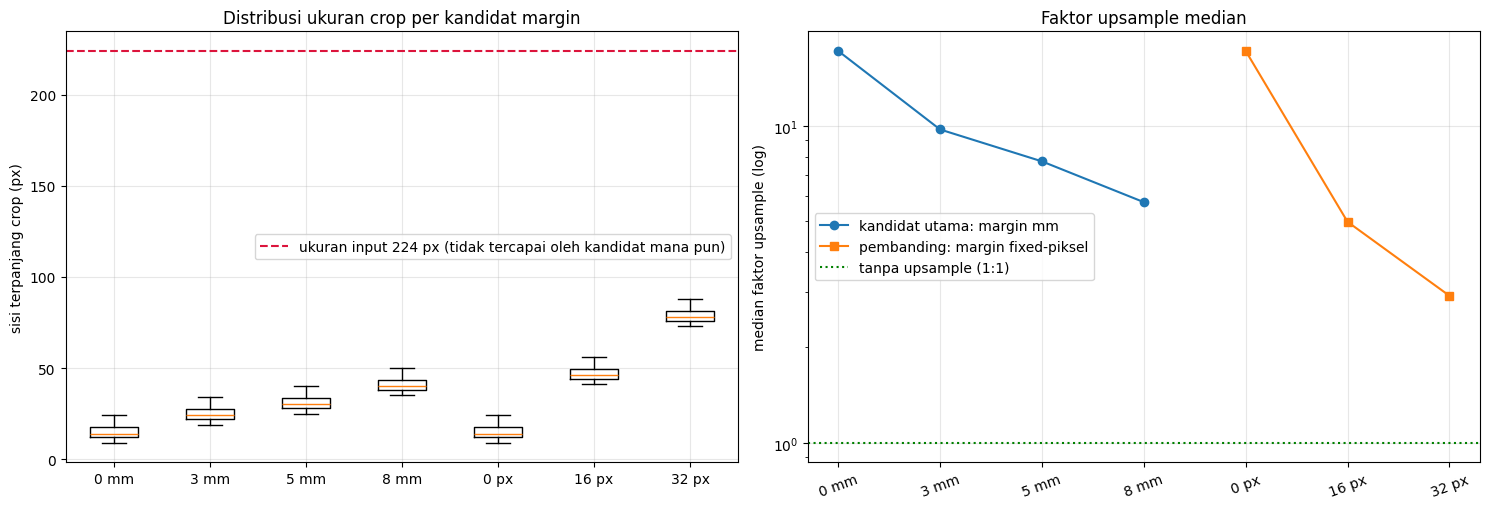


Figure disimpan: results/preprocessing_audit/margin_size_distribution.png


In [19]:
# ============================================================
# CELL 11.2 - DISTRIBUSI UKURAN CROP
# ============================================================

print("=" * 96)
print("DISTRIBUSI UKURAN CROP (sisi terpanjang, piksel)")
print("=" * 96)

pivot = margin_audit.assign(
    sisi=margin_audit[["crop_h_px", "crop_w_px"]].max(axis=1))
pivot = pivot.pivot_table(index="Margin", columns="NoduleClusterID",
                          values="sisi", aggfunc="first")
order = ([f"{m:g} mm" for m in MARGIN_MM_CANDIDATES]
         + [f"{p} px" for p in MARGIN_PX_CANDIDATES])
pivot = pivot.reindex([o for o in order if o in pivot.index])

dist = pd.DataFrame({
    "n": [len(pivot) if not pivot.empty else 0],
})
rows_dist = []
for margin in pivot.index:
    v = pivot.loc[margin].dropna()
    rows_dist.append({
        "Margin": margin,
        "min": v.min(), "p10": v.quantile(.10), "p25": v.quantile(.25),
        "median": v.median(), "p75": v.quantile(.75), "p90": v.quantile(.90),
        "max": v.max(), "std": v.std(),
    })
dist = pd.DataFrame(rows_dist)
display(dist.round(2))

print("\nDistribusi ukuran bbox annotation TANPA margin (konteks tetap):")
core_sizes = (margin_audit[margin_audit.Margin_px == 0]
              [["SeriesInstanceUID", "NoduleClusterID", "core_h_px",
                "core_w_px", "core_max_mm", "n_slices_z"]]
              .drop_duplicates()
              .sort_values("core_max_mm"))
print(f"  jumlah cluster          : {len(core_sizes)}")
print(f"  sisi terpanjang (px)    : min={core_sizes.core_h_px.min()} "
      f"median={core_sizes.core_h_px.median()} max={core_sizes.core_h_px.max()}")
print(f"  diameter terpanjang (mm): min={core_sizes.core_max_mm.min():.1f} "
      f"median={core_sizes.core_max_mm.median():.1f} "
      f"max={core_sizes.core_max_mm.max():.1f}")
display(core_sizes)

# figure distribusi
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
labels = list(pivot.index)
data = [pivot.loc[m].dropna().values for m in labels]
bp = axes[0].boxplot(data, tick_labels=labels, showfliers=True)
axes[0].axhline(TARGET_SIZE[0], color="crimson", linestyle="--",
                label=f"ukuran input {TARGET_SIZE[0]} px (tidak tercapai "
                      f"oleh kandidat mana pun)")
axes[0].set_ylabel("sisi terpanjang crop (px)")
axes[0].set_title("Distribusi ukuran crop per kandidat margin")
axes[0].legend()
axes[0].grid(alpha=.3)

mm_labels = [f"{m:g} mm" for m in MARGIN_MM_CANDIDATES]
px_labels = [f"{p} px" for p in MARGIN_PX_CANDIDATES]
for labelset, marker, color, name in (
        (mm_labels, "o", "tab:blue", "kandidat utama: margin mm"),
        (px_labels, "s", "tab:orange", "pembanding: margin fixed-piksel")):
    xs = [labels.index(l) for l in labelset if l in labels]
    ys = [margin_audit[margin_audit.Margin == l]["upsample_factor"].median()
          for l in labelset if l in labels]
    axes[1].plot(xs, ys, marker=marker, color=color, label=name)
axes[1].axhline(1.0, color="green", linestyle=":", label="tanpa upsample (1:1)")
axes[1].set_yscale("log")
axes[1].set_xticks(range(len(labels)))
axes[1].set_xticklabels(labels, rotation=20)
axes[1].set_ylabel("median faktor upsample (log)")
axes[1].set_title("Faktor upsample median")
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
fig.savefig(AUDIT_DIR / "margin_size_distribution.png", dpi=110)
if DISPLAY_FIGURES_INLINE:
    plt.show()
else:
    plt.close(fig)
print(f"\nFigure disimpan: "
      f"{(AUDIT_DIR / 'margin_size_distribution.png').relative_to(PROJECT_ROOT)}")

KETERSEDIAAN KASUS AUDIT SLICE 2 / 4 / 6
  n | status     | di pool lokal | total annotation | seri
------------------------------------------------------------------------------
  2 | ADA        |             8 |              131 | LIDC-IDRI-0188 cluster 1
  4 | ADA        |             3 |              134 | LIDC-IDRI-0049 cluster 1
  6 | TIDAK ADA  |             0 |               72 | -

Kasus yang tidak bisa divisualkan akan muncul otomatis di PC Lab
ketika DICOM untuk serinya tersedia. Tidak ada data yang dikarang



  -> preprocessing_sample/slice_case_n2.png



  -> preprocessing_sample/slice_case_n4.png

Kasus yang TIDAK bisa divisualkan di laptop: n = [6]
Tidak ada data yang dikarang atau dipaksakan. Audit visual
untuk kasus tersebut akan tersedia otomatis di PC Lab.


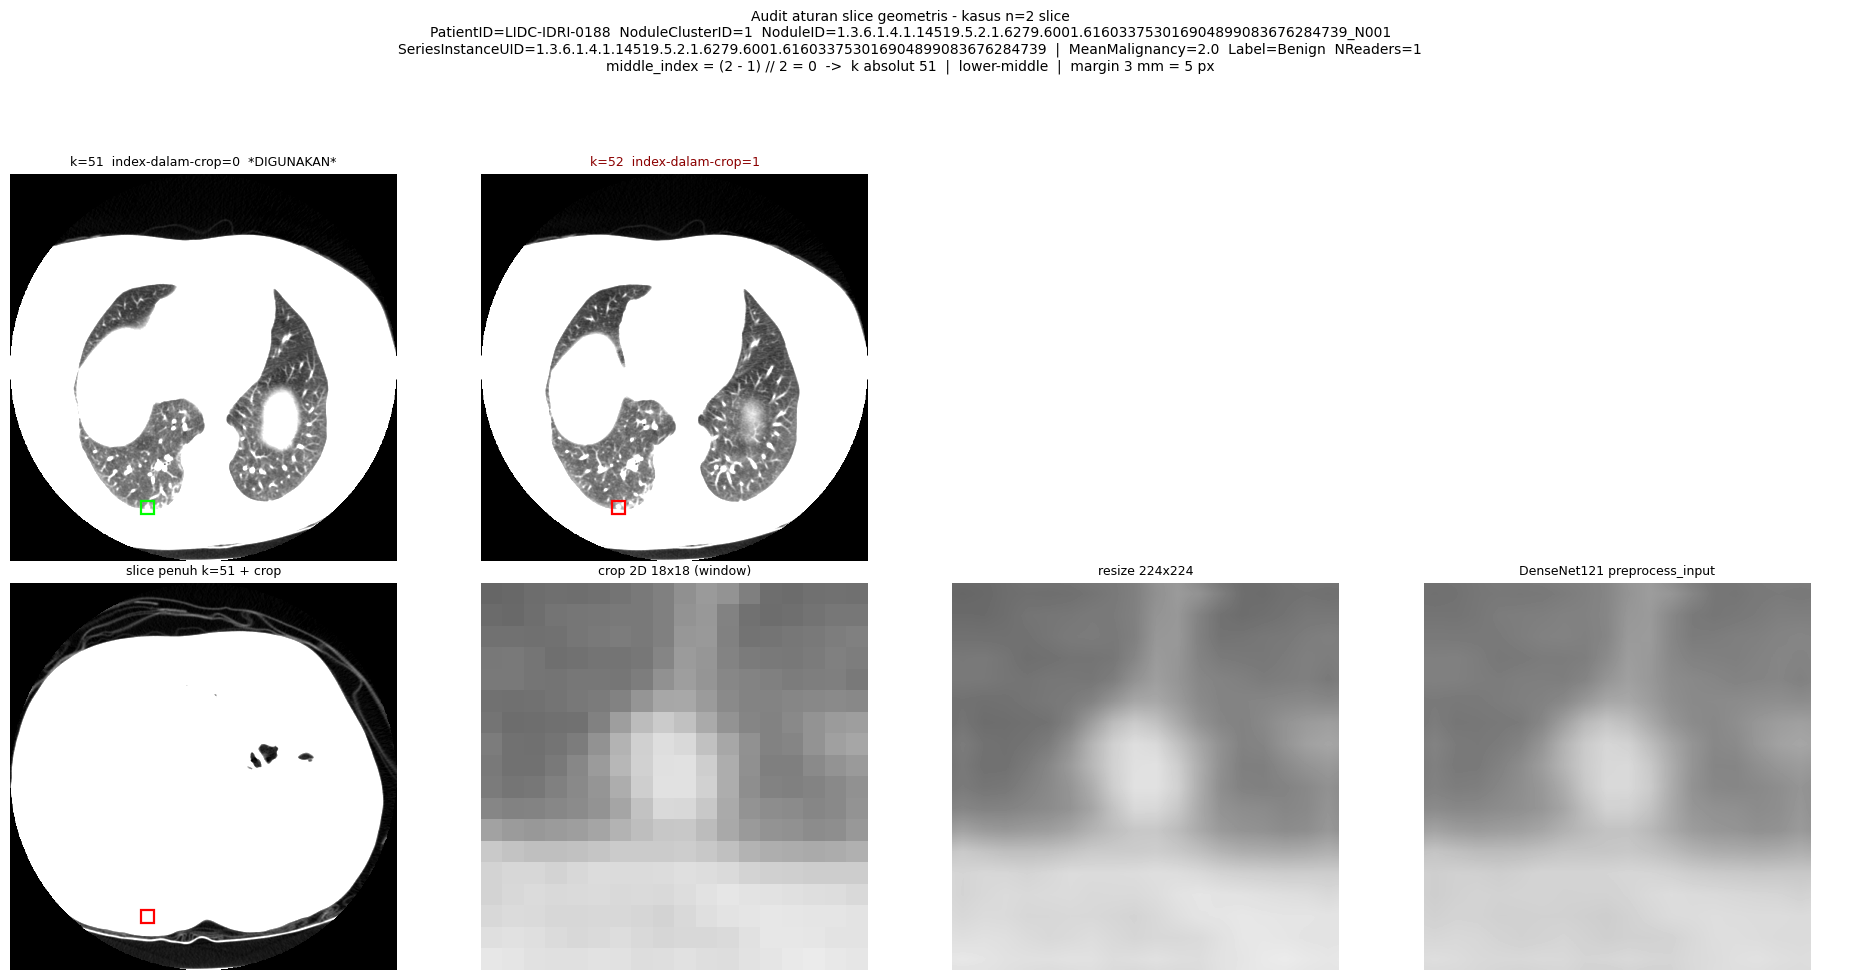

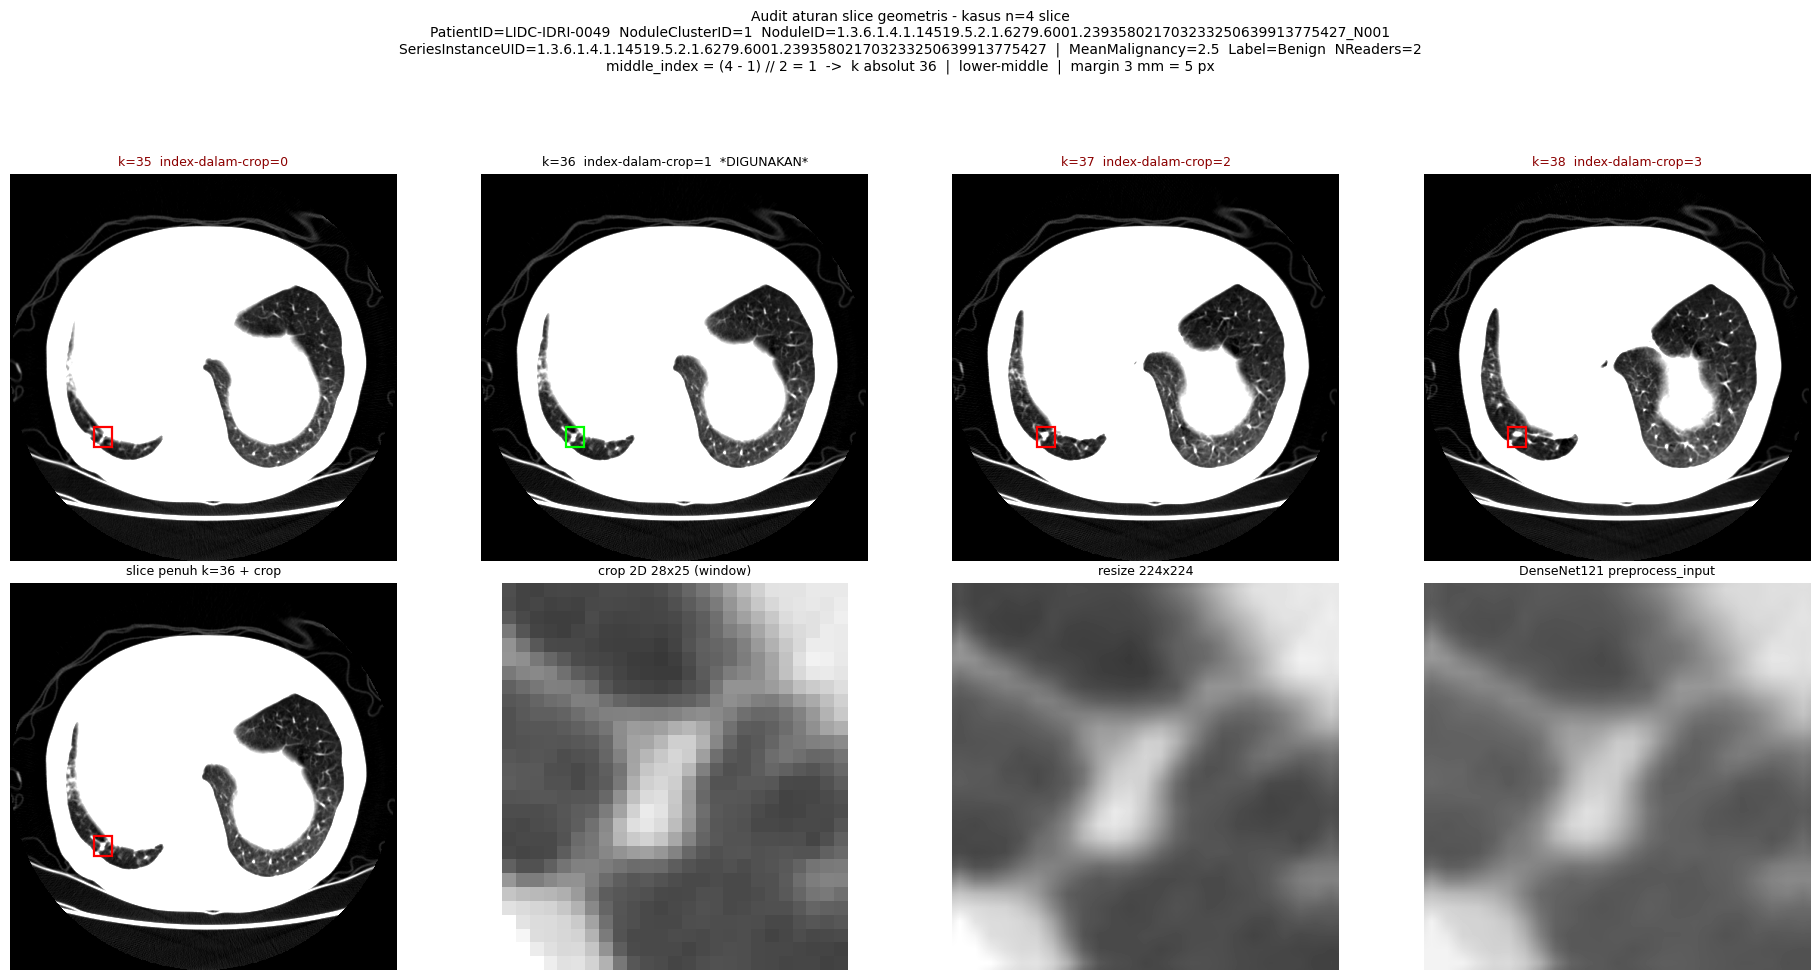

In [20]:
# ============================================================
# CELL 11.3 - AUDIT VISUAL KASUS SLICE 2, 4, 6
# ============================================================

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Cari cluster dengan jumlah slice tepat 2, 4, 6 pada pool yang tersedia.
target_ns = (2, 4, 6)
cases = {}
for n in target_ns:
    sub = audit_ann[audit_ann["BBox_Z_Slices"] == n]
    sub = sub[sub["SeriesInstanceUID"].isin(audit_pool)]
    if not sub.empty:
        cases[n] = sub.sort_values("ClusterIndex").iloc[0]

print("=" * 92)
print("KETERSEDIAAN KASUS AUDIT SLICE 2 / 4 / 6")
print("=" * 92)
print(f"{'n':>3} | {'status':<10} | {'di pool lokal':>13} | {'total annotation':>16} | seri")
print("-" * 78)
for n in target_ns:
    in_pool = int((audit_ann["BBox_Z_Slices"] == n).sum())
    in_ann = int((ann["BBox_Z_Slices"] == n).sum())
    if n in cases:
        c = cases[n]
        print(f"{n:>3} | {'ADA':<10} | {in_pool:>13} | {in_ann:>16} | "
              f"{c['PatientID']} cluster {int(c['ClusterIndex'])}")
    else:
        print(f"{n:>3} | {'TIDAK ADA':<10} | {in_pool:>13} | {in_ann:>16} | -")
if any(n not in cases for n in target_ns):
    print("\nKasus yang tidak bisa divisualkan akan muncul otomatis di PC Lab")
    print("ketika DICOM untuk serinya tersedia. Tidak ada data yang dikarang")


def plot_slice_case(n: int, case) -> str | None:
    uid = str(case["SeriesInstanceUID"])
    series = audit_series_cache.get(uid) or CtSeries(uid, local_series[uid])
    margin_px = margin_px_from_mm(3.0, series.pixel_size_mm)
    out = run_pipeline(case, series, margin_px)
    b = out["box"]

    n_z = b["n_slices_z"]
    k_used = b["k_rel"]
    fig, axes = plt.subplots(2, 4, figsize=(19, 9.8))

    # baris atas: seluruh slice dalam rentang BBox_Z
    ks = list(range(b["z0"], b["z1"] + 1))
    for j, k in enumerate(ks[:4]):
        hu = (hu_volume[k] if (uid == sample_uid and k < hu_volume.shape[0])
              else series.read_hu(k))
        ax = axes[0][j]
        ax.imshow(hu, cmap="gray", vmin=-1000, vmax=-400)
        ax.add_patch(plt.Rectangle(
            (b["c0"], b["r0"]), b["c1"] - b["c0"], b["r1"] - b["r0"],
            fill=False, ec="lime" if k == b["k_abs"] else "red", lw=1.6))
        ax.set_title(f"k={k}  index-dalam-crop={k - b['z0']}"
                     + ("  *DIGUNAKAN*" if k == b["k_abs"] else ""),
                     fontsize=9, color="black" if k == b["k_abs"] else "darkred")
        ax.axis("off")
    for j in range(len(ks), 4):
        axes[0][j].axis("off")

    # baris bawah: crop + window + resize
    ax = axes[1][0]
    ax.imshow(hu_volume[k_used] if uid == sample_uid else
              series.read_hu(b["k_abs"]), cmap="gray", vmin=-1000, vmax=-400)
    ax.add_patch(plt.Rectangle(
        (b["c0"], b["r0"]), b["c1"] - b["c0"], b["r1"] - b["r0"],
        fill=False, ec="red", lw=1.6))
    ax.set_title(f"slice penuh k={b['k_abs']} + crop", fontsize=9)
    ax.axis("off")

    axes[1][1].imshow(out["windowed"], cmap="gray", vmin=0, vmax=1)
    axes[1][1].set_title(f"crop 2D {b['crop_h']}x{b['crop_w']} (window)", fontsize=9)
    axes[1][1].axis("off")

    axes[1][2].imshow(out["resized"], cmap="gray", vmin=0, vmax=1)
    axes[1][2].set_title(f"resize {TARGET_SIZE[0]}x{TARGET_SIZE[1]}", fontsize=9)
    axes[1][2].axis("off")

    axes[1][3].imshow(out["model_input"].mean(axis=0), cmap="gray",
                      vmin=-2.5, vmax=2.7)
    axes[1][3].set_title("DenseNet121 preprocess_input", fontsize=9)
    axes[1][3].axis("off")

    fig.suptitle(
        f"Audit aturan slice geometris - kasus n={n} slice\n"
        f"PatientID={case['PatientID']}  NoduleClusterID="
        f"{int(case['ClusterIndex'])}  NoduleID={case['NoduleID']}\n"
        f"SeriesInstanceUID={uid}  |  MeanMalignancy={case['MeanMalignancy']}  "
        f"Label={case['Label']}  NReaders={int(case['NReaders'])}\n"
        f"middle_index = ({n_z} - 1) // 2 = {k_used}  ->  k absolut {b['k_abs']}  "
        f"|  {'tengah' if n_z % 2 else 'lower-middle'}  "
        f"|  margin {3.0:g} mm = {margin_px} px", fontsize=10, y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.93))

    path = FIGURE_DIR / f"slice_case_n{n}.png"
    fig.savefig(path, dpi=105, bbox_inches="tight")
    if not DISPLAY_FIGURES_INLINE:
        plt.close(fig)
    return str(path)


slice_case_paths = []
for n in target_ns:
    if n in cases:
        p = plot_slice_case(n, cases[n])
        slice_case_paths.append(p)
        print(f"\n  -> {FIGURE_DIR.name}/{Path(p).name}")

print("\n" + "=" * 92)
if len(slice_case_paths) < len(target_ns):
    missing = [n for n in target_ns if n not in cases]
    print(f"Kasus yang TIDAK bisa divisualkan di laptop: n = {missing}")
    print("Tidak ada data yang dikarang atau dipaksakan. Audit visual")
    print("untuk kasus tersebut akan tersedia otomatis di PC Lab.")

## 12. Figure representative: perbandingan margin mm

Menampilkan beberapa ukuran nodule (kecil / sedang / besar) berdasarkan
ukuran bbox **annotation**, bukan berdasarkan label. Label hanya dicetak
pada judul sebagai informasi.

Figure ini adalah bahan review untuk memilih margin. **Belum ada nilai
final yang dipilih di notebook ini.**

Cluster representative (dipilih berdasarkan ukuran bbox, bukan label):
     PatientID                                                              NoduleID  ClusterIndex  Label  MeanMalignancy  core_max_mm  BBox_Z_Slices
LIDC-IDRI-0049 1.3.6.1.4.1.14519.5.2.1.6279.6001.239358021703233250639913775427_N013            13 Benign             1.5        6.327              4
LIDC-IDRI-0188 1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016904899083676284739_N007             7 Benign             2.5        9.139              3
LIDC-IDRI-0049 1.3.6.1.4.1.14519.5.2.1.6279.6001.239358021703233250639913775427_N001             1 Benign             2.5       12.654              4



Figure perbandingan margin (mm):
  - margin_mm_cluster_13.png
  - margin_mm_cluster_07.png
  - margin_mm_cluster_01.png


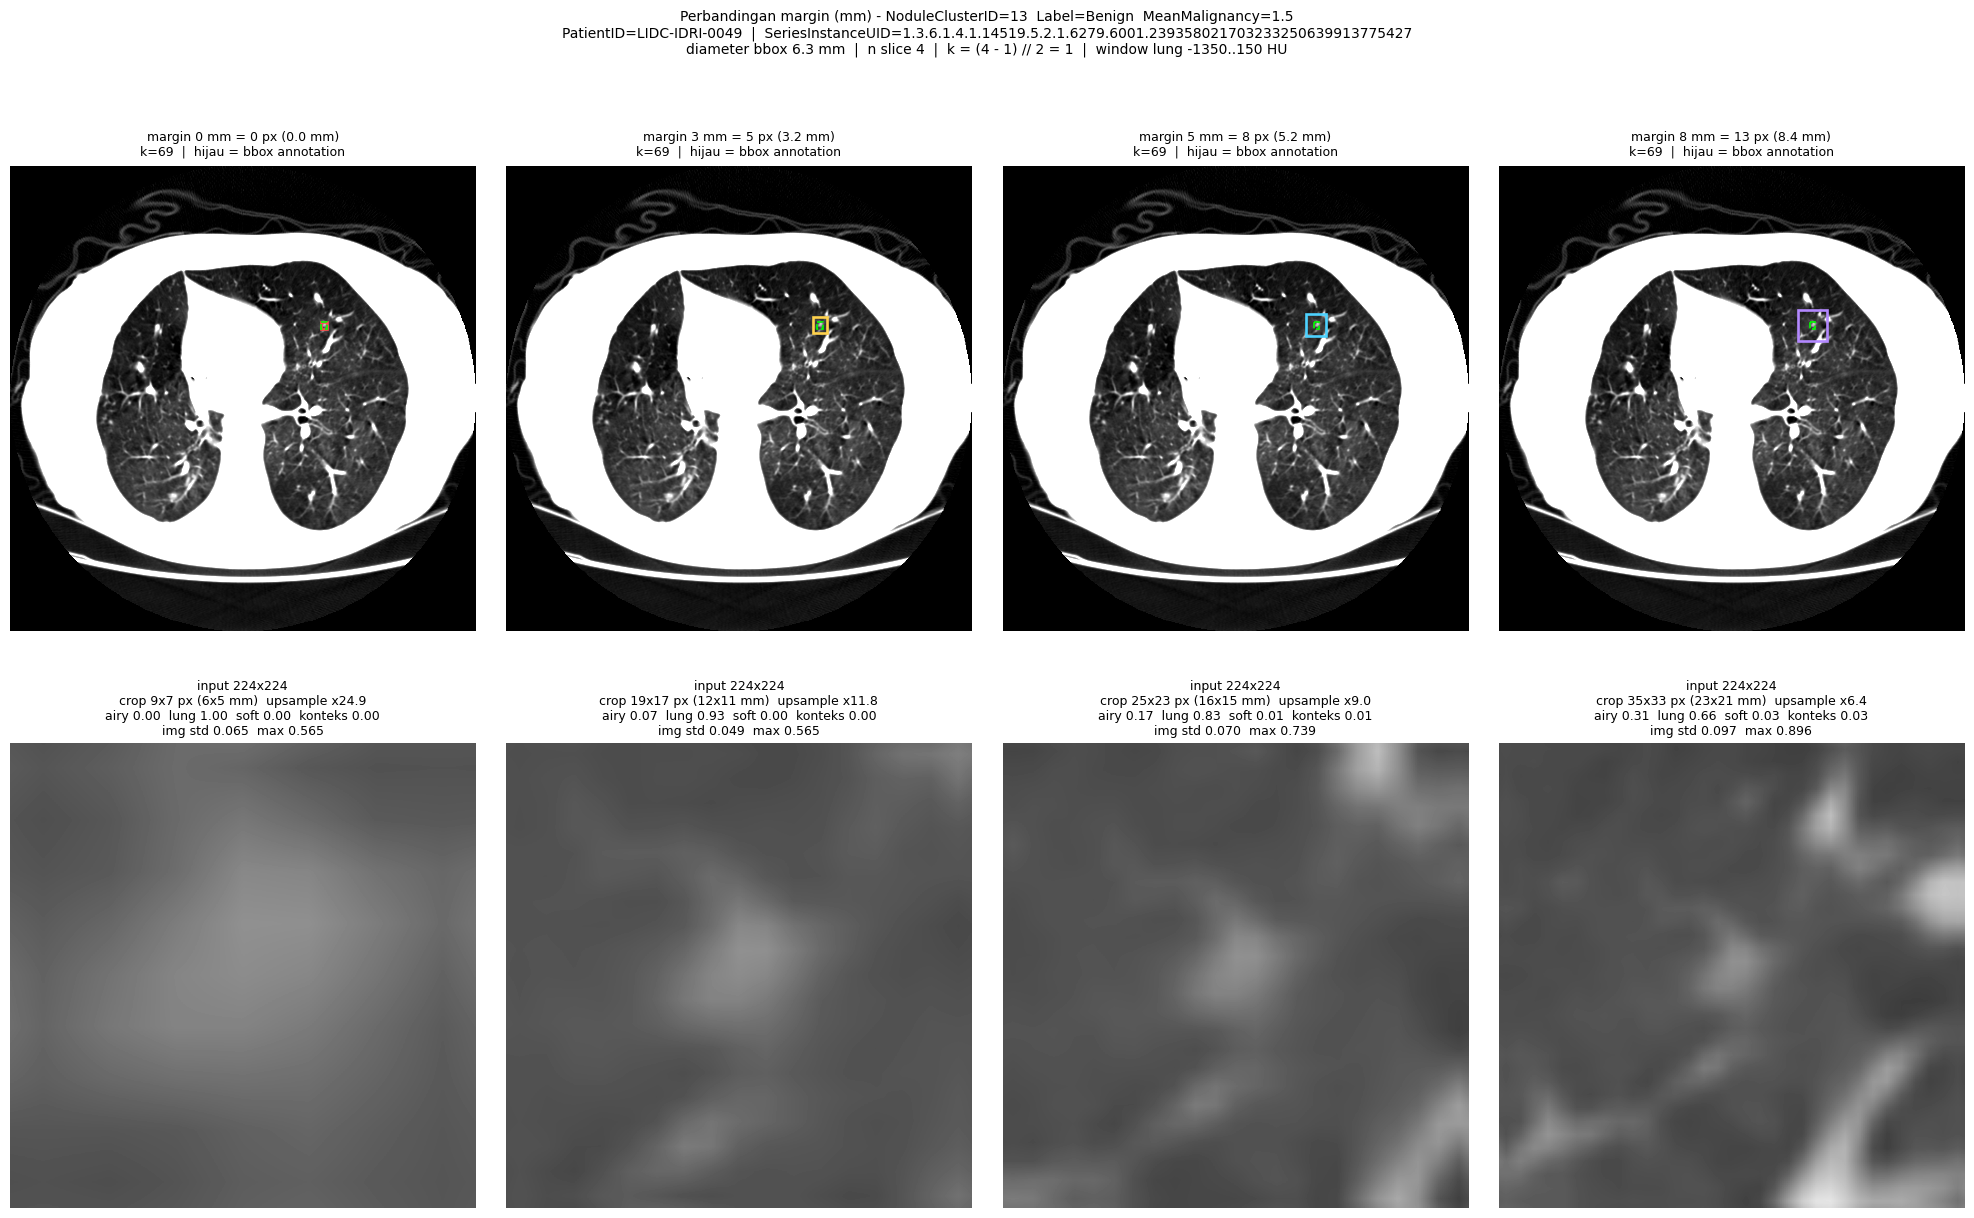

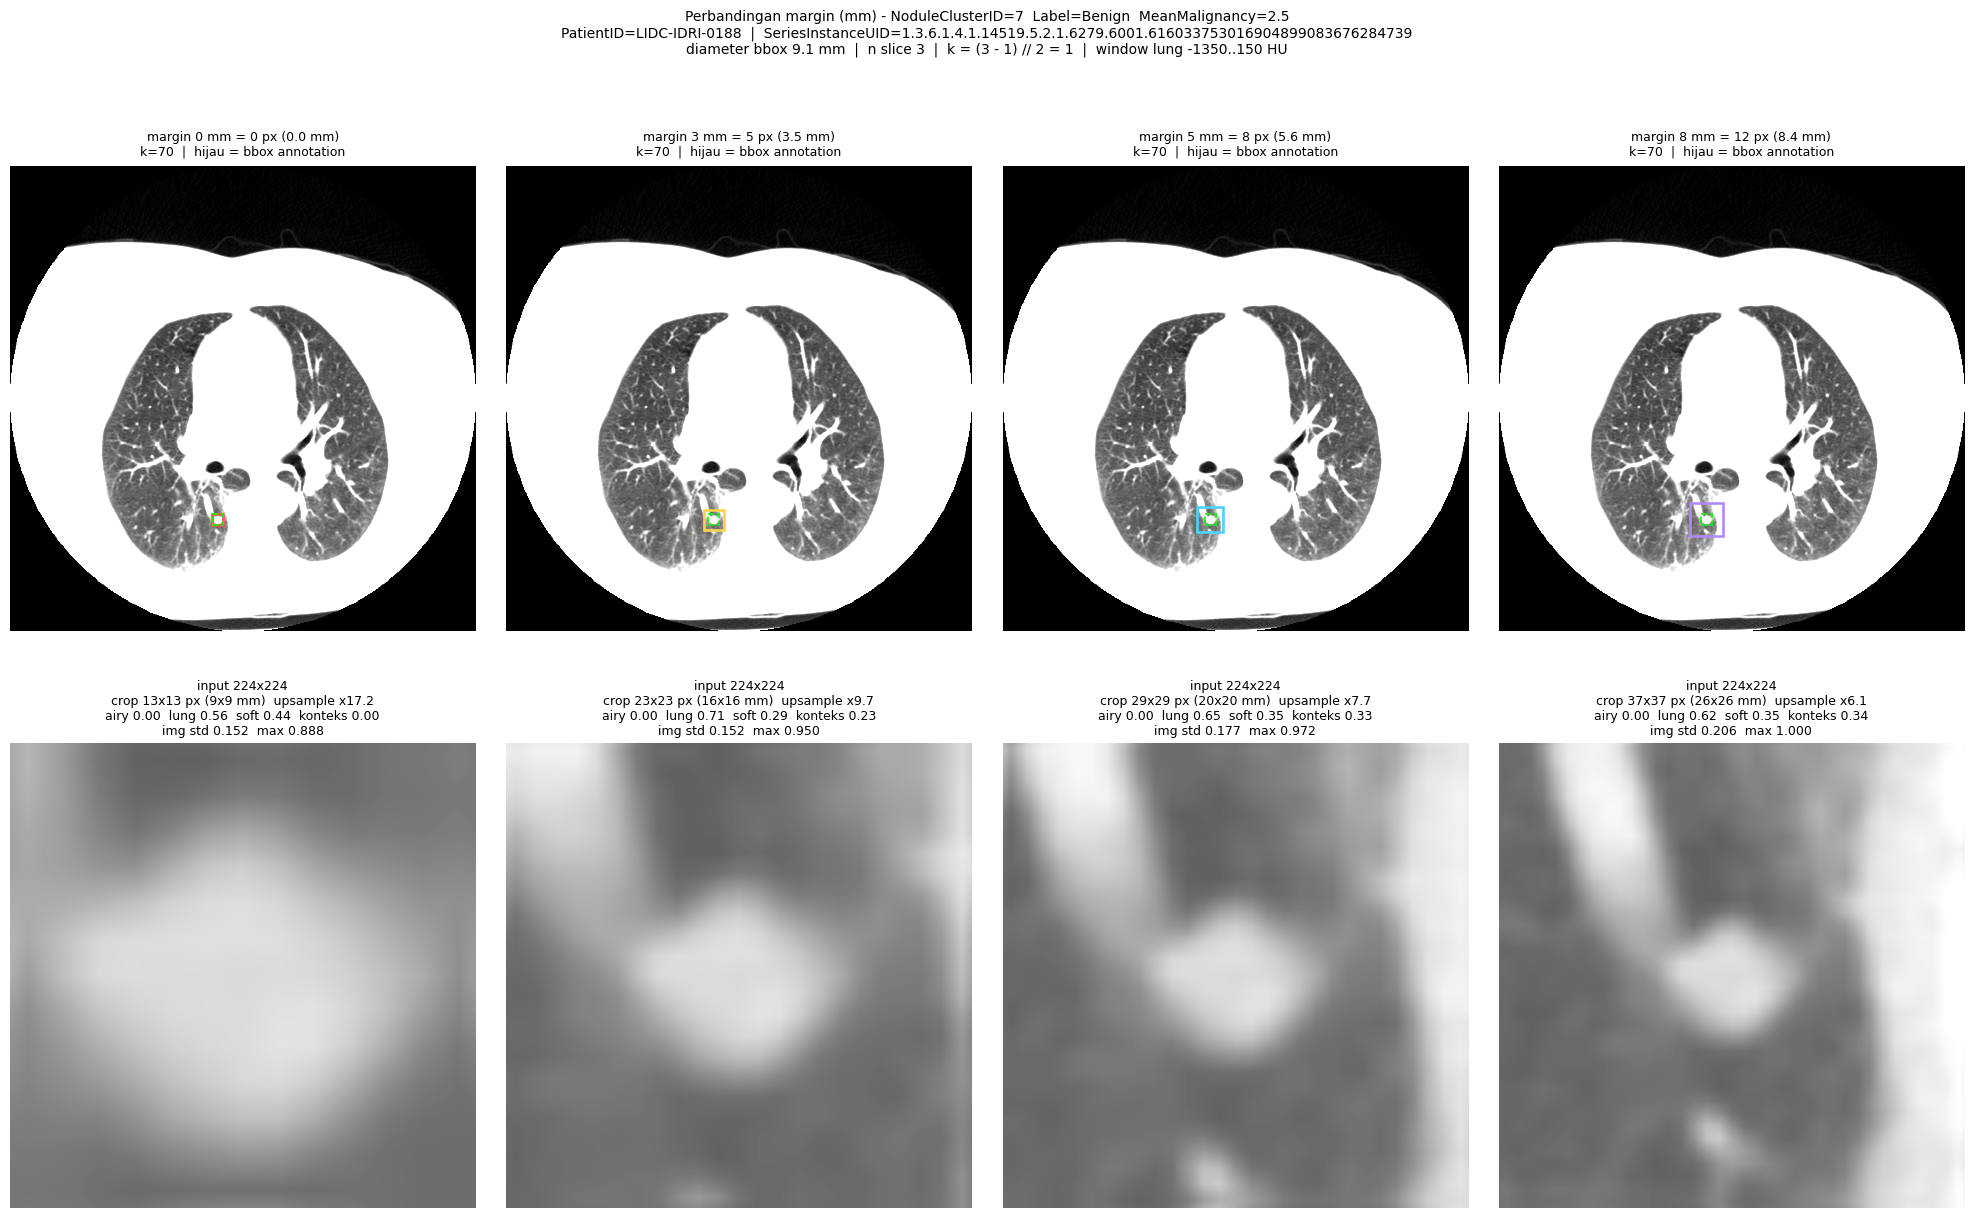

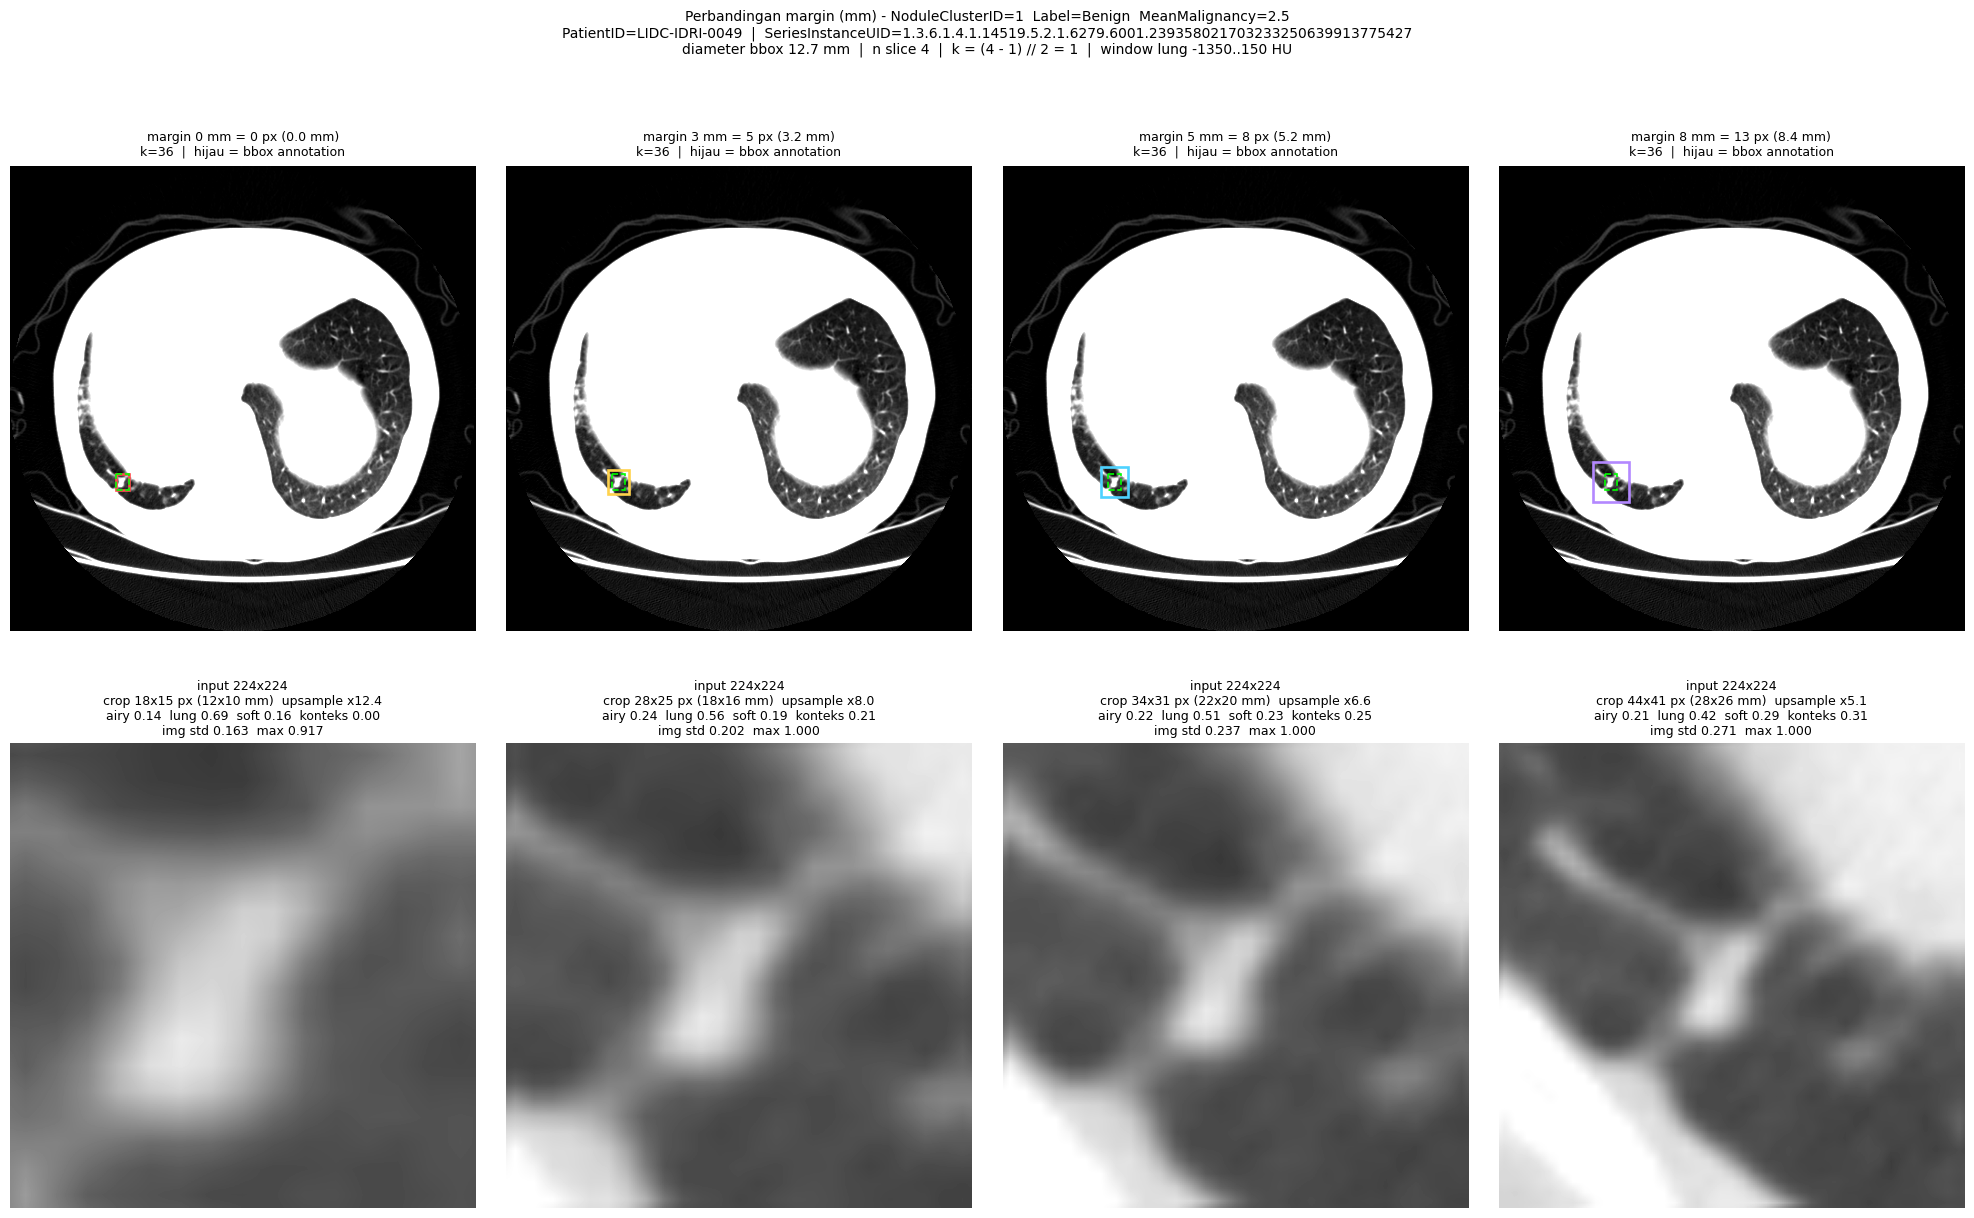

In [21]:
# ============================================================
# CELL 12 - FIGURE PERBANDINGAN MARGIN (mm)
# ============================================================

# Pilih cluster representatif berdasarkan ukuran bbox, tanpa memakai label.
base = (audit_ann[audit_ann["SeriesInstanceUID"].isin(audit_pool)]
        .drop_duplicates(subset=["SeriesInstanceUID", "ClusterIndex"])
        .copy())
base["core_max_mm"] = [
    max((int(r.BBox_X_Max) - int(r.BBox_X_Min) + 1) * 0.703,
        (int(r.BBox_Y_Max) - int(r.BBox_Y_Min) + 1) * 0.703)
    for _, r in base.iterrows()]

N_REVIEW = 3
quantiles = [0.15, 0.50, 0.85]
review = []
for q in quantiles:
    thr = base["core_max_mm"].quantile(q)
    near = base.iloc[(base["core_max_mm"] - thr).abs().argsort()[:1]]
    if not near.empty and near.iloc[0]["NoduleID"] not in review:
        review.append(near.iloc[0]["NoduleID"])

review_rows = ann[ann["NoduleID"].isin(review)]
review_rows = review_rows.merge(
    base[["NoduleID", "core_max_mm"]], on="NoduleID", how="left"
).sort_values("core_max_mm")

print("Cluster representative (dipilih berdasarkan ukuran bbox, bukan label):")
print(review_rows[["PatientID", "NoduleID", "ClusterIndex", "Label",
                   "MeanMalignancy", "core_max_mm", "BBox_Z_Slices"]]
      .to_string(index=False))


def plot_margin_mm(case) -> str:
    uid = str(case["SeriesInstanceUID"])
    series = audit_series_cache.get(uid) or CtSeries(uid, local_series[uid])
    px_mm = series.pixel_size_mm
    colors = {0.0: "#ff4d4d", 3.0: "#ffd24d", 5.0: "#4dd2ff", 8.0: "#b388ff"}

    fig, axes = plt.subplots(2, len(MARGIN_MM_CANDIDATES),
                             figsize=(5.0 * len(MARGIN_MM_CANDIDATES), 12.2))
    axes = np.atleast_2d(axes)

    for j, mm in enumerate(MARGIN_MM_CANDIDATES):
        mpx = margin_px_from_mm(mm, px_mm)
        out = run_pipeline(case, series, mpx)
        b, sl = out["box"], out["hu_slice"]

        hu_full = (hu_volume[b["k_abs"]] if uid == sample_uid
                   else series.read_hu(b["k_abs"]))
        axes[0][j].imshow(hu_full, cmap="gray", vmin=-1000, vmax=-400)
        axes[0][j].add_patch(Rectangle(
            (b["c0"], b["r0"]), b["c1"] - b["c0"], b["r1"] - b["r0"],
            fill=False, ec=colors.get(mm, "white"), lw=1.9))
        axes[0][j].add_patch(Rectangle(
            (b["core_c0"], b["core_r0"]),
            b["core_c1"] - b["core_c0"], b["core_r1"] - b["core_r0"],
            fill=False, ec="lime", lw=1.2, linestyle="--"))
        axes[0][j].set_title(
            f"margin {mm:g} mm = {mpx} px ({mpx * px_mm:.1f} mm)\n"
            f"k={b['k_abs']}  |  hijau = bbox annotation", fontsize=9, pad=8)
        axes[0][j].axis("off")

        f_airy = float((sl <= -900).mean())
        f_lung = float(((sl > -900) & (sl <= -400)).mean())
        f_soft = float(((sl > -400) & (sl <= 150)).mean())
        f_ctx = float((((sl > -400) & (sl <= 150)).sum()
                       - (out["core_hu"] > -400).sum())
                      / max(1, sl.size - out["core_hu"].size))
        axes[1][j].imshow(out["resized"], cmap="gray", vmin=0, vmax=1)
        axes[1][j].set_title(
            f"input {TARGET_SIZE[0]}x{TARGET_SIZE[1]}\n"
            f"crop {b['crop_h']}x{b['crop_w']} px "
            f"({b['crop_h_mm']:.0f}x{b['crop_w_mm']:.0f} mm)  "
            f"upsample x{out['upsample_factor']:.1f}\n"
            f"airy {f_airy:.2f}  lung {f_lung:.2f}  "
            f"soft {f_soft:.2f}  konteks {f_ctx:.2f}\n"
            f"img std {out['resized'].std():.3f}  "
            f"max {out['resized'].max():.3f}", fontsize=9)
        axes[1][j].axis("off")

    fig.suptitle(
        f"Perbandingan margin (mm) - NoduleClusterID="
        f"{int(case['ClusterIndex'])}  Label={case['Label']}  "
        f"MeanMalignancy={case['MeanMalignancy']}\n"
        f"PatientID={case['PatientID']}  |  SeriesInstanceUID={uid}\n"
        f"diameter bbox {float(case['core_max_mm']):.1f} mm  |  "
        f"n slice {int(case['BBox_Z_Slices'])}  |  "
        f"k = ({int(case['BBox_Z_Slices'])} - 1) // 2 = {middle_index(int(case['BBox_Z_Slices']))}"
        f"  |  window lung {WINDOW_HU_MIN:.0f}..{WINDOW_HU_MAX:.0f} HU",
        fontsize=10, y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    fig.subplots_adjust(hspace=0.24)

    path = FIGURE_DIR / f"margin_mm_cluster_{int(case['ClusterIndex']):02d}.png"
    fig.savefig(path, dpi=105, bbox_inches="tight")
    if not DISPLAY_FIGURES_INLINE:
        plt.close(fig)
    return str(path)


margin_fig_paths = [plot_margin_mm(case) for _, case in review_rows.iterrows()]
print("\nFigure perbandingan margin (mm):")
for p in margin_fig_paths:
    print(f"  - {Path(p).name}")

## 13. Jalankan pipeline pada seri utama

Menggunakan margin `CONTEXT_MARGIN_PX` sementara. **Belum ada nilai final** —
nilai di sini hanya agar pipeline bisa dijalankan dan divisualisasi.

In [22]:
# ============================================================
# CELL 13 - JALANKAN PIPELINE SERI UTAMA
# ============================================================

# PLACEHOLDER - BUKAN KEPUTUSAN METODOLOGI.
# Margin konteks BELUM dikunci. Nilai 0 hanya agar pipeline sample
# dapat dijalankan dan divisualisasi. Audit kandidat margin ada di
# Cell 11 (fungsi evaluate_margin_candidates).
CONTEXT_MARGIN_PX = 0

raw_slices = [main_series.read_hu(k) for k in range(main_series.n_slices)]

results_by_id = {}
summary_rows = []

for _, row in sample_ann.iterrows():
    out = run_pipeline(row, main_series, CONTEXT_MARGIN_PX, volume_hu=hu_volume)
    results_by_id[row.NoduleID] = out
    b = out["box"]
    vals = fov_values(out["hu_slice"])

    summary_rows.append({
        "PatientID": row.PatientID,
        "SeriesInstanceUID": row.SeriesInstanceUID,
        "NoduleClusterID": int(row.ClusterIndex),
        "NoduleID": row.NoduleID,
        "NReaders": int(row.NReaders),
        "MeanMalignancy": row.MeanMalignancy,
        "Label": row.Label,
        "JumlahSliceVolume": main_series.n_slices,
        "JumlahSliceCrop": b["n_slices_z"],
        "UkuranImage": f"{n_rows}x{n_cols}",
        "Margin_px": CONTEXT_MARGIN_PX,
        "HU_Min": float(vals.min()), "HU_Max": float(vals.max()),
        "BBox_Baris": f"{b['core_r0']}-{b['core_r1']}",
        "BBox_Kolom": f"{b['core_c0']}-{b['core_c1']}",
        "BBox_Slice": f"{b['z0']}-{b['z1']}",
        "BBox_Annot_Z": f"{int(row.BBox_Z_Min)}-{int(row.BBox_Z_Max)}",
        "AturanSlice": SLICE_SELECTION,
        "k_Terpakai": b["k_abs"],
        "UkuranCrop": f"{b['crop_h']}x{b['crop_w']}",
        "Crop_mm": f"{b['crop_h_mm']:.0f}x{b['crop_w_mm']:.0f}",
        "Upsample": round(out["upsample_factor"], 1),
        "Tahap23_min": float(out["resized"].min()),
        "Tahap23_max": float(out["resized"].max()),
        "Tahap4_shape": str(out["input_3ch"].shape),
        "Tahap5_min": float(out["model_input"].min()),
        "Tahap5_max": float(out["model_input"].max()),
    })

summary = pd.DataFrame(summary_rows)
print("=" * 120)
print("RINGKASAN HASIL PREPROCESSING (seri utama)")
print("=" * 120)
display(summary.drop(columns=["SeriesInstanceUID", "NoduleID"]))

print("\nCek konsistensi:")
print(f"  Jumlah citra {TARGET_SIZE[0]}x{TARGET_SIZE[1]}"
      .ljust(40) + f": {len(summary)}")
print(f"  Tahap 2+3 (window) dalam [0,1]"
      .ljust(40)
      + f": {bool((summary['Tahap23_min'] >= 0).all() and (summary['Tahap23_max'] <= 1).all())}")
print(f"  Tahap 4 shape (3, 224, 224)"
      .ljust(40)
      + f": {bool((summary['Tahap4_shape'] == f'(3, {TARGET_SIZE[0]}, {TARGET_SIZE[1]})').all())}")
print(f"  Tahap 5 (mean/std ImageNet) dalam [-2.5, 2.7]"
      .ljust(40)
      + f": {bool((summary['Tahap5_min'] >= -2.5).all() and (summary['Tahap5_max'] <= 2.7).all())}")
print(f"  Kanal 1/2/3 identik (replikasi)"
      .ljust(40)
      + f": {all(o['kanal_identik'] for o in results_by_id.values())}")
print(f"  BBox_Z identik dengan annotation"
      .ljust(40)
      + f": {bool((summary['BBox_Slice'] == summary['BBox_Annot_Z']).all())}")
expected_k = [build_crop_box(r, main_series, 0)["k_abs"]
              for _, r in sample_ann.iterrows()]
k_ok = bool((summary["k_Terpakai"].to_numpy() == np.array(expected_k)).all())
print(f"  k = (n-1)//2 sesuai".ljust(40) + f": {k_ok}")

flat = summary[summary["Tahap23_max"] <= 1e-6]
if len(flat):
    raise ValueError(f"{len(flat)} cluster menghasilkan citra kosong: "
                     f"{flat['NoduleClusterID'].tolist()}")
print(f"  Tidak ada citra input kosong"
      .ljust(40) + ": True")

RINGKASAN HASIL PREPROCESSING (seri utama)


,PatientID,NoduleClusterID,NReaders,MeanMalignancy,Label,JumlahSliceVolume,JumlahSliceCrop,UkuranImage,Margin_px,HU_Min,HU_Max,BBox_Baris,BBox_Kolom,BBox_Slice,BBox_Annot_Z,AturanSlice,k_Terpakai,UkuranCrop,Crop_mm,Upsample,Tahap23_min,Tahap23_max,Tahap4_shape,Tahap5_min,Tahap5_max
0,LIDC-IDRI-0188,1,1,2.00,Benign,113,2,512x512,0,-629.0,-26.0,437-444,178-185,51-52,51-52,geometric_lower_middle,51,8x8,6x6,28.0,0.481657,0.882561,"(3, 224, 224)",-0.014597,2.118050
1,LIDC-IDRI-0188,2,1,2.00,Benign,113,2,512x512,0,-638.0,-267.0,433-439,184-191,52-53,52-53,geometric_lower_middle,52,7x8,5x6,28.0,0.475383,0.721521,"(3, 224, 224)",-0.041997,1.402315
2,LIDC-IDRI-0188,3,1,2.00,Benign,113,1,512x512,0,-715.0,-46.0,407-414,311-318,57-57,57-57,geometric_lower_middle,57,8x8,6x6,28.0,0.424560,0.869079,"(3, 224, 224)",-0.263931,2.058128
3,LIDC-IDRI-0188,4,4,3.75,Malignant,113,11,512x512,0,-800.0,106.0,417-448,172-205,54-64,54-64,geometric_lower_middle,59,32x34,22x24,6.6,0.367583,0.970256,"(3, 224, 224)",-0.512737,2.507804
4,LIDC-IDRI-0188,5,4,2.50,Benign,113,3,512x512,0,-899.0,6.0,197-208,155-165,59-61,59-61,geometric_lower_middle,60,12x11,8x8,18.7,0.301133,0.902488,"(3, 224, 224)",-0.802912,2.206613
5,LIDC-IDRI-0188,6,4,3.00,Exclude,113,3,512x512,0,-789.0,48.0,347-362,351-365,66-68,66-68,geometric_lower_middle,67,16x15,11x11,14.0,0.374439,0.931283,"(3, 224, 224)",-0.482800,2.334592
6,LIDC-IDRI-0188,7,4,2.50,Benign,113,3,512x512,0,-780.0,-17.0,383-395,222-234,69-71,69-71,geometric_lower_middle,70,13x13,9x9,17.2,0.380454,0.888450,"(3, 224, 224)",-0.456531,2.144220
7,LIDC-IDRI-0188,8,2,3.50,Malignant,113,3,512x512,0,-792.0,-10.0,344-358,362-374,74-76,74-76,geometric_lower_middle,75,15x13,11x9,14.9,0.372206,0.892731,"(3, 224, 224)",-0.492552,2.163250
8,LIDC-IDRI-0188,9,2,2.50,Benign,113,2,512x512,0,-805.0,-63.0,315-322,143-150,90-91,90-91,geometric_lower_middle,90,8x8,6x6,28.0,0.364032,0.857810,"(3, 224, 224)",-0.528245,2.008044
9,LIDC-IDRI-0188,10,1,2.00,Benign,113,2,512x512,0,-752.0,-266.0,388-396,311-320,91-92,91-92,geometric_lower_middle,91,9x10,6x7,22.4,0.398854,0.721383,"(3, 224, 224)",-0.376185,1.401704



Cek konsistensi:
  Jumlah citra 224x224                  : 10
  Tahap 2+3 (window) dalam [0,1]        : True
  Tahap 4 shape (3, 224, 224)           : True
  Tahap 5 (mean/std ImageNet) dalam [-2.5, 2.7]: True
  Kanal 1/2/3 identik (replikasi)       : True
  BBox_Z identik dengan annotation      : True
  k = (n-1)//2 sesuai                   : True
  Tidak ada citra input kosong          : True


### 13.1 Visualisasi per nodule cluster

Enam panel: pixel_array asli, HU slice penuh, HU + bounding box, crop 2D
windowed, input 224×224 (tahap 2+3), dan input model setelah tahap 4+5.

10 figure cluster disimpan ke results/preprocessing_sample


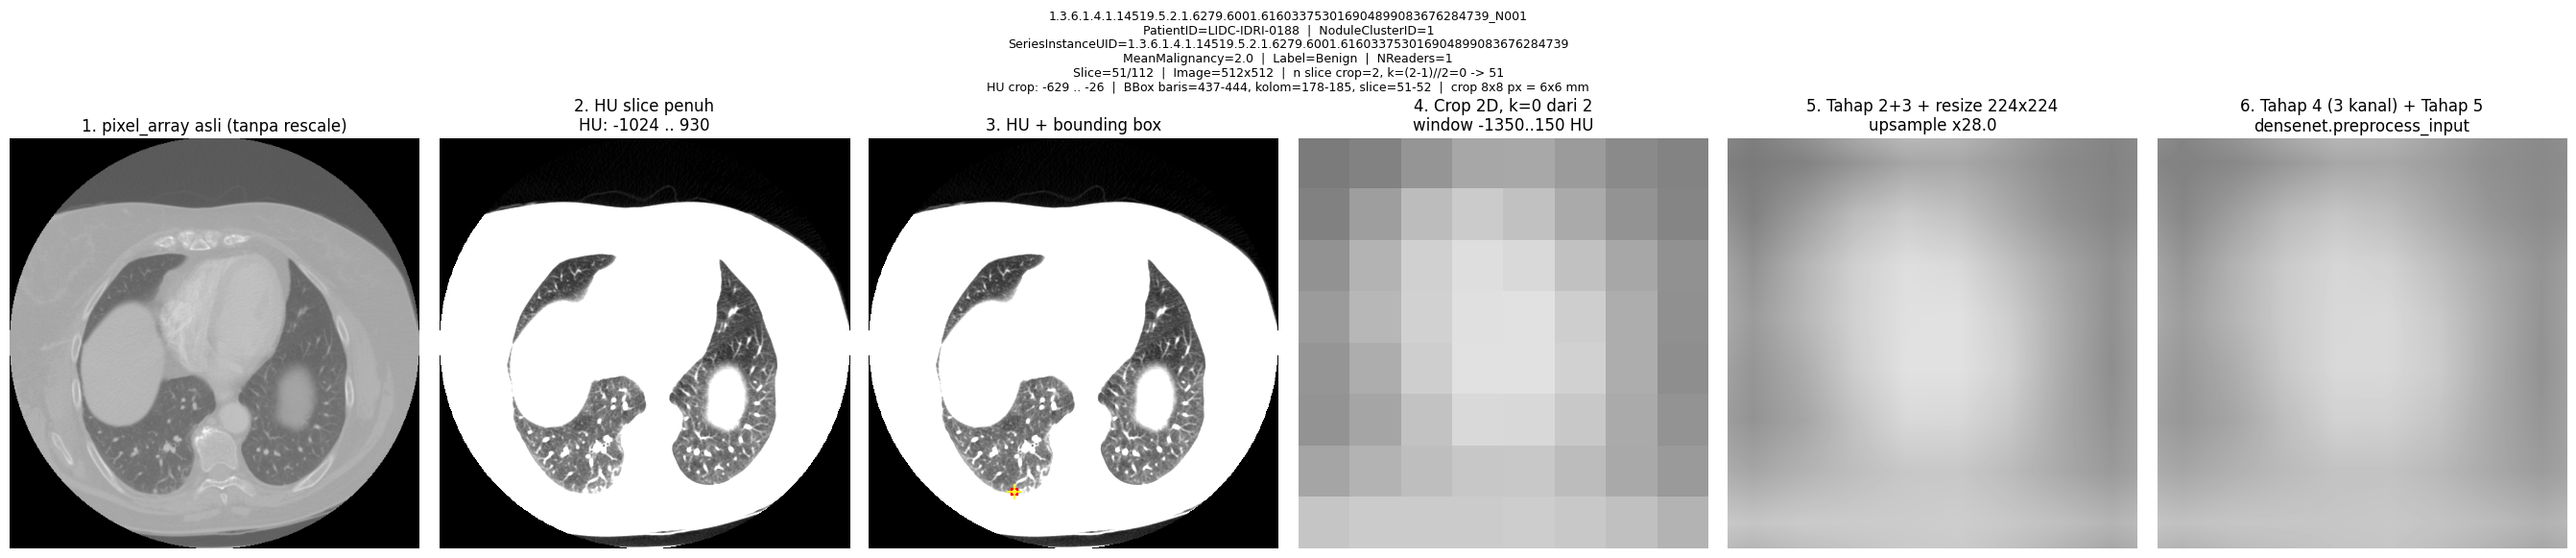

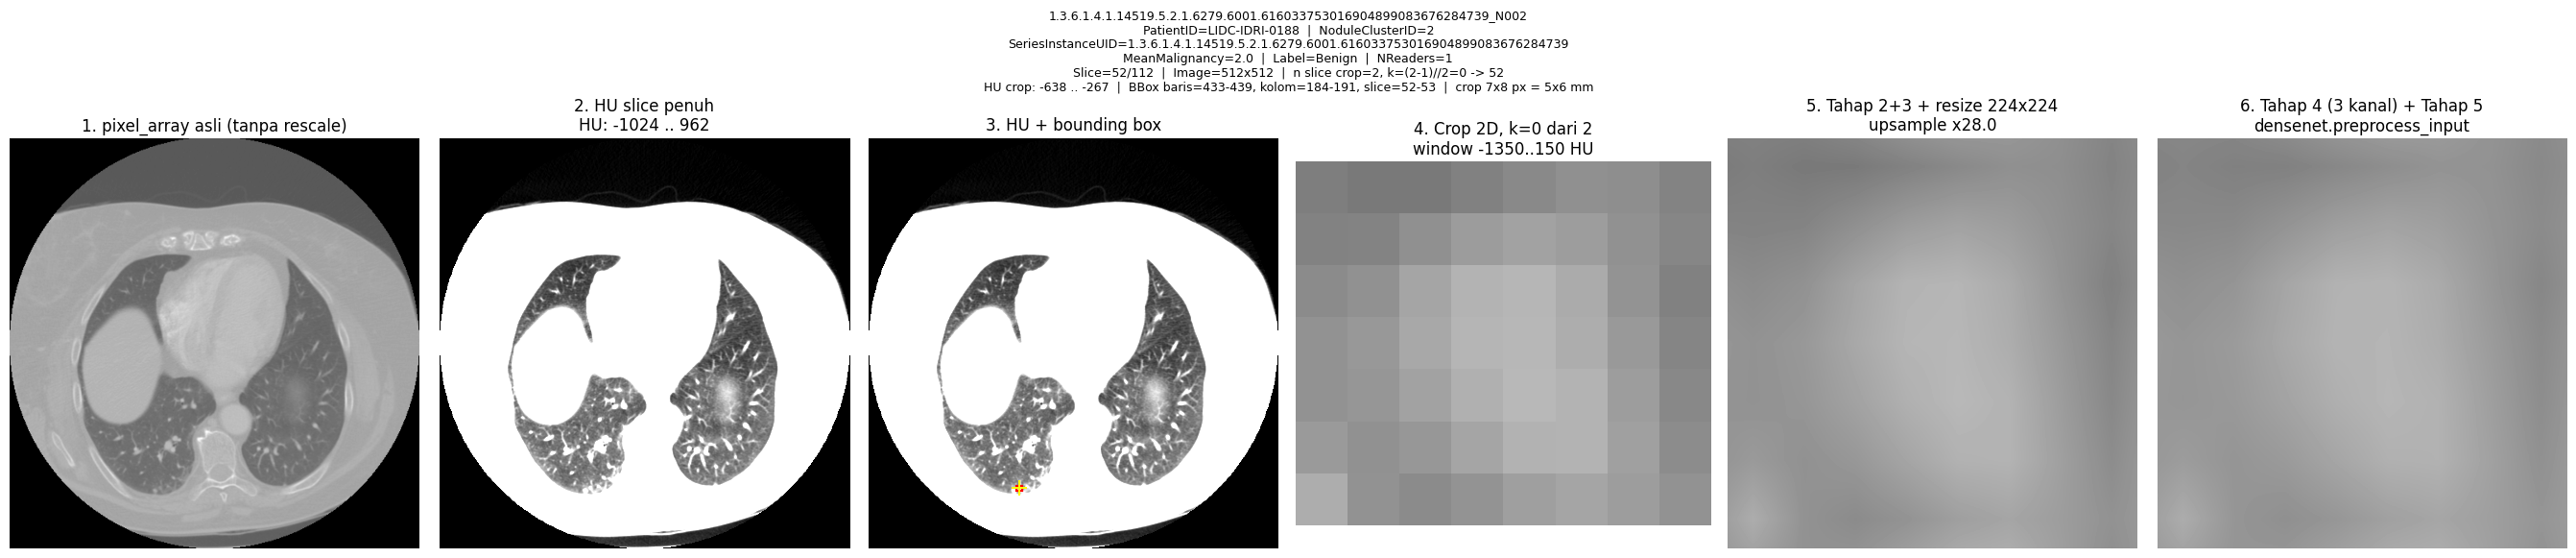

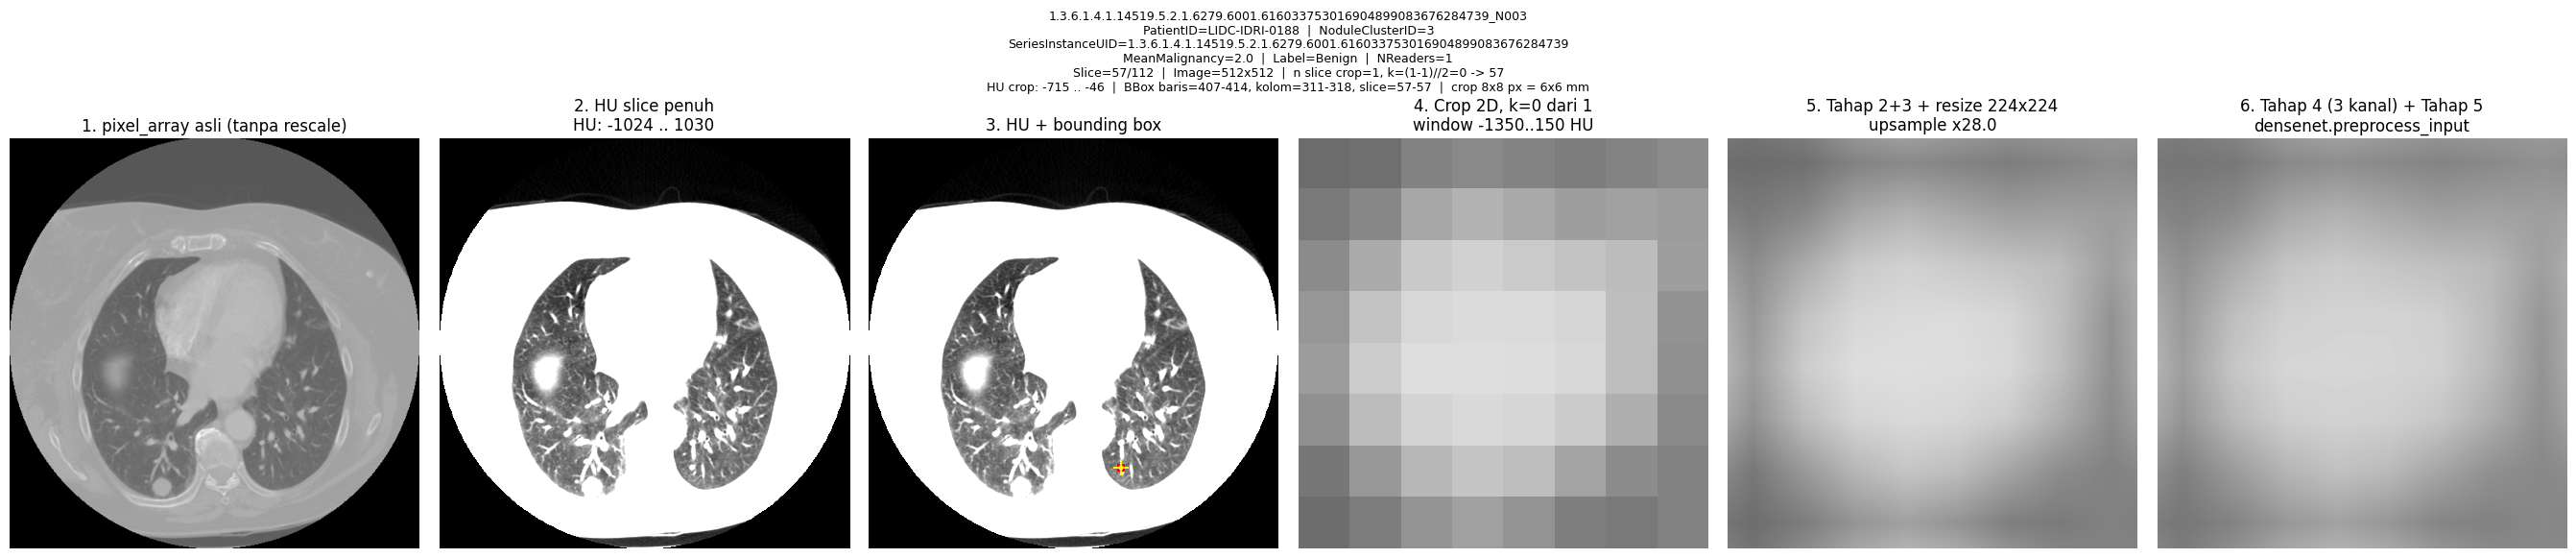

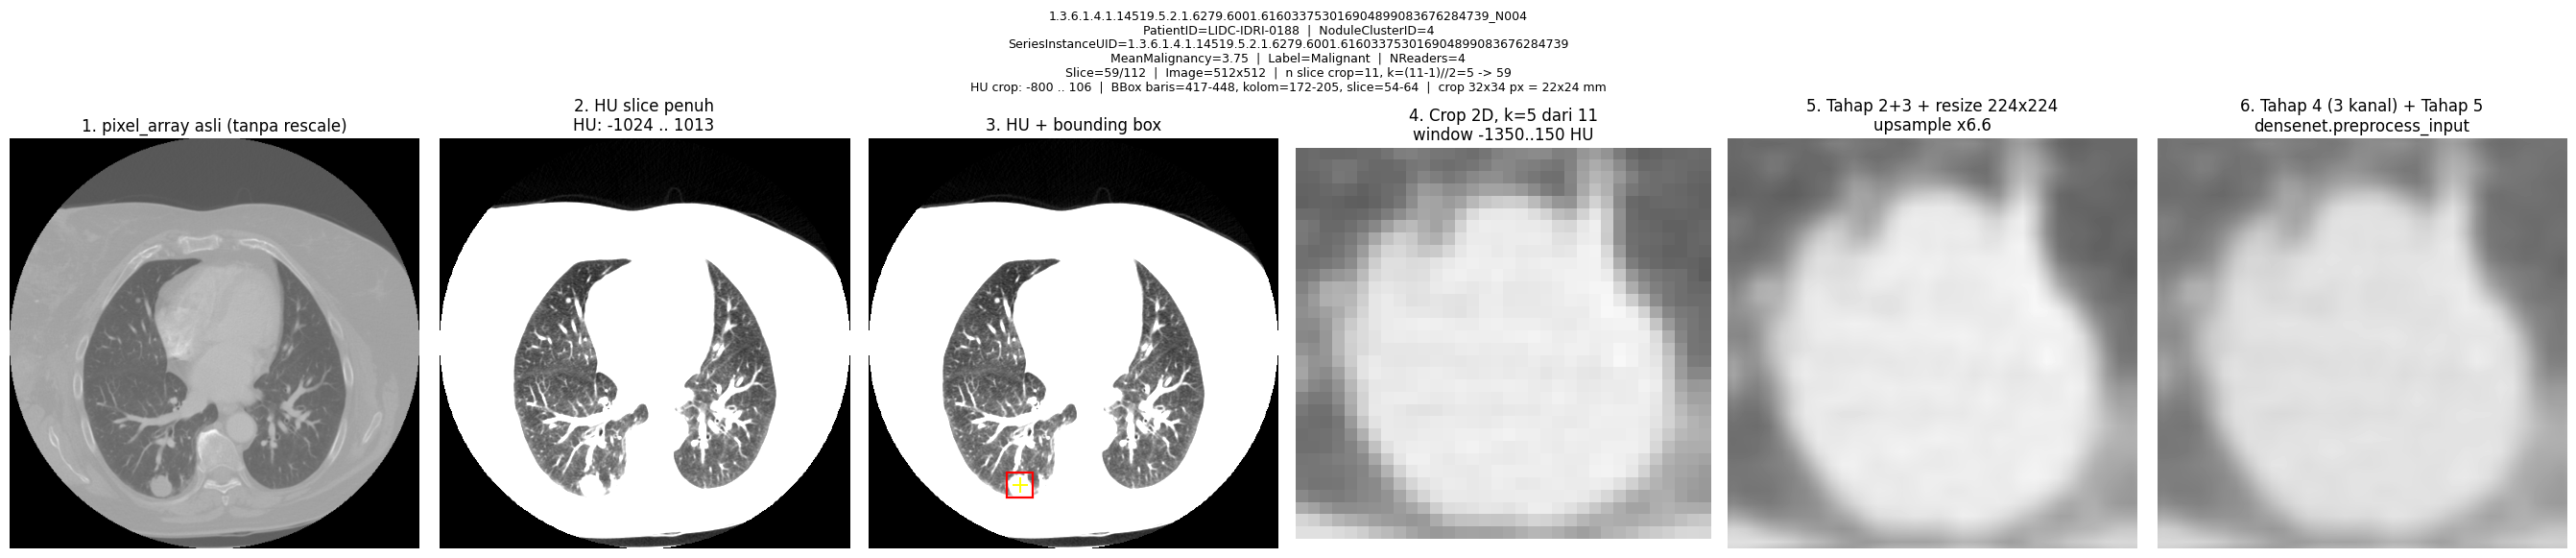

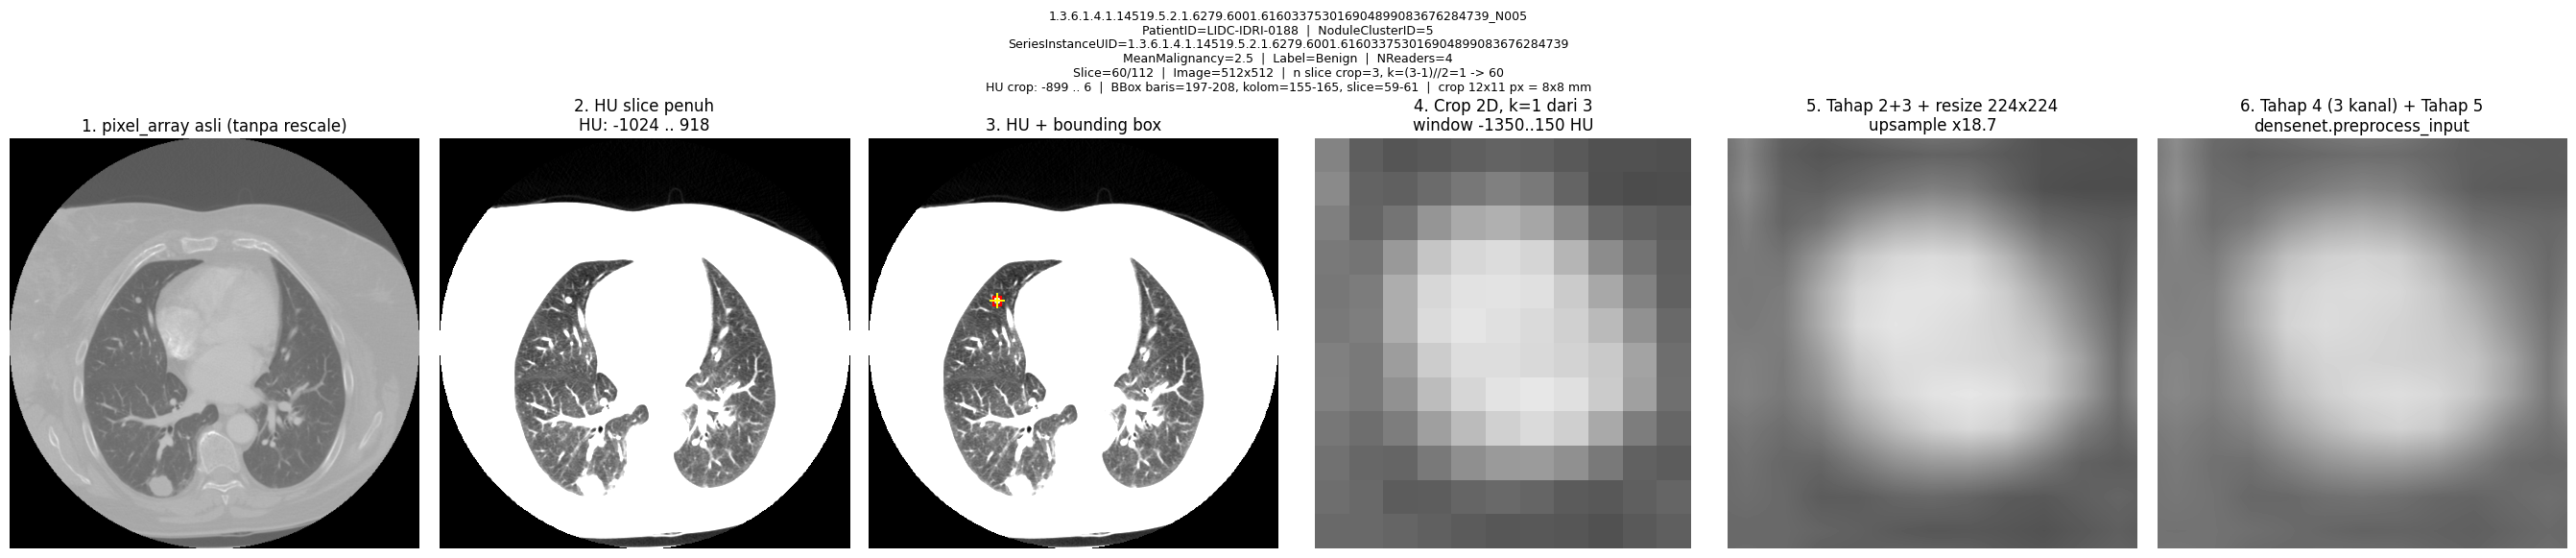

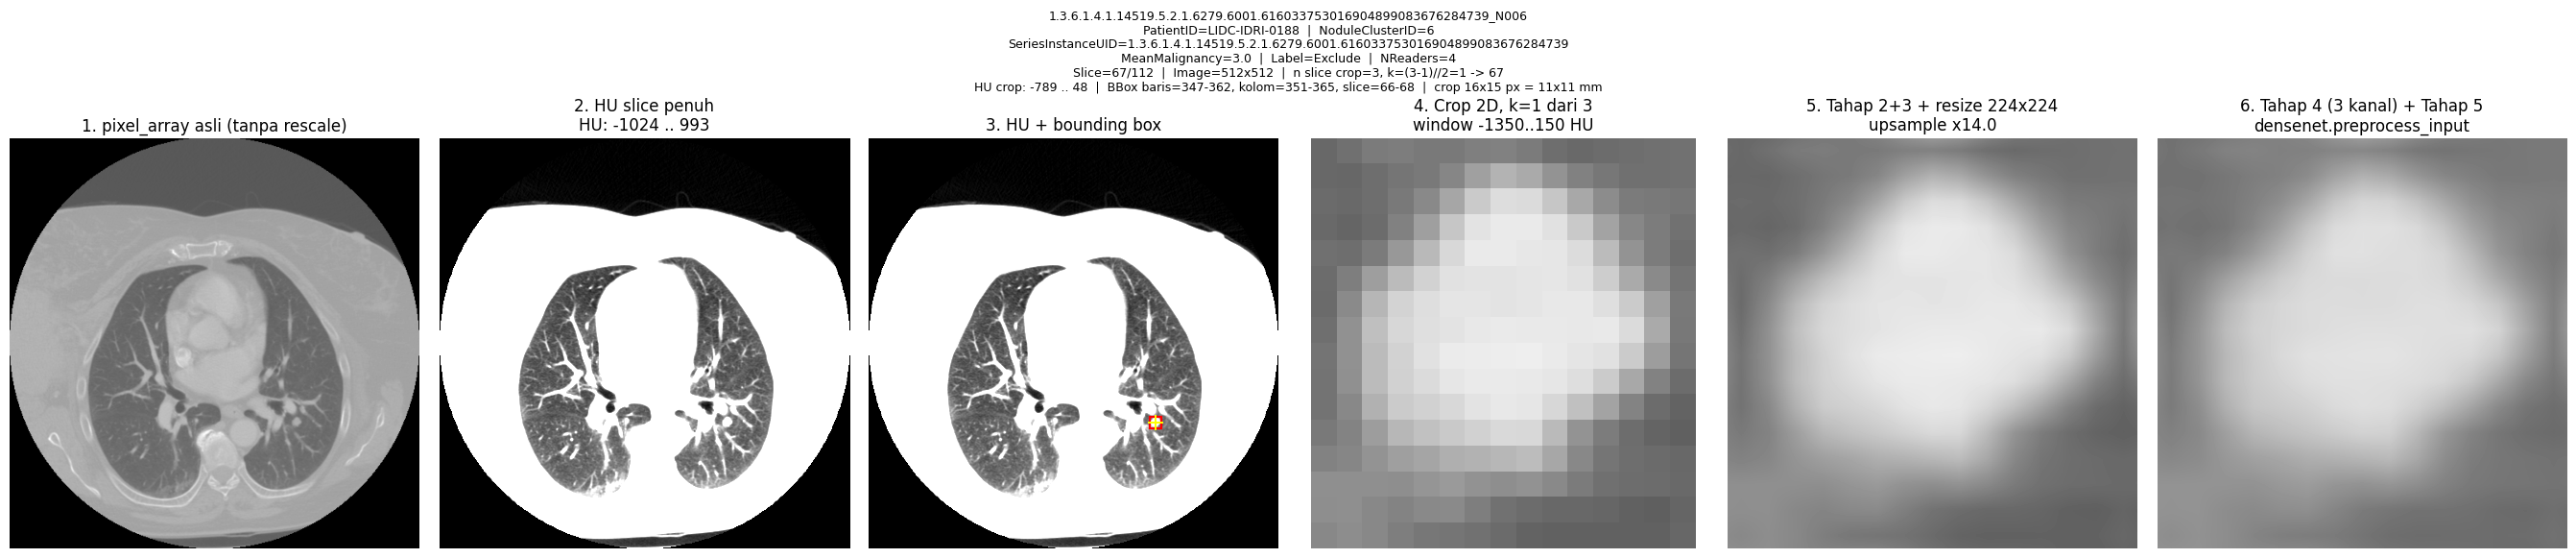

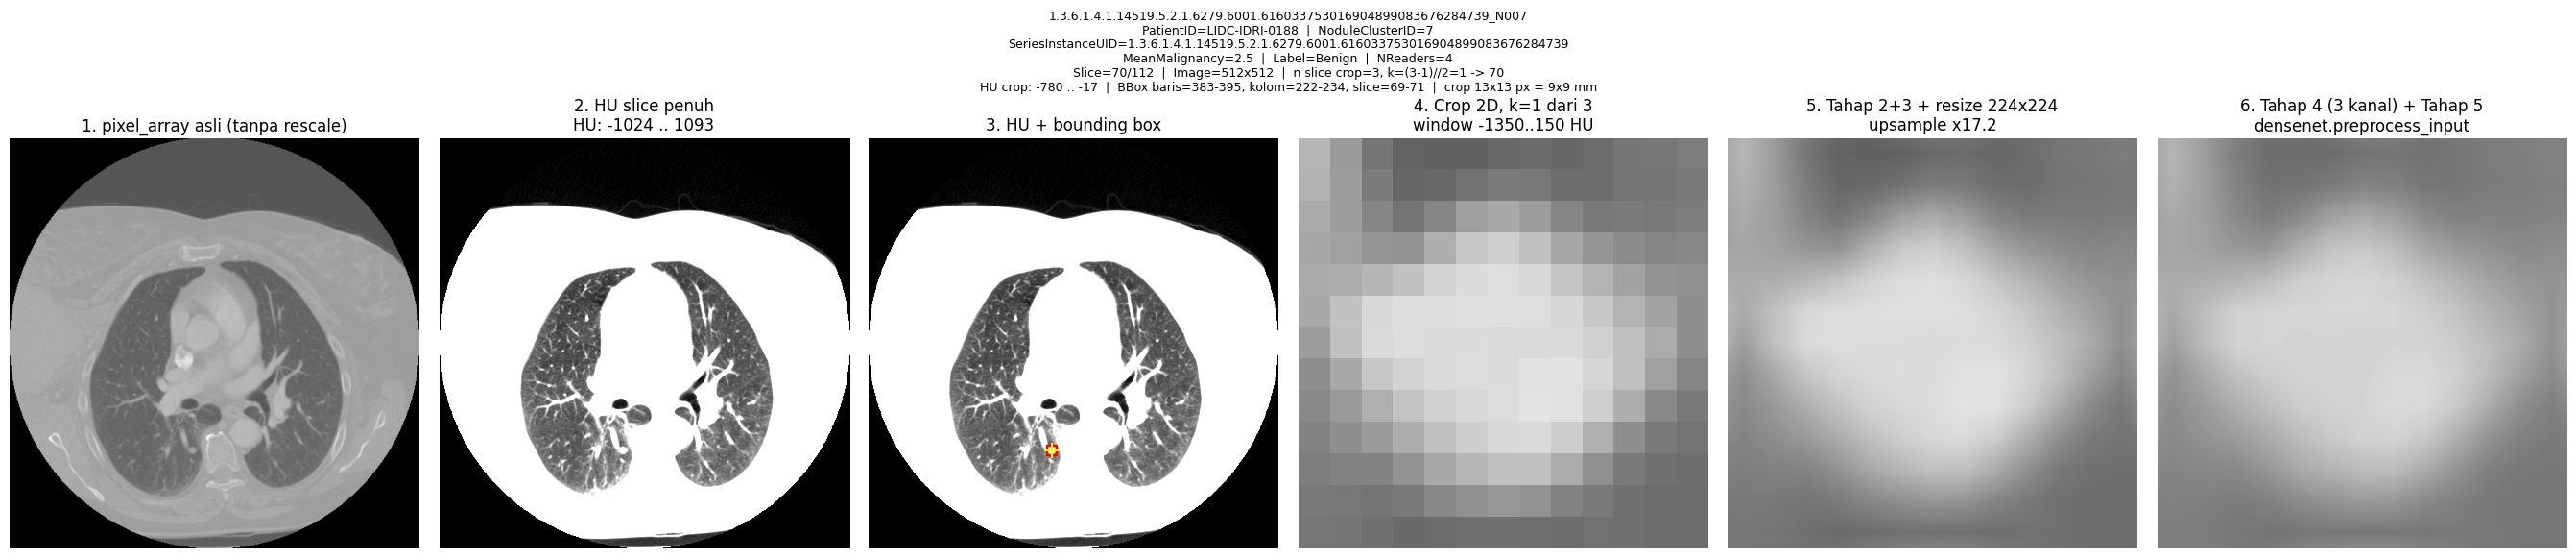

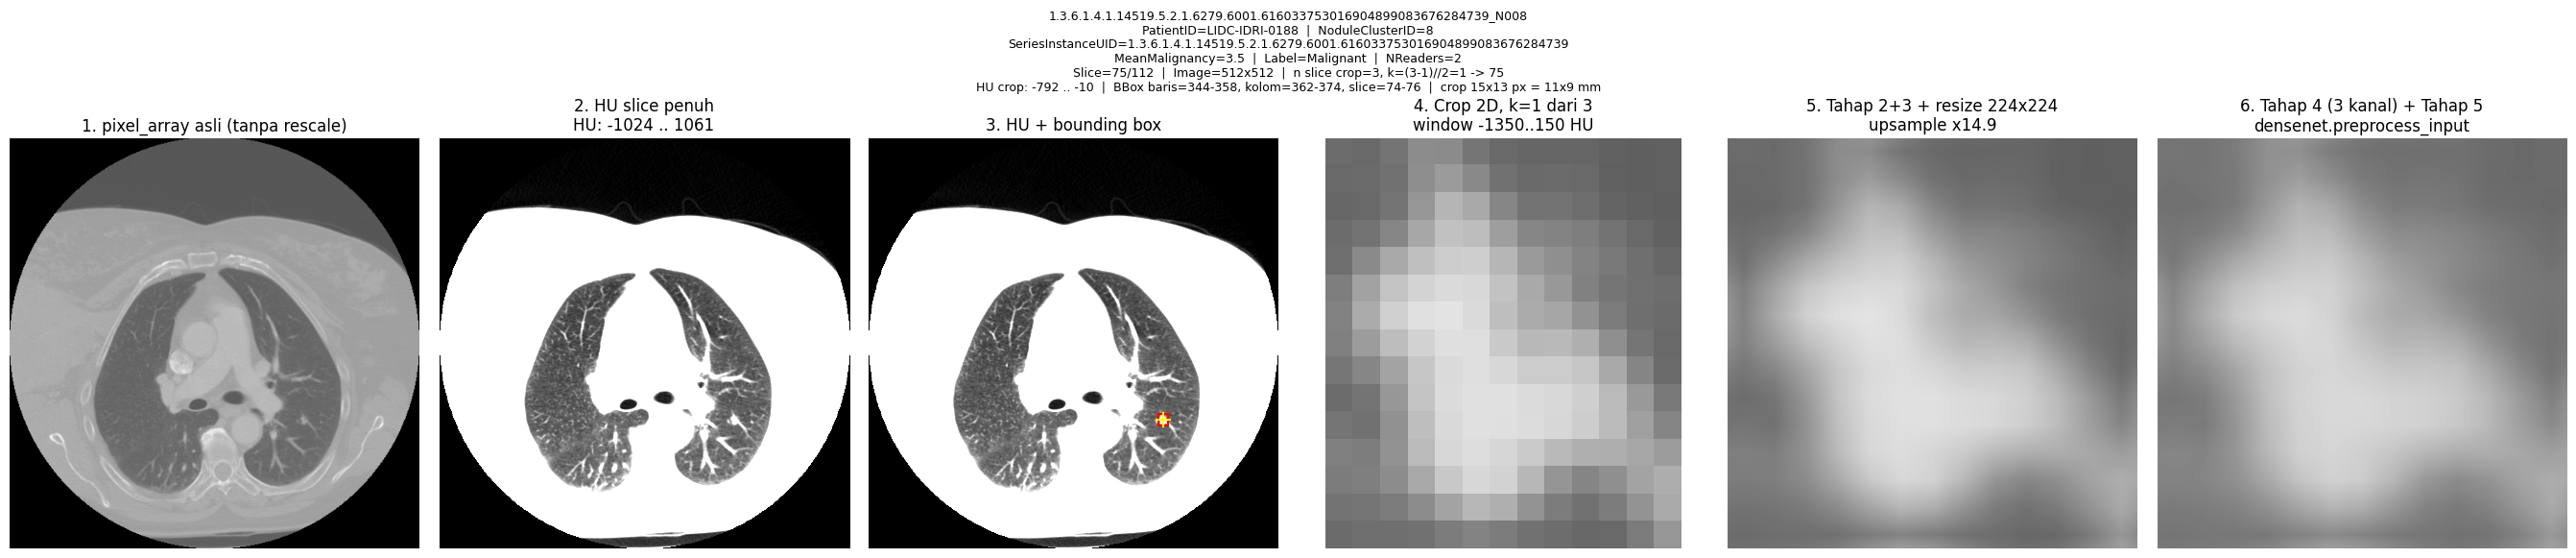

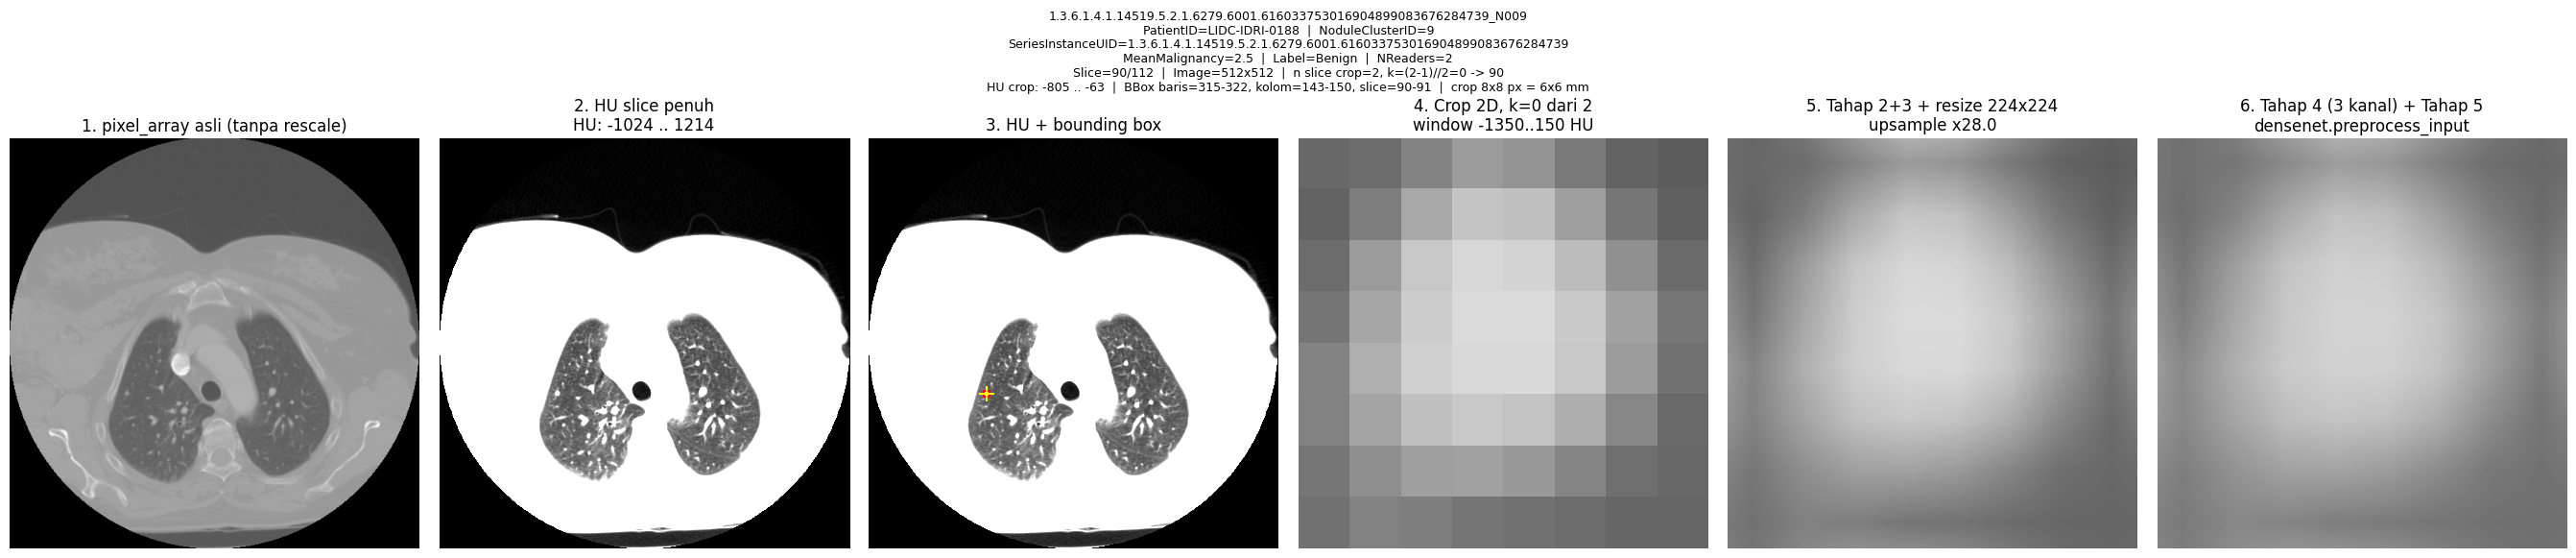

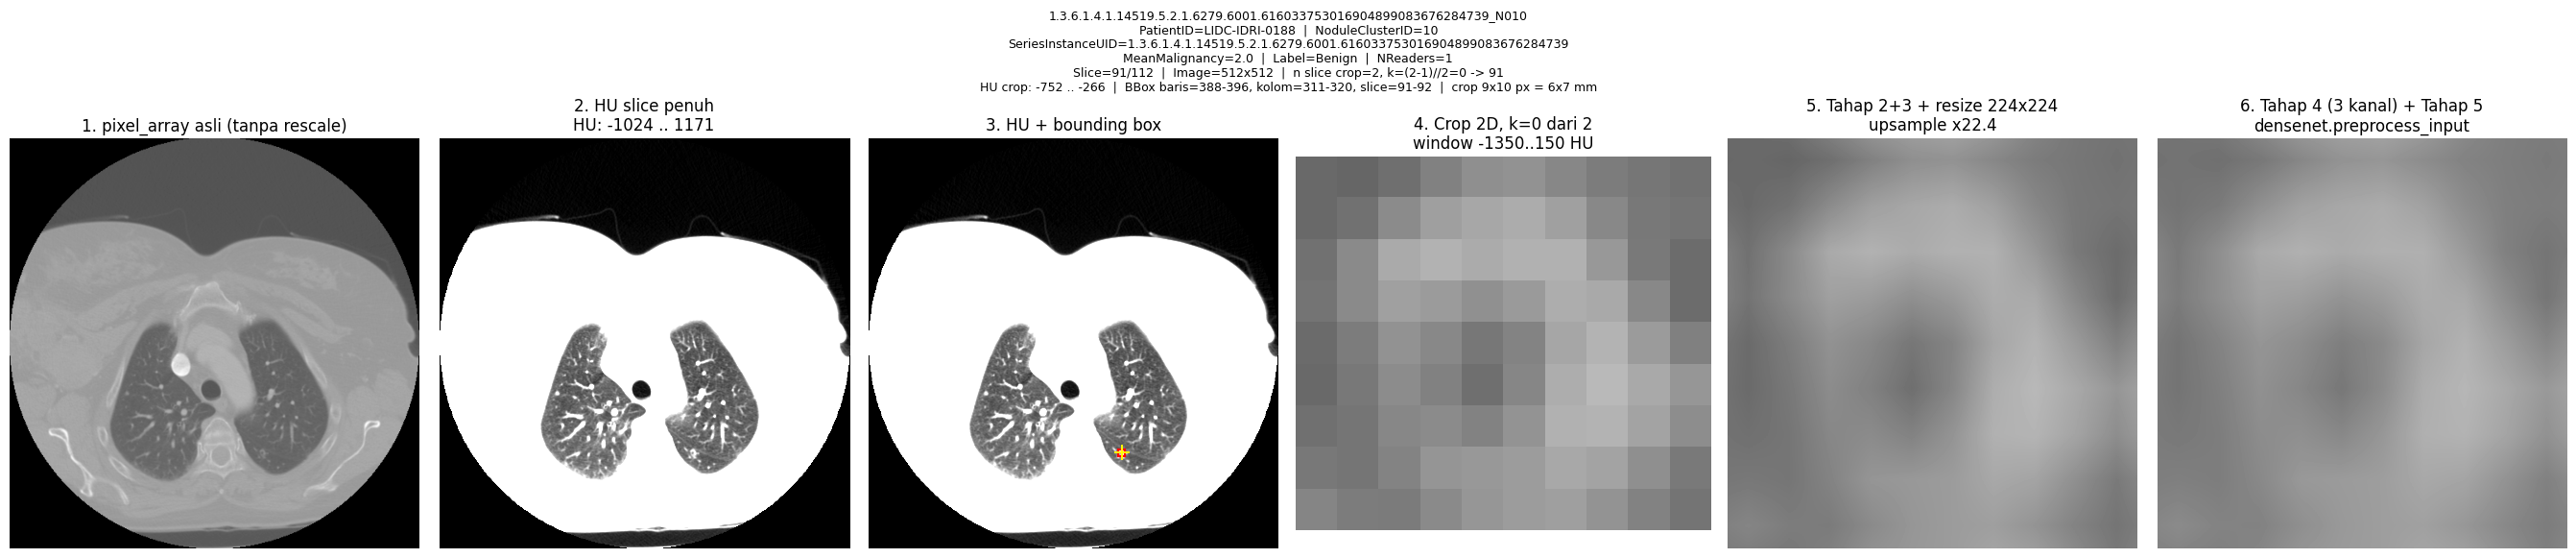

In [23]:
# ============================================================
# CELL 13.1 - VISUALISASI PER CLUSTER
# ============================================================

def plot_cluster(row, out, save=True):
    nid, b = row.NoduleID, out["box"]
    k = b["k_abs"]
    vals = fov_values(out["hu_slice"])
    n_z = b["n_slices_z"]

    info = (
        f"PatientID={row.PatientID}  |  NoduleClusterID={int(row.ClusterIndex)}\n"
        f"SeriesInstanceUID={row.SeriesInstanceUID}\n"
        f"MeanMalignancy={row.MeanMalignancy}  |  Label={row.Label}  |  "
        f"NReaders={int(row.NReaders)}\n"
        f"Slice={k}/{main_series.n_slices - 1}  |  Image={n_rows}x{n_cols}  |  "
        f"n slice crop={n_z}, k=({n_z}-1)//2={b['k_rel']} -> {k}\n"
        f"HU crop: {vals.min():.0f} .. {vals.max():.0f}  |  "
        f"BBox baris={b['core_r0']}-{b['core_r1']}, "
        f"kolom={b['core_c0']}-{b['core_c1']}, slice={b['z0']}-{b['z1']}  |  "
        f"crop {b['crop_h']}x{b['crop_w']} px = "
        f"{b['crop_h_mm']:.0f}x{b['crop_w_mm']:.0f} mm"
    )

    fig, axes = plt.subplots(1, 6, figsize=(27, 5.6))
    hu_full = hu_volume[k]

    axes[0].imshow(raw_slices[k], cmap="gray")
    axes[0].set_title("1. pixel_array asli (tanpa rescale)")

    axes[1].imshow(hu_full, cmap="gray", vmin=-1000, vmax=-400)
    axes[1].set_title(f"2. HU slice penuh\nHU: {fov_values(hu_full).min():.0f} .. "
                      f"{fov_values(hu_full).max():.0f}")

    axes[2].imshow(hu_full, cmap="gray", vmin=-1000, vmax=-400)
    axes[2].add_patch(Rectangle((b["c0"], b["r0"]), b["c1"] - b["c0"],
                                b["r1"] - b["r0"], fill=False,
                                ec="red", lw=1.6))
    axes[2].scatter([(b["core_c0"] + b["core_c1"]) / 2],
                    [(b["core_r0"] + b["core_r1"]) / 2],
                    marker="+", s=130, color="yellow", linewidths=1.4)
    axes[2].set_title("3. HU + bounding box")

    axes[3].imshow(out["windowed"], cmap="gray", vmin=0, vmax=1)
    axes[3].set_title(f"4. Crop 2D, k={b['k_rel']} dari {n_z}\n"
                      f"window {WINDOW_HU_MIN:.0f}..{WINDOW_HU_MAX:.0f} HU")

    axes[4].imshow(out["resized"], cmap="gray", vmin=0, vmax=1)
    axes[4].set_title(f"5. Tahap 2+3 + resize {TARGET_SIZE[0]}x{TARGET_SIZE[1]}\n"
                      f"upsample x{out['upsample_factor']:.1f}")

    axes[5].imshow(out["model_input"].mean(axis=0), cmap="gray",
                   vmin=-2.5, vmax=2.7)
    axes[5].set_title("6. Tahap 4 (3 kanal) + Tahap 5\n"
                      "densenet.preprocess_input")

    for ax in axes:
        ax.axis("off")
    fig.suptitle(f"{nid}\n{info}", fontsize=9, y=1.03)
    fig.tight_layout()

    path = None
    if save:
        safe = nid.replace(".", "_")[-70:]
        path = FIGURE_DIR / f"cluster_{int(row.ClusterIndex):02d}_{safe}.png"
        fig.savefig(path, dpi=110, bbox_inches="tight")
    if not DISPLAY_FIGURES_INLINE:
        plt.close(fig)
    return path


saved = [plot_cluster(row, results_by_id[row.NoduleID])
         for _, row in sample_ann.iterrows()]
print(f"{len(saved)} figure cluster disimpan ke "
      f"{FIGURE_DIR.relative_to(PROJECT_ROOT)}")

10 figure cakupan Z disimpan.


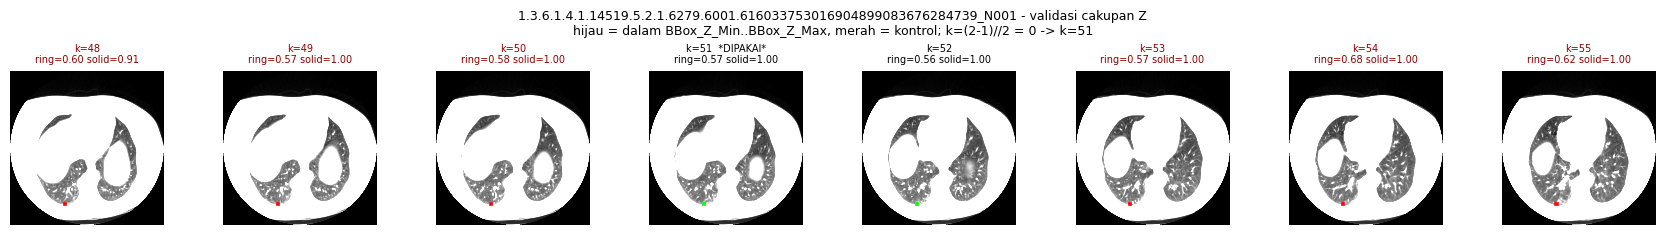

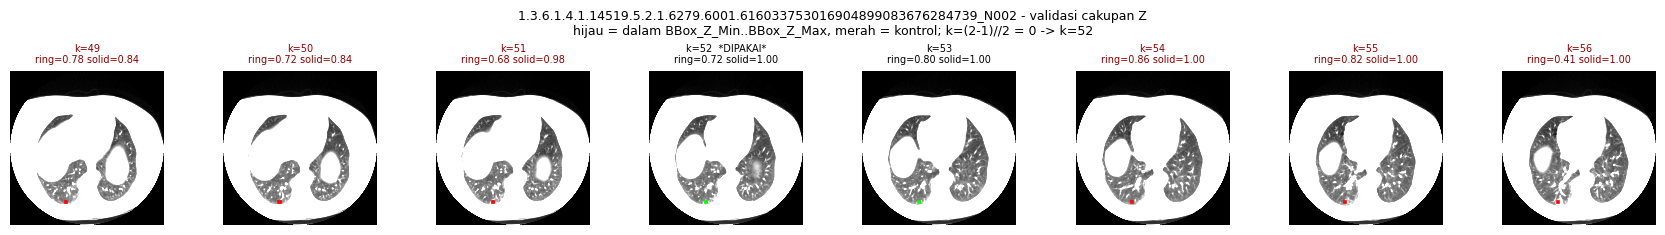

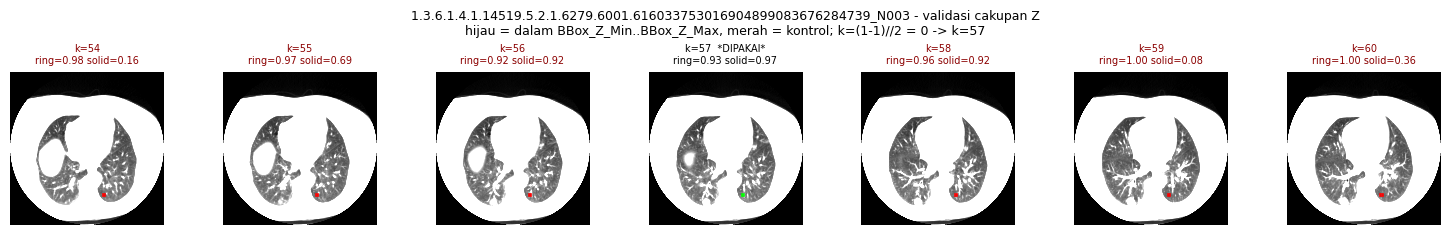

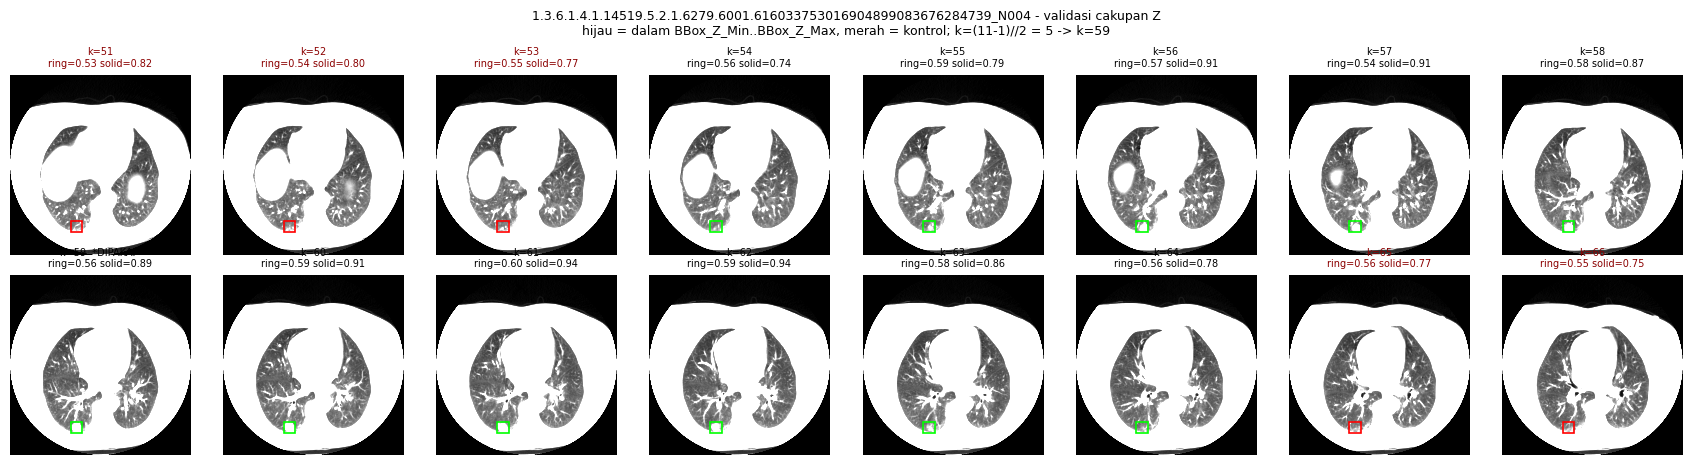

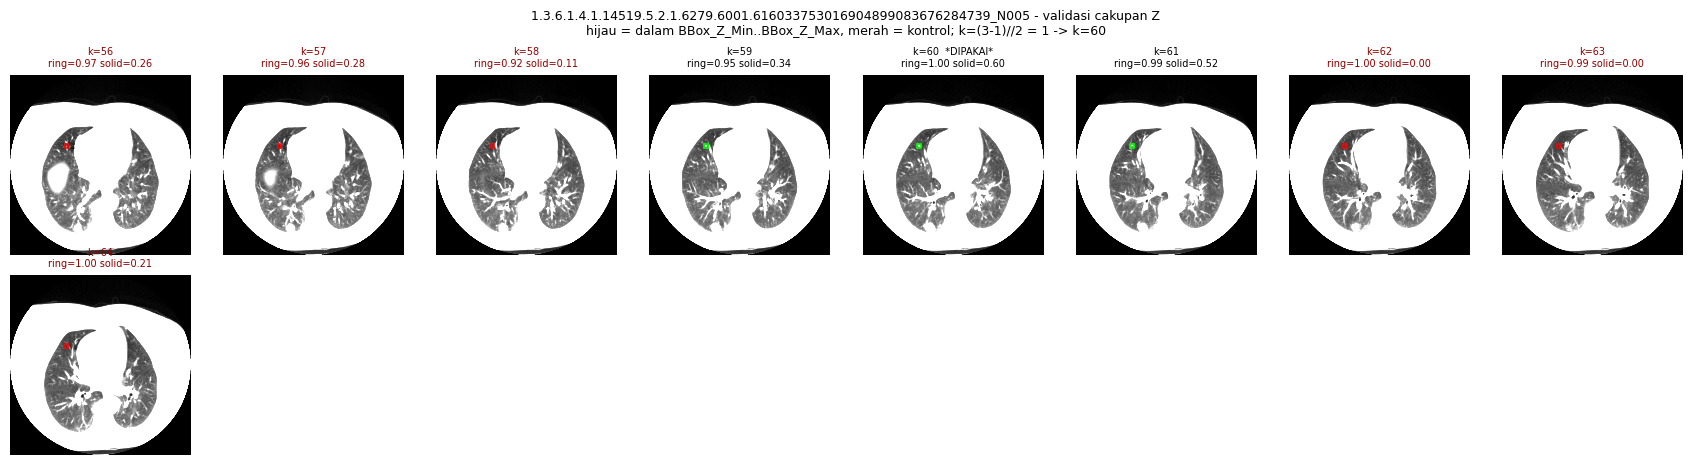

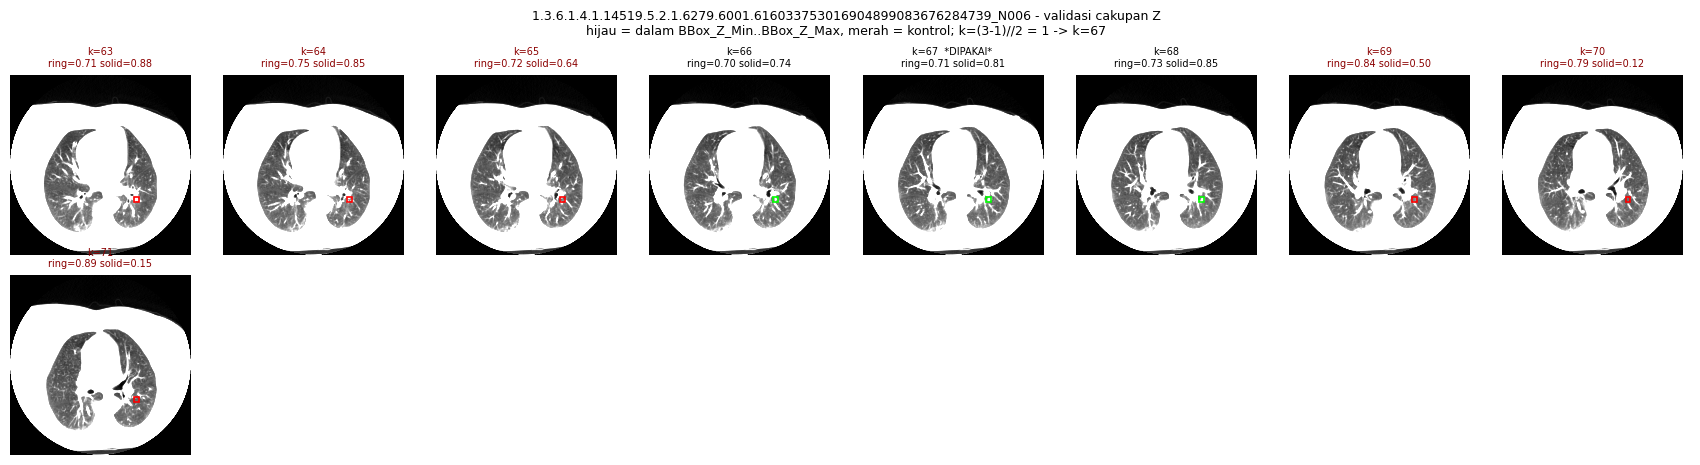

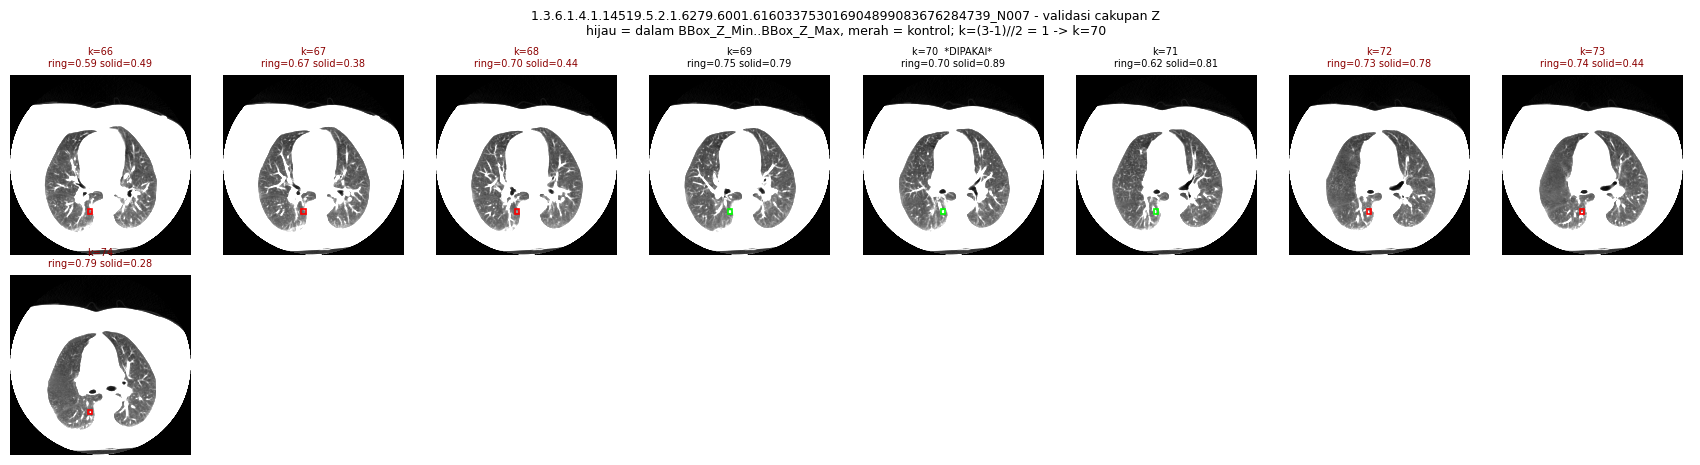

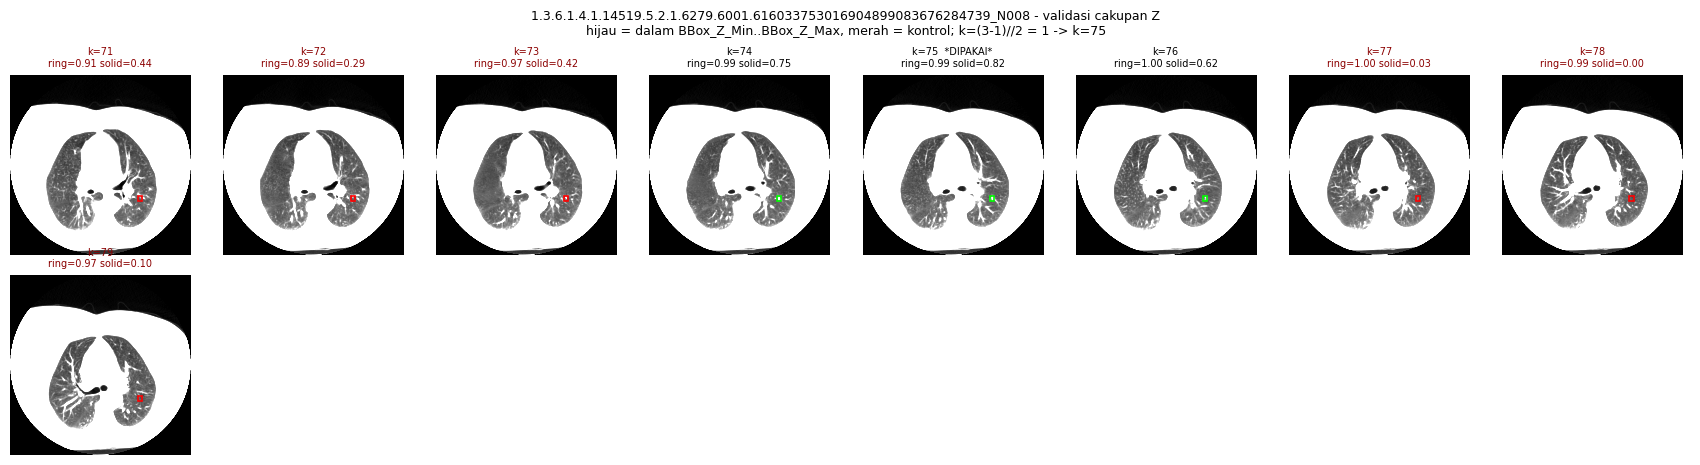

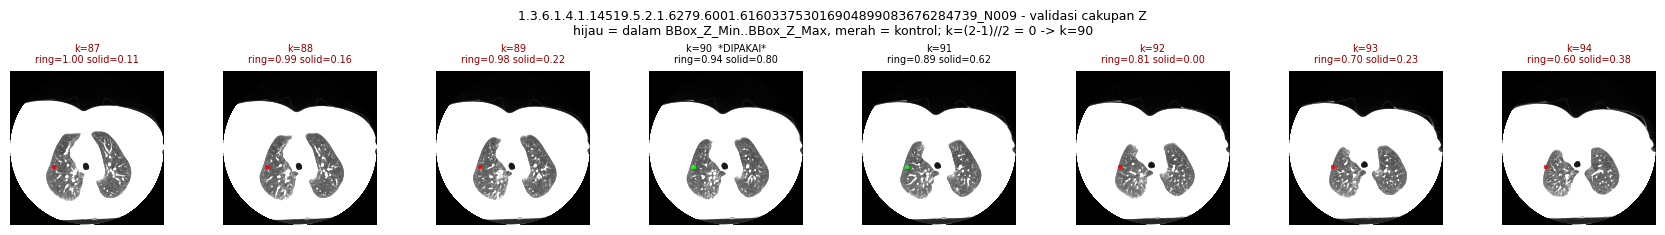

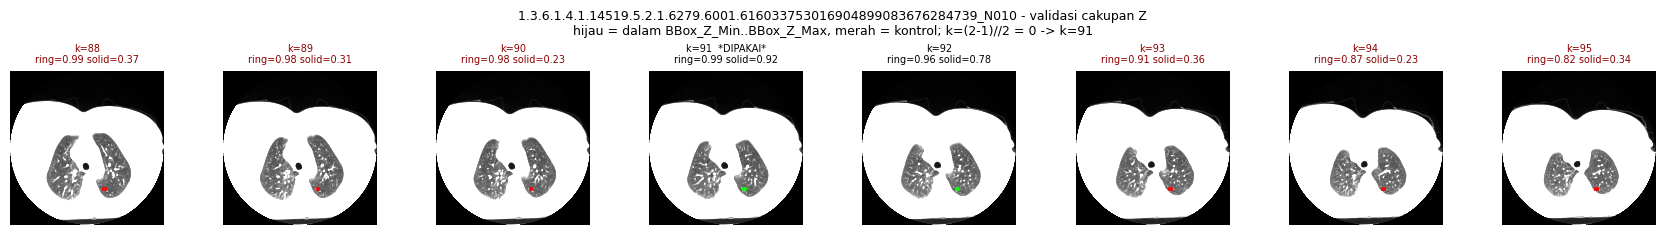

In [24]:
# ============================================================
# CELL 13.2 - VALIDASI CAKUPAN Z
# ============================================================

def plot_z_profile(row, out):
    b = out["box"]
    z0, z1 = b["z0"], b["z1"]
    pad = 3
    ks = list(range(max(0, z0 - pad), min(main_series.n_slices - 1, z1 + pad) + 1))
    in_ann = set(range(z0, z1 + 1))
    ks = ks[:16]

    ncol = min(8, len(ks))
    nrow = int(np.ceil(len(ks) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(2.15 * ncol, 2.35 * nrow))
    axes = np.atleast_1d(axes).ravel()

    for ax, k in zip(axes, ks):
        hu = hu_volume[k]
        ring_mask = build_ring_mask(hu.shape, b["core_r0"], b["core_r1"],
                                    b["core_c0"], b["core_c1"])
        ring_lung, box_solid = nodule_context_score(
            hu, b["core_r0"], b["core_r1"], b["core_c0"], b["core_c1"], ring_mask)
        ax.imshow(hu, cmap="gray", vmin=-1000, vmax=-400)
        ax.add_patch(Rectangle((b["core_c0"], b["core_r0"]),
                               b["core_c1"] - b["core_c0"],
                               b["core_r1"] - b["core_r0"], fill=False,
                               ec=("lime" if k in in_ann else "red"), lw=1.2))
        tag = "  *DIPAKAI*" if k == b["k_abs"] else ""
        ax.set_title(f"k={k}{tag}\nring={ring_lung:.2f} solid={box_solid:.2f}",
                     fontsize=7, color="black" if k in in_ann else "darkred")
        ax.axis("off")
    for ax in axes[len(ks):]:
        ax.axis("off")

    fig.suptitle(
        f"{row.NoduleID} - validasi cakupan Z\n"
        f"hijau = dalam BBox_Z_Min..BBox_Z_Max, merah = kontrol; "
        f"k=({b['n_slices_z']}-1)//2 = {b['k_rel']} -> k={b['k_abs']}", fontsize=9)
    fig.tight_layout()
    path = FIGURE_DIR / f"zprofile_{int(row.ClusterIndex):02d}.png"
    fig.savefig(path, dpi=105, bbox_inches="tight")
    if not DISPLAY_FIGURES_INLINE:
        plt.close(fig)
    return str(path)


z_paths = [plot_z_profile(row, results_by_id[row.NoduleID])
           for _, row in sample_ann.iterrows()]
print(f"{len(z_paths)} figure cakupan Z disimpan.")

## 14. Audit tiap tahap preprocessing

Menampilkan rentang nilai setelah setiap tahap untuk satu cluster contoh, dan
menuliskan rumus resmi DenseNet121 yang dipakai.

In [25]:
# ============================================================
# CELL 14 - AUDIT TAHAP
# ============================================================

sample_id = sample_ann["NoduleID"].iloc[0]
a_row = sample_ann[sample_ann["NoduleID"] == sample_id].iloc[0]
a_out = results_by_id[sample_id]
a_b = a_out["box"]
a_hu_crop = hu_volume[a_b["k_abs"]][a_b["r0"]:a_b["r1"] + 1,
                                   a_b["c0"]:a_b["c1"] + 1]

print(f"Contoh: NoduleClusterID={int(a_row.ClusterIndex)}  "
      f"Label={a_row.Label}  k={a_b['k_abs']}\n")

steps = [
    ("0. pixel_array (DICOM)", raw_slices[a_b["k_abs"]].astype(np.float32),
     "nilai tersimpan DICOM, belum rescale"),
    ("1. HU", a_hu_crop, "pixel * RescaleSlope + RescaleIntercept"),
    (f"2. window (clip ke {WINDOW_HU_MIN:.0f}..{WINDOW_HU_MAX:.0f} HU)",
     np.clip(a_hu_crop, WINDOW_HU_MIN, WINDOW_HU_MAX), "clipping ke window"),
    ("3. scaling ke [0,1]", a_out["windowed"],
     "(windowed - HU_MIN) / (HU_MAX - HU_MIN)"),
    (f"4. resize {TARGET_SIZE[0]}x{TARGET_SIZE[1]}", a_out["resized"],
     "interpolasi linear + anti-aliasing"),
    ("5. 3 kanal (replikasi)", a_out["input_3ch"], "grayscale diulang 3x"),
    ("6. DenseNet121 preprocess_input", a_out["model_input"],
     "mean/std ImageNet (mode='torch' di dalam Keras)"),
]
audit_tbl = pd.DataFrame([{
    "Tahap": nm, "Shape": str(arr.shape), "Min": float(arr.min()),
    "Max": float(arr.max()), "Mean": float(arr.mean()), "Keterangan": note,
} for nm, arr, note in steps])
print(audit_tbl.to_string(index=False))
print(f"\nKanal 1/2/3 identik (replikasi, bukan kanal semu): "
      f"{a_out['kanal_identik']}")

print("\n" + "=" * 78)
print("RUMUS TAHAP 5 - DenseNet121 PREPROCESSING (Keras, ImageNet)")
print("=" * 78)
print(f"""
  Tahap 1 (HU)      HU = pixel_array * RescaleSlope + RescaleIntercept
  Tahap 2 (window)  D   = clip(HU, {WINDOW_HU_MIN:.0f}, {WINDOW_HU_MAX:.0f})
  Tahap 3 (scaling) X01 = (D - ({WINDOW_HU_MIN:.0f})) / ({WINDOW_HU_MAX:.0f} - ({WINDOW_HU_MIN:.0f}))
  Tahap 4 (3 kanal) X3  = repeat(X01, 3, axis=0)
  Tahap 5 (model)   X[c] = (X3[c] - mean[c]) / std[c]
                        mean = {list(IMAGENET_MEAN_01)}
                        std  = {list(IMAGENET_STD_01)}

  Fungsi yang direplikasi:
      tf.keras.applications.densenet.preprocess_input
      -> secara internal: imagenet_utils.preprocess_input(x, mode="torch")

  CATATAN 1 - Resize(256) + CenterCrop(224) TIDAK dipakai.
     Crop nodule sudah merupakan area input. CenterCrop tambahan akan
     membuang bagian nodule. Ini penyimpangan yang disengaja dan dicatat
     di metodologi.

  CATATAN 2 - Jalur caffe/BGR (RGB->BGR lalu kurangi
     {list(IMAGENET_MEAN_255_CAFFE)}) BUKAN yang dipakai DenseNet Keras.
     Jalur itu milik mode="caffe" pada imagenet_utils umum.
""")

Contoh: NoduleClusterID=1  Label=Benign  k=51

                            Tahap         Shape          Min        Max        Mean                                      Keterangan
           0. pixel_array (DICOM)    (512, 512) -2048.000000 930.000000 -652.154846            nilai tersimpan DICOM, belum rescale
                            1. HU        (8, 8)  -629.000000 -26.000000 -297.531250         pixel * RescaleSlope + RescaleIntercept
2. window (clip ke -1350..150 HU)        (8, 8)  -629.000000 -26.000000 -297.531250                              clipping ke window
              3. scaling ke [0,1]        (8, 8)     0.480667   0.882667    0.701646         (windowed - HU_MIN) / (HU_MAX - HU_MIN)
                4. resize 224x224    (224, 224)     0.481657   0.882561    0.704209              interpolasi linear + anti-aliasing
           5. 3 kanal (replikasi) (3, 224, 224)     0.481657   0.882561    0.704209                            grayscale diulang 3x
  6. DenseNet121 preprocess_i

## 15. Verifikasi terhadap DenseNet121 Keras yang terpasang

Tiga hal diverifikasi:

1. **Rumus NumPy di notebook ini identik** dengan
   `tf.keras.applications.densenet.preprocess_input` yang terpasang.
2. **Jalur mode** yang dipakai fungsi tersebut, dibaca dari source Keras,
   sehingga notebook tidak bergantung pada asumsi.
3. **Model target** `tf.keras.applications.DenseNet121(weights="imagenet")`
   benar-benar bisa dibuat, dan bentuk inputnya cocok dengan `(3, 224, 224)`.

Cell **berhenti dengan error** bila rumus tidak cocok, sehingga kesalahan
jalur preprocessing tidak bisa lolos diam-diam.

In [26]:
# ============================================================
# CELL 15 - VERIFIKASI DENSENET121 KERAS
# ============================================================

import inspect
import tensorflow as tf

print("=" * 78)
print("VERIFIKASI TAHAP 5 - DenseNet121 (Keras)")
print("=" * 78)
print(f"tensorflow : {tf.__version__}")
print(f"keras      : {tf.keras.__version__}")

# -- 1) baca jalur mode dari source Keras, jangan diasumsikan -------------
dense_mod = __import__("keras.applications.densenet", fromlist=["x"])
src = inspect.getsource(dense_mod.preprocess_input)
mode_match = "torch" if 'mode="torch"' in src else (
    "caffe" if 'mode="caffe"' in src else "tidak diketahui")
print(f"\n[1] Jalur mode yang dipakai densenet.preprocess_input : {mode_match!r}")
print("    source:")
for line in src.strip().splitlines():
    print("      " + line)

if mode_match != "torch":
    raise ValueError(
        f"Keras terpasang memakai mode={mode_match!r} untuk DenseNet, "
        f"sedangkan implementasi notebook memakai mean/std ImageNet "
        f"(mode 'torch'). Periksa versi Keras dan sesuaikan Cell 9 "
        f"SEBELUM memakai hasil preprocessing.")

# -- 2) bandingkan rumus NumPy dengan fungsi Keras -----------------------
rng = np.random.default_rng(11)
probe = rng.random((NUM_CHANNELS,) + TARGET_SIZE, dtype=np.float32)
batch_last = (probe.transpose(1, 2, 0)[None] * 255.0).astype(np.float32)

keras_ref = np.transpose(
    tf.keras.applications.densenet.preprocess_input(batch_last.copy()),
    (0, 3, 1, 2))[0]
mine = keras_densenet_preprocess_input(probe)
diff = float(np.abs(mine - keras_ref).max())
print(f"\n[2] max |implementasi notebook - densenet.preprocess_input| = {diff:.3e}")
if diff > 1e-4:
    raise ValueError(
        f"Rumus NumPy TIDAK cocok dengan Keras (selisih {diff:.3e}). "
        f"Jangan memakai hasil preprocessing sebelum diperbaiki.")
print("    IDENTIK.")

# uji juga dengan data_format channels_first
keras_ref_cf = tf.keras.applications.densenet.preprocess_input(
    probe.copy(), data_format="channels_first")
diff_cf = float(np.abs(mine - keras_ref_cf).max())
print(f"    max |... - preprocess_input(data_format='channels_first')| "
      f"= {diff_cf:.3e}")
print("    Catatan: pada mode 'torch' TIDAK ada pembalikan urutan kanal,")
print("    sehingga channels_last dan channels_first memberikan hasil")
print("    identik. Perbedaan di atas hanya muncul karena Keras reversing")
print("    kanal pada mode 'caffe'. Model di sini memakai channels_last,")
print("    sesuai default tf.keras.applications.DenseNet121.")

# -- 3) model target ------------------------------------------------------
model = tf.keras.applications.DenseNet121(weights="imagenet")
print(f"\n[3] tf.keras.applications.DenseNet121(weights='imagenet')")
print(f"    input_shape  : {model.input_shape}")
print(f"    output_shape : {model.output_shape}")
print(f"    jumlah parameter : {model.count_params():,}")
print(f"    layer pertama    : {type(model.layers[1]).__name__}")

expected_input = (None, TARGET_SIZE[0], TARGET_SIZE[1], NUM_CHANNELS)
if tuple(model.input_shape) != expected_input:
    raise ValueError(
        f"Bentuk input DenseNet121 {model.input_shape} tidak cocok dengan "
        f"preprocessing {expected_input}.")
print(f"    bentuk input cocok dengan (3, {TARGET_SIZE[0]}, {TARGET_SIZE[1]}) "
      f"channels-last: YA")

# sanity: citra preprocessing harus bisa melewati model
logits = model.predict(probe.transpose(1, 2, 0)[None], verbose=0)
print(f"    forward pass OK, logits shape {logits.shape}, "
      f"rentang {logits.min():.2f} .. {logits.max():.2f}")
print("\nSemua verifikasi lolos.")

VERIFIKASI TAHAP 5 - DenseNet121 (Keras)
tensorflow : 2.21.0
keras      : 3.15.1

[1] Jalur mode yang dipakai densenet.preprocess_input : 'torch'
    source:
      @keras_export("keras.applications.densenet.preprocess_input")
      def preprocess_input(x, data_format=None):
          return imagenet_utils.preprocess_input(
              x, data_format=data_format, mode="torch"
          )

[2] max |implementasi notebook - densenet.preprocess_input| = 7.153e-07
    IDENTIK.
    max |... - preprocess_input(data_format='channels_first')| = 4.447e+00
    Catatan: pada mode 'torch' TIDAK ada pembalikan urutan kanal,
    sehingga channels_last dan channels_first memberikan hasil
    identik. Perbedaan di atas hanya muncul karena Keras reversing
    kanal pada mode 'caffe'. Model di sini memakai channels_last,
    sesuai default tf.keras.applications.DenseNet121.



[3] tf.keras.applications.DenseNet121(weights='imagenet')
    input_shape  : (None, 224, 224, 3)
    output_shape : (None, 1000)
    jumlah parameter : 8,062,504
    layer pertama    : ZeroPadding2D
    bentuk input cocok dengan (3, 224, 224) channels-last: YA


    forward pass OK, logits shape (1, 1000), rentang 0.00 .. 0.03

Semua verifikasi lolos.


## 16. Simpan sample (bukan batch)

Hanya seri utama. Folder `dataset/04_preprocessed/sample/` sudah di-ignore
Git.

In [27]:
# ============================================================
# CELL 16 - SIMPAN SAMPLE
# ============================================================

SAMPLE_INDEX_DIR.mkdir(parents=True, exist_ok=True)

index_records = []
for _, row in sample_ann.iterrows():
    out = results_by_id[row.NoduleID]
    b = out["box"]
    safe = row.NoduleID.replace(".", "_")[-70:]
    vals = fov_values(out["hu_slice"])

    np.save(SAMPLE_INDEX_DIR / f"{safe}_3ch_224x224.npy", out["input_3ch"])
    np.save(SAMPLE_INDEX_DIR / f"{safe}_densenet_input.npy", out["model_input"])

    index_records.append({
        "PatientID": row.PatientID,
        "SeriesInstanceUID": row.SeriesInstanceUID,
        "NoduleClusterID": int(row.ClusterIndex),
        "NoduleID": row.NoduleID,
        "NReaders": int(row.NReaders),
        "MeanMalignancy": float(row.MeanMalignancy),
        "Label": row.Label,
        "BBox_Baris_Min": b["core_r0"], "BBox_Baris_Max": b["core_r1"],
        "BBox_Kolom_Min": b["core_c0"], "BBox_Kolom_Max": b["core_c1"],
        "BBox_Slice_Min": b["z0"], "BBox_Slice_Max": b["z1"],
        "N_Slice_Crop": b["n_slices_z"],
        "K_Slice_Dalam_Crop": b["k_rel"],
        "Slice_Dipakai": b["k_abs"],
        "Aturan_Slice": SLICE_SELECTION,
        "Margin_px": CONTEXT_MARGIN_PX,
        "Ukuran_Crop_px": [b["crop_h"], b["crop_w"]],
        "Ukuran_Crop_mm": [round(b["crop_h_mm"], 1), round(b["crop_w_mm"], 1)],
        "Ukuran_Input": list(out["input_3ch"].shape),
        "HU_Min": float(vals.min()), "HU_Max": float(vals.max()),
        "Faktor_Upsample": round(out["upsample_factor"], 2),
        "File_3ch": f"{safe}_3ch_224x224.npy",
        "File_Densenet_Input": f"{safe}_densenet_input.npy",
    })

with open(SAMPLE_INDEX_DIR / "sample_index.json", "w", encoding="utf-8") as f:
    json.dump({
        "sample_series_uid": sample_uid,
        "patient_id": sample_ann["PatientID"].iloc[0],
        "jumlah_slice_volume": main_series.n_slices,
        "ukuran_image_baris_kolom": [n_rows, n_cols],
        "pixel_spacing_mm": [row_spacing, col_spacing],
        "slice_spacing_mm": round(slice_spacing_mm, 4),
        "pipeline": {
            "tahap_1_hu": "pixel * RescaleSlope + RescaleIntercept",
            "tahap_2_window_hu": [WINDOW_HU_MIN, WINDOW_HU_MAX],
            "tahap_3_scaling": "ke [0, 1]",
            "tahap_4_channel": "replikasi grayscale ke 3 kanal",
            "tahap_5": ("tf.keras.applications.densenet.preprocess_input "
                        "(internal mode='torch' = mean/std ImageNet)"),
        },
        "context_margin_px_SEMENTARA": CONTEXT_MARGIN_PX,
        "slice_selection": SLICE_SELECTION,
        "bbox_xy_convention": BBOX_XY_CONVENTION,
        "nodule": index_records,
    }, f, indent=2, ensure_ascii=False)

print(f"Disimpan : {len(index_records)} cluster (seri utama saja)")
print(f"Lokasi   : {SAMPLE_INDEX_DIR.relative_to(PROJECT_ROOT)}")

Disimpan : 10 cluster (seri utama saja)
Lokasi   : dataset/04_preprocessed/sample


## 17. Ringkasan parameter

In [28]:
# ============================================================
# CELL 17 - RINGKASAN PARAMETER
# ============================================================

params = {
    "PROJECT_ROOT": str(PROJECT_ROOT),
    "SAMPLE_SERIES_UID": sample_uid,
    "PatientID": sample_ann["PatientID"].iloc[0],
    "TAHAP 1 RescaleSlope": main_series.rescale_slope,
    "TAHAP 1 RescaleIntercept": main_series.rescale_intercept,
    "TAHAP 2 window": f"lung HU_MIN={WINDOW_HU_MIN} HU_MAX={WINDOW_HU_MAX}",
    "TAHAP 2 level (setara)": WINDOW_LEVEL,
    "TAHAP 2 width (setara)": WINDOW_WIDTH,
    "TAHAP 2 adaptive": "tidak dipakai",
    "TAHAP 3 scaling": "ke [0, 1]",
    "TAHAP 4 channel": "replikasi grayscale ke 3 kanal",
    "TAHAP 5 fungsi": "tf.keras.applications.densenet.preprocess_input",
    "TAHAP 5 mode internal": "torch (mean/std ImageNet) - diverifikasi Cell 15",
    "TAHAP 5 mean": list(IMAGENET_MEAN_01),
    "TAHAP 5 std": list(IMAGENET_STD_01),
    "ImageNet Resize/CenterCrop": "TIDAK dipakai (disengaja)",
    "Ukuran input": f"{TARGET_SIZE[0]} x {TARGET_SIZE[1]}",
    "Representasi 2D": "satu axial slice dari crop 3D",
    "Aturan slice": f"{SLICE_SELECTION} -> (n-1)//2",
    "Margin-mm kandidat": list(MARGIN_MM_CANDIDATES),
    "Margin-px pembanding": list(MARGIN_PX_CANDIDATES),
    "Margin dipakai (PLACEHOLDER, belum dikunci)": CONTEXT_MARGIN_PX,
    "Margin final": "BELUM DIKUNCI - menunggu audit penuh di PC Lab",
    "Fungsi audit reusable": "evaluate_margin_candidates()",
    "Konvensi bbox": f"{BBOX_XY_CONVENTION} (BBox_X=baris, BBox_Y=kolom)",
    "Urutan slice": "ascending ImagePositionPatient pada normal (k=0 inferior)",
    "Jumlah slice volume": main_series.n_slices,
    "Ukuran image": f"{n_rows} x {n_cols}",
    "Pixel spacing (mm)": f"{row_spacing} x {col_spacing}",
    "Slice spacing (mm)": round(slice_spacing_mm, 4),
    "Slice thickness (mm)": main_series.slice_thickness,
    "ImageOrientationPatient": [float(v) for v in iop],
    "Audit: seri diproses": len(audit_series_cache),
    "Audit: cluster diproses": int(margin_audit["NoduleID"].nunique())
    if "NoduleID" in margin_audit.columns
    else int(margin_audit.groupby(["SeriesInstanceUID",
                                   "NoduleClusterID"]).ngroups),
    "Audit: total cluster di annotation": len(ann),
    "Python": sys.version.split()[0],
    "Library": {name: importlib.import_module(name).__version__
                for name in {**REQUIRED, **REQUIRED_MODEL}},
}

for key, value in params.items():
    print(f"{key:<34} : {value}")

with open(FIGURE_DIR / "preprocessing_parameters.json", "w",
          encoding="utf-8") as f:
    json.dump(params, f, indent=2, ensure_ascii=False, default=str)
print(f"\nDisimpan: "
      f"{(FIGURE_DIR / 'preprocessing_parameters.json').relative_to(PROJECT_ROOT)}")

PROJECT_ROOT                       : /Users/rivan/Kuliah/Skripsi/lung-nodule-classification
SAMPLE_SERIES_UID                  : 1.3.6.1.4.1.14519.5.2.1.6279.6001.616033753016904899083676284739
PatientID                          : LIDC-IDRI-0188
TAHAP 1 RescaleSlope               : 1.0
TAHAP 1 RescaleIntercept           : -1024.0
TAHAP 2 window                     : lung HU_MIN=-1350.0 HU_MAX=150.0
TAHAP 2 level (setara)             : -600.0
TAHAP 2 width (setara)             : 1500.0
TAHAP 2 adaptive                   : tidak dipakai
TAHAP 3 scaling                    : ke [0, 1]
TAHAP 4 channel                    : replikasi grayscale ke 3 kanal
TAHAP 5 fungsi                     : tf.keras.applications.densenet.preprocess_input
TAHAP 5 mode internal              : torch (mean/std ImageNet) - diverifikasi Cell 15
TAHAP 5 mean                       : [0.485, 0.456, 0.406]
TAHAP 5 std                        : [0.229, 0.224, 0.225]
ImageNet Resize/CenterCrop         : TIDAK dipakai (dis


## CATATAN — status keputusan

### SUDAH DIKUNCI

1. **Window** — lung window global, `HU_MIN = -1350`, `HU_MAX = 150`.
   Tidak adaptif, tidak per-cluster. Setara `level = -600`, `width = 1500`.
   Bukti di Cell 8.1: window mediastinal membuat citra 224x224 seluruhnya 0
   pada 2/10 cluster (LIDC-IDRI-0188) dan 5/15 cluster (LIDC-IDRI-0049).

2. **Konvensi bbox** — `BBox_X` = indeks **baris** (row),
   `BBox_Y` = indeks **kolom** (column), `BBox_Z` = indeks slice.
   File `dataset/02_annotations/pylidc_nodules_extracted.xlsx` **tidak diubah**.
   Validasi ulang otomatis di Cell 7, error bila tidak cocok dengan data.

3. **Aturan slice** — geometris, `middle_index = (n_slices - 1) // 2`.
   Ganjil = slice tengah, genap = lower-middle. Tidak ada `max_roi` dan
   tidak ada ambang HU dalam pemilihan slice.

   Alasan: contour per-slice LIDC tidak ada di repository, sehingga proxy
   berbasis intensitas CT tidak dapat direproduksi dari
   `pylidc_nodules_extracted.xlsx` saja, dan bisa berubah bila window atau
   ambang diubah. Aturan geometris hanya bergantung pada `BBox_Z_Min/Max`.

4. **Framework** — TensorFlow / Keras.

5. **Preprocessing model** — `tf.keras.applications.densenet.preprocess_input`.
   PENTING: fungsi tersebut secara internal memanggil
   `imagenet_utils.preprocess_input(x, mode="torch")`, yaitu **normalisasi
   ImageNet mean/std**:

   ```
   X[c] = (X[c] - mean[c]) / std[c]
   mean = [0.485, 0.456, 0.406]
   std  = [0.229, 0.224, 0.225]
   ```

   Jadi preprocessing resmi DenseNet121 di Keras **ekuivalen** dengan
   normalisasi ImageNet mean/std, dan **bukan** jalur caffe/BGR.
   Jalur caffe (RGB->BGR lalu kurangi `[103.939, 116.779, 123.68]`) milik
   `mode="caffe"` pada `imagenet_utils` umum dan tidak dipakai DenseNet.

   Notebook membaca mode tersebut dari source Keras saat runtime
   (Cell 15) dan berhenti dengan error bila bukan `"torch"`, sehingga
   perubahan versi Keras tidak bisa mengubah preprocessing diam-diam.
   `Resize(256) + CenterCrop(224)` ImageNet sengaja tidak dipakai.

6. **Aturan axis** — HU -> lung window -> scaling [0,1] -> 3 kanal ->
   DenseNet121 `preprocess_input`. Kanal 1/2/3 adalah replikasi grayscale.

### BELUM DIKUNCI

7. **Margin konteks.** Tetap `0` sebagai **placeholder**. Ini **bukan**
   keputusan metodologi. Audit kandidat `0 / 3 / 5 / 8 mm` (dilengkapi
   pembanding fixed-piksel) tersedia melalui fungsi reusable
   `evaluate_margin_candidates()` pada Cell 11.

   Fungsi ini Designed untuk dipanggil ulang di PC Lab setelah seluruh
   dataset CT tersedia, **tanpa perubahan kode**:

   ```
   table, errors, cache = evaluate_margin_candidates(
       ann, discover_series(Path("dataset/01_raw")),
       margin_mm_candidates=(0.0, 3.0, 5.0, 8.0),
       margin_px_candidates=(0, 16, 32),
   )
   ```

   Kriteria audit yang sudah ensured ada: actual margin mm, crop size
   pixel, crop size mm, faktor upsample, persentase crop < 32 px dan
   < 48 px, `frac_airy`, `frac_context_soft`, image std, serta distribusi
   per series / per pixel spacing. Verifikasi otomatis di Cell 11.2.
   Tabel hasil tidak pernah memuat `Label` maupun `MeanMalignancy`.

   Pada laptop audit hanya mencakup 25 dari 837 cluster dengan 2 nilai
   pixel spacing, sehingga **belum cukup** untuk mengunci margin.

### BELUM DIKERJAKAN

- batch crop final
- split dataset, 5-fold cross validation
- augmentation
- training DenseNet121
- Grad-CAM
- README metodologi final (ditunggu margin terkunci)
